# Concentration and Chains

**Companion notebook 01 for W43–W44 — The Probability Domain.**
Pairs with [Concentration and the Central Limit Theorem Explained](https://artifocial.com/blog/concentration-and-the-central-limit-theorem-explained-2026-oct-31)
(Part I below, sections `B1`–`B21`) and with the flagship
[The Probability Domain](https://artifocial.com/blog/probability-domain-2026-oct-22) (Part II, sections `§15`–`§31`;
Part III, `§32`–`§39`; Part IV, `§40`–`§46`; Part V, `§47`–`§49`; Part VI, `§50`–`§53`).

Pure NumPy and Matplotlib, CPU-only, float64, about three minutes end to end. As in
[`00_probability_from_scratch.ipynb`](./00_probability_from_scratch.ipynb), every cell is a section of one of the two
scripts that ship with the package, placed verbatim, and restores the generator state the script had there — so
the numbers printed are the ones the articles quote, whichever cell you run first — every helper and sample size a cell
needs (`binom_pmf`, `fit_logreg`, `N`) is in the setup cell, so any numbered cell runs on its own right after it. The figure cells
are the one exception: each plots the arrays of the experiment cell directly above it, so run that cell first.

### What this notebook establishes

1. **The central limit theorem has a speed**, and the speed is in *expected events*: Berry–Esseen measured against
   the exact binomial, the characteristic function doing the proof's work, and two heavy-tailed laws whose block
   means never become Gaussian.
2. **What each inequality knows.** Chebyshev (variance), Hoeffding (range), Bernstein (both) against the exact tail;
   on a 1% failure rate, Hoeffding's interval is wider than the rate it measures.
3. **Coverage is a frequency.** Ten thousand replicated intervals show the normal interval *and* Wilson's both cover about
   94% at $n = 100$ — ten expected events — and part company at three expected events, where the normal interval collapses
   to zero width at $\hat p = 0$ and covers 80% while Wilson's covers 97%.
4. **The eval-set table:** about $12{,}000$ test examples to resolve a one-point accuracy gap unpaired at 80%, or a
   few hundred disagreements paired; and the best of $m$ equally good models looks better by $0.0126\sqrt{2\ln m}$ when their
   scores are independent — `B20` shows the bias shrink by $\sqrt{1-\rho}$ under a shared correlation, and `B21` shows that the same
   30 net wins are decisive with 160 disagreements and not with 500.
5. **Random vectors in $d = 4096$:** the shell, the cosines, attention's $1/\sqrt d$, how many near-orthogonal keys fit,
   nearest-neighbour collapse, Johnson–Lindenstrauss and random Fourier features.
6. **Positively correlated samples are worth fewer than they look** (negative correlation makes them worth *more*: an AR(1)
   at $\phi = -0.9$ has $\mathrm{ESS} = n(1-\phi)/(1+\phi) = 19n$): an AR(1) chain's effective sample size, batch means from one
   chain, a Metropolis sampler's autocorrelation time against its step size, and why $512{,}000$ tokens are not
   $512{,}000$ samples.
7. **The practitioner's theorems from the flagship:** optional stopping and the test martingale that survives
   peeking, SGD as Robbins–Monro with four step schedules, the unadjusted Langevin bias, diffusion as the exact
   time reversal of an Ornstein–Uhlenbeck chain, Le Cam's two-point minimax bound, the Pólya urn, and a one-hidden-
   layer network at width $10^4$ against its arc-cosine kernel.
8. **The §29 kurtosis has an exact finite-width value, $15/N$**, and every measurement is within one Monte Carlo standard error of it (`§32`) — the per-width standard error being `§41`'s $0.1198$ / $0.0433$ / $0.0366$ / $0.0348$ at $N = 10, 100, 1000, 10^4$, not the Gaussian $0.0346$.
9. **The score-function gradient assumes the boundary term vanishes** — a support that does not move with the parameter is
   the usual sufficient condition, not a necessary one: on $U(0,\theta)$ the naive estimator gives $-0.5014$ for a true $+0.5$; the dropped boundary term is exactly $1$ (`§33`).
10. **A constant step with persistent gradient noise leaves a floor $\alpha/(2-\alpha)$**; with exact gradients it converges, and with noise that vanishes at the optimum it converges only under the contraction condition $\mathbb E\log\lvert 1 - \alpha(1+\zeta)\rvert < 0$ — `§40`'s $\zeta = \pm 20$ violates it and diverges on every path (`§34`, `§40`).
11. **McNemar on the same one-point gap:** $p = 0.368$ with 100 discordant pairs, $p = 0.00195$ with 10 (`§35`).
12. **Two effective sample sizes that share a name:** importance-sampling ESS ($47$ of $10{,}000$ at $\mu = 3$) and Markov-chain ESS ($558$ against the theory $526$ at $\phi = 0.9$) (`§36`).
13. **The §22 rates carry error bars** — the martingale's $0.0437 \pm 0.0032$ — and a mixture martingale crosses $20$ in $100\%$ of runs at $p = 0.6$ against $41\%$ for the fixed $\lambda = 0.5$ (`§37`).
14. **The §4.3 learning curve over 20 training sets per $n$:** excess risk $0.0948 \pm 0.0081$ at $n = 50$ down to $0.0014 \pm 0.0001$ at $n = 20{,}000$, falling at a $d/n$ rate (`§38`).
15. **Median-of-means on Pareto(1.5):** a 99th-percentile error of $0.34$ against the sample mean's $0.71$, at the price of a bias of $-0.17$ (`§39`).
16. **Multiplicative-noise SGD can converge almost surely while $\mathbb E[x_t^2] \to \infty$:** at $\zeta = \pm 5$, $\mathbb E\log|m| = -0.2899 < 0$ but $\mathbb E[m^2] = 1.06 > 1$; every path reaches $|x_{200}| < 10^{-6}$ while the exact second moment is $1.06^t$ (`§40`).
17. **The Monte Carlo SE of a sample kurtosis is not $\sqrt{24/m}$ at small width:** $0.1198$ at $N = 10$ against the Gaussian $0.0346$, converging to $0.0348$ at $N = 10^4$ (`§41`).
18. **The variance-proxy selection bound $\sigma\sqrt{2\ln m} = 0.0384$ is not a guarantee for Bernoulli scores** — the max of $100$ models exceeds it in $8.35\%$ of replications; the Hoeffding-valid $0.0480$ is exceeded in $0.45\%$ (`§42`).
19. **The paired SE of a checkpoint difference is $\sqrt{\mathrm{Var}(D_i)/n}$, and $\sqrt 2\times$SE is not an upper bound:** disjoint errors give $1.562\times$ the per-classifier SE, $90\%$-shared errors $0.494\times$ (`§43`).
20. **JS is flat at $\ln 2 = 0.6931$ on disjoint supports while $W_1 = |\theta|$ keeps a gradient — but $W_1$ too has a zero-gradient point:** $W_1 = 1$ with $dW_1/d\theta = 0$ at $\theta = 0$ for $Q_\theta = \delta_{\theta^2}$ (`§44`).
21. **Stationary is not ergodic:** a latent fair coin gives across-trajectory variance $0.2501$ of the time average against an ergodic chain's $0.00025$, and both one-trajectory estimators report $0.0000$ (`§45`).
22. **Two uncertainties on the `§38` learning curve at $n = 2{,}000$:** the across-seed SE $0.0002$ (SD $0.0009$) against the paired test-set SE $0.00054$ (unpaired $0.00164$), with a per-seed correlation of $0.856$ across two held-out sets (`§46`).
23. **The covariance bound needs $K^2$:** a bounded, mean-$0$, variance-$1$ three-point law at $\varepsilon = 10^{-4}$ gives $\hat\Sigma = 0$ in $0.9048$ of datasets at $n = 1{,}000$ and a mean error of $1.8097$, $55\times$ the constant-free $\sqrt{d/n} + d/n = 0.0326$; its exact $K^2 = 1085.7$ (bound $1/(\varepsilon\ln 2) = 14427.0$) covers it (`§47`).
24. **Weight-based ESS is not a standard error:** at $\mu = 2$ the IS and SNIS standard errors are $0.3040$ and $0.1652$ in closed form, while $\sqrt{1/\mathrm{ESS}}$ is $0.0555$ at `§36`'s sample ESS $325.1$ ($5.48\times$ and $2.98\times$ too small) and $0.0739$ at the population ESS $183.2$; with $f \equiv 1$ the SNIS estimate is exactly $1$, and with $p = q$ ($\mathrm{ESS} = n$) a Cauchy integrand's spread does not shrink with $n$ (`§48`).
25. **Recalibration cannot buy sharpness:** a calibrated $Q \in \{0.2, 0.8\}$ has refinement $0.16$, the calibrated constant $0.5$ has $0.25$; canonically recalibrating $q = 0.3 / 0.9$ moves its calibration term from $0.0100$ to the sampling floor and leaves its refinement exactly where it was (`§49`).

### What this notebook does *not* do

It never runs a chain long enough to hide its autocorrelation, and it never reports a Monte Carlo number without
the error bar that the sections before it justify.

In [1]:
import sys, platform, json, math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from math import erf, sqrt, log, exp, pi, comb

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "figure.figsize": (7.2, 3.6),
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.autolayout": True, "legend.frameon": False,
})
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
np.set_printoptions(precision=4, suppress=True)

# Every section below restores the exact generator state the worked-numbers script had at that
# section, recorded once by capture_rng_states.py. The seeds are 20261022 (flagship, "§N") and
# 20261029 (companions, "A?" / "B?"). A cell therefore prints the article's numbers whether you run
# the notebook top to bottom or jump straight to it. Every helper and sample size a cell needs is defined above, so
# a numbered cell runs on its own immediately after this one (checked by check_cell_isolation.py).
STATES = json.load(open("rng_states.json"))
rng = np.random.default_rng(0)

def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

# Shared names, so that ANY numbered cell runs on its own right after this cell:
N = 1_000_000          # the companion script sets N once, in A3, and A6/A11 reuse it; the flagship's §1/§2 set their own
from math import lgamma
def binom_pmf(n, p):   # defined in the companion script's B3, used again by B5 (copied verbatim)
    k = np.arange(n+1); lg = np.array([lgamma(n+1) - lgamma(i+1) - lgamma(n-i+1) for i in k])
    return np.exp(lg + k*np.log(p) + (n-k)*np.log1p(-p))
def fit_logreg(X, y, iters=25, l2=1e-3):   # defined in the flagship's §4 (notebook 00), used by §38 and §46 (copied verbatim)
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1/(1+np.exp(-X@w)); z = (y+1)/2
        g = X.T@(p-z)/len(y) + l2*w
        H = (X.T*(p*(1-p)))@X/len(y) + l2*np.eye(X.shape[1])
        w -= np.linalg.solve(H, g)
    return w

# Standard-error helpers used by the SE lines (copied verbatim from worked_numbers.py)
def se_var(a):
    """SE of the sample variance of an iid sample: sqrt((m4 - s^4)/n), m4 the sample fourth central moment"""
    a = np.asarray(a, float); c = a - a.mean(); s2 = np.mean(c*c)
    return sqrt(max(np.mean(c**4) - s2*s2, 0.0)/len(a))
def se_sd(a):
    """SE of the sample SD: SE(var)/(2 sd)"""
    a = np.asarray(a, float); s = a.std()
    return se_var(a)/(2*s) if s > 0 else 0.0
def se_median(a):
    """distribution-free SE of a sample median: half the width of the order-statistic ~68% interval, ranks n/2 -/+ sqrt(n)/2"""
    a = np.sort(np.asarray(a, float)); n = len(a)
    if n < 4: return float('nan')
    lo, hi = max(int(math.floor(n/2 - sqrt(n)/2)), 0), min(int(math.ceil(n/2 + sqrt(n)/2)), n - 1)
    return (a[hi] - a[lo])/2
def jackknife_kurt(y):
    """delete-one jackknife SE of the sample excess kurtosis (sums updated in O(n); no resampling, no draws)"""
    y = np.asarray(y, float); n = len(y); m = n - 1
    S = [np.sum(y**k) for k in (1, 2, 3, 4)]
    r1 = (S[0] - y)/m; r2 = (S[1] - y**2)/m; r3 = (S[2] - y**3)/m; r4 = (S[3] - y**4)/m
    mu2 = r2 - r1**2; mu4 = r4 - 4*r3*r1 + 6*r2*r1**2 - 3*r1**4
    ki = mu4/mu2**2 - 3
    return sqrt((n - 1)/n*np.sum((ki - ki.mean())**2))

# ----------------------------------------------------------------------------------------------

def sec(tag, title):
    key = "flagship" if isinstance(tag, int) else "companions"
    rng.bit_generator.state = STATES[key][str(tag)]
    print(f"\n=== {'§' if key == 'flagship' else ''}{tag} {title} ===")

print("Python     ", sys.version.split()[0], "on", platform.system(), platform.machine())
print("NumPy      ", np.__version__)
print("Matplotlib ", matplotlib.__version__)
print("Sections   ", {k: len(v) for k, v in STATES.items()}, "generator states on file")

Python      3.14.5 on Darwin x86_64
NumPy       2.5.3
Matplotlib  3.11.1
Sections    {'flagship': 53, 'companions': 39} generator states on file


---
# Part I — Concentration and the CLT Explained (`B1`–`B21`)

## 2. The central limit theorem and its speed

### B1 — Sums of dice against the Gaussian

The exact distribution of the mean of $n$ dice (a convolution, no sampling) standardised and compared to $\Phi$ two ways.
The first column is the **Kolmogorov distance** $\sup_x \lvert F_n(x) - \Phi(x)\rvert$, checked on both sides of every jump
(the sup of a lattice CDF against a continuous one sits at a jump, so evaluating at the atoms alone misses it — `B3` does the
same): $0.143$ at $n = 1$, $0.053$ at $n = 5$, still $0.021$ at $n = 30$ — it shrinks like $1/\sqrt n$, and it is the quantity
Berry–Esseen bounds. The second column is the half-step **continuity-corrected** gap at the atoms, $\lvert F_n(k) - \Phi(k + \tfrac12)\rvert$
— a grid discrepancy, not a sup over all $x$ — and it is an order of magnitude smaller: $0.054$, $0.005$, $0.0009$. The third
column is the probability the mean lands within $\pm 0.5$ of $3.5$, which is what "the average settles" means quantitatively.

In [2]:
sec(
    "B1",
    "Sums of dice: the distribution of the mean of n dice, standardised, against N(0,1) — Kolmogorov distance of the CDF, and the continuity-corrected grid gap",
)


def dice_sum_pmf(n):
    pmf = np.ones(6) / 6
    for _ in range(n - 1):
        pmf = np.convolve(pmf, np.ones(6) / 6)
    return pmf  # support n..6n


for n in (1, 2, 5, 30):
    pmf = dice_sum_pmf(n)
    support = np.arange(n, 6 * n + 1)
    mu, sd = 3.5 * n, sqrt(n * 35 / 12)
    cdf = np.cumsum(pmf)
    Ph = np.array([Phi(v) for v in (support - mu) / sd])
    # Kolmogorov distance sup_x |F_n(x) - Phi(x)|: F_n jumps at every atom, so check the CDF just after (F(k)) and just before (F(k-1)) each one, as B3 does
    kolm = max(np.max(np.abs(cdf - Ph)), np.max(np.abs(np.concatenate([[0.0], cdf[:-1]]) - Ph)))
    zc = (
        support + 0.5 - mu
    ) / sd  # the half-step continuity-corrected grid: |F_n(k) - Phi(k + 1/2)| at the atoms only — a grid discrepancy, NOT the sup over all x
    cc = max(abs(cdf[i] - Phi(zc[i])) for i in range(len(zc)))
    print(
        f"n = {n:>2}: sup |F_n - Phi| = {kolm:.4f} (Kolmogorov distance);  continuity-corrected gap at k + 1/2 = {cc:.4f};  P(mean within ±0.5 of 3.5) = {pmf[(support >= 3*n) & (support <= 4*n)].sum():.4f}"
    )


=== B1 Sums of dice: the distribution of the mean of n dice, standardised, against N(0,1) — Kolmogorov distance of the CDF, and the continuity-corrected grid gap ===
n =  1: sup |F_n - Phi| = 0.1434 (Kolmogorov distance);  continuity-corrected gap at k + 1/2 = 0.0542;  P(mean within ±0.5 of 3.5) = 0.3333
n =  2: sup |F_n - Phi| = 0.0833 (Kolmogorov distance);  continuity-corrected gap at k + 1/2 = 0.0164;  P(mean within ±0.5 of 3.5) = 0.4444
n =  5: sup |F_n - Phi| = 0.0525 (Kolmogorov distance);  continuity-corrected gap at k + 1/2 = 0.0054;  P(mean within ±0.5 of 3.5) = 0.5571
n = 30: sup |F_n - Phi| = 0.0214 (Kolmogorov distance);  continuity-corrected gap at k + 1/2 = 0.0009;  P(mean within ±0.5 of 3.5) = 0.9025


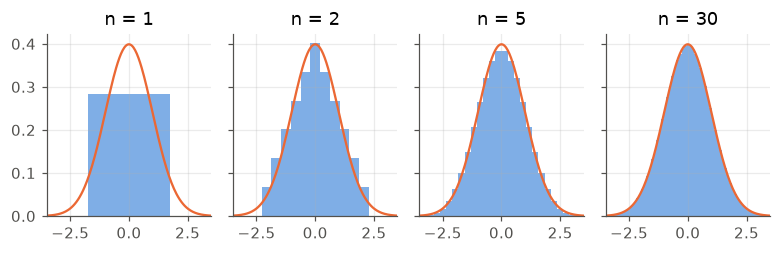

In [3]:
# Figure: standardised dice means at n = 1, 2, 5, 30 against the standard normal density
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.4), sharey=True)
for ax, n_ in zip(axes, (1, 2, 5, 30)):
    pm_ = dice_sum_pmf(n_); sup_ = np.arange(n_, 6*n_+1); sd_ = sqrt(n_*35/12); z_ = (sup_ - 3.5*n_)/sd_
    ax.bar(z_, pm_*sd_, width=1/sd_, color=C1, alpha=0.6)
    g = np.linspace(-3.5, 3.5, 200); ax.plot(g, np.exp(-g**2/2)/sqrt(2*pi), color=C2, lw=1.5); ax.set_title(f"n = {n_}"); ax.set_xlim(-3.5, 3.5)
plt.show()

### B2 — The characteristic function does the proof's work

$\varphi_{S_n}(t) = \varphi(t/\sigma\sqrt n)^n$ for a centred die, at $n = 30$: the real part is $e^{-t^2/2}$ to three decimals and the
imaginary part is zero by symmetry. No sampling — this is the CLT's proof evaluated numerically, and the reason the
W38 Fourier package and this one are the same subject.

In [4]:
sec(
    "B2",
    "The CLT is a Fourier theorem: |characteristic function|^n of a centred die vs exp(-t^2/2) after standardising, n = 30",
)
t = np.array([0.5, 1.0, 2.0])
n = 30
sd1 = sqrt(35 / 12)
faces = np.arange(1, 7) - 3.5
for tt in t:
    cf = np.mean(np.exp(1j * tt / (sd1 * sqrt(n)) * faces)) ** n
    print(
        f"t = {tt}: cf of standardised sum = {cf.real:+.4f}{cf.imag:+.4f}i ;  exp(-t^2/2) = {exp(-tt**2/2):.4f}"
    )


=== B2 The CLT is a Fourier theorem: |characteristic function|^n of a centred die vs exp(-t^2/2) after standardising, n = 30 ===
t = 0.5: cf of standardised sum = +0.8824+0.0000i ;  exp(-t^2/2) = 0.8825
t = 1.0: cf of standardised sum = +0.6055+0.0000i ;  exp(-t^2/2) = 0.6065
t = 2.0: cf of standardised sum = +0.1315+0.0000i ;  exp(-t^2/2) = 0.1353


### B3 — Berry–Esseen, measured against its bound

$\sup_x|F_n - \Phi|$ computed from the exact binomial (checked on both sides of every atom, since the sup sits at a
jump) against $0.4748\,\rho/(\sigma^3\sqrt n)$. The bound holds everywhere and is loose; the thing to read is the last
column: at $p = 0.01$, $n = 300$ is **three expected events**, the measured distance is $0.147$ — twice a fair coin's at $n = 30$ —
and $n = 3000$ is needed to get it down to $0.048$. The CLT clock runs on $np$, not on $n$ — which is why a rare-failure rate
needs so many samples.

In [5]:
sec(
    "B3",
    "Berry–Esseen for Bernoulli(p) sums: measured sup|F_n - Phi| (exact binomial) vs the bound 0.4748 rho/(sigma^3 sqrt n)",
)
from math import lgamma


def binom_pmf(n, p):
    k = np.arange(n + 1)
    lg = np.array([lgamma(n + 1) - lgamma(i + 1) - lgamma(n - i + 1) for i in k])
    return np.exp(lg + k * np.log(p) + (n - k) * np.log1p(-p))


def binom_sup(n, p):
    """sup_x |F_n(x) - Phi(x)| for the standardised binomial, no continuity correction (the theorem's quantity):
    the sup is attained at a jump, so check the CDF just after (F(k)) and just before (F(k-1)) each atom."""
    k = np.arange(n + 1)
    cdf = np.cumsum(binom_pmf(n, p))
    mu, sd = n * p, sqrt(n * p * (1 - p))
    z = (k - mu) / sd
    after = np.max(np.abs(cdf - np.array([Phi(v) for v in z])))
    before = np.max(np.abs(np.concatenate([[0.0], cdf[:-1]]) - np.array([Phi(v) for v in z])))
    return max(after, before)


for p, n in ((0.5, 30), (0.1, 30), (0.1, 300), (0.01, 300), (0.01, 3000)):
    rho_s3 = ((1 - p) ** 2 + p**2) / sqrt(p * (1 - p))
    print(
        f"p = {p:<5} n = {n:>5}: measured = {binom_sup(n, p):.4f}   bound = {0.4748*rho_s3/sqrt(n):.4f}   (rho/sigma^3 = {rho_s3:.3f};  n p = {n*p:g} expected events)"
    )


=== B3 Berry–Esseen for Bernoulli(p) sums: measured sup|F_n - Phi| (exact binomial) vs the bound 0.4748 rho/(sigma^3 sqrt n) ===
p = 0.5   n =    30: measured = 0.0722   bound = 0.0867   (rho/sigma^3 = 1.000;  n p = 15 expected events)
p = 0.1   n =    30: measured = 0.1474   bound = 0.2369   (rho/sigma^3 = 2.733;  n p = 3 expected events)
p = 0.1   n =   300: measured = 0.0484   bound = 0.0749   (rho/sigma^3 = 2.733;  n p = 30 expected events)
p = 0.01  n =   300: measured = 0.1472   bound = 0.2701   (rho/sigma^3 = 9.851;  n p = 3 expected events)
p = 0.01  n =  3000: measured = 0.0484   bound = 0.0854   (rho/sigma^3 = 9.851;  n p = 30 expected events)


### B4 — Two laws that never become Gaussian

Block means of 1,000 Cauchy draws have the same interquartile range as one Cauchy draw: averaging did nothing.
Block means of 1,000 Pareto(1.5) draws have the right mean, a maximum of $50$ and an excess kurtosis above
$1000$: the limit is a stable law, not a Gaussian, and no $n$ fixes it.

In [6]:
sec(
    "B4",
    "Where the CLT fails: Cauchy (no mean) and Pareto alpha=1.5 (mean, no variance) — block means of 1,000 vs a Gaussian",
)
c = rng.standard_cauchy((2000, 1000)).mean(1)
print(
    f"Cauchy: 2,000 block means of 1,000 samples: median {np.median(c):+.3f}, IQR {np.subtract(*np.percentile(c, [75, 25])):.3f} (same as ONE Cauchy draw: 2.000), max |mean| {np.max(np.abs(c)):.0f}"
)
par = (rng.pareto(1.5, (2000, 1000)) + 1).mean(1)
z = (par - par.mean()) / par.std()
print(
    f"Pareto(1.5): block means: mean {par.mean():.3f} (theory 3.000), sd {par.std():.3f}, max {par.max():.1f}, excess kurtosis {np.mean(z**4)-3:.1f} (Gaussian: 0) — the limit is a 1.5-stable law, not Gaussian"
)


=== B4 Where the CLT fails: Cauchy (no mean) and Pareto alpha=1.5 (mean, no variance) — block means of 1,000 vs a Gaussian ===
Cauchy: 2,000 block means of 1,000 samples: median +0.042, IQR 2.061 (same as ONE Cauchy draw: 2.000), max |mean| 1370


Pareto(1.5): block means: mean 3.007 (theory 3.000), sd 1.236, max 50.2, excess kurtosis 1064.7 (Gaussian: 0) — the limit is a 1.5-stable law, not Gaussian


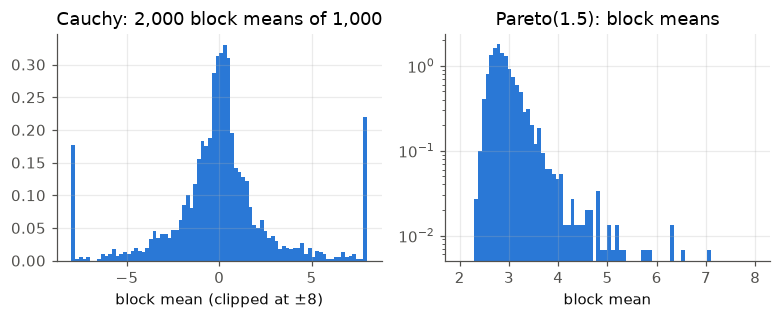

In [7]:
# Figure: block means of 1,000 draws — Cauchy keeps the spread of one draw; Pareto(1.5) keeps a heavy right tail
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
a1.hist(np.clip(c, -8, 8), bins=80, color=C1, density=True); a1.set_title("Cauchy: 2,000 block means of 1,000"); a1.set_xlabel("block mean (clipped at ±8)")
a2.hist(par, bins=80, range=(2, 8), color=C1, density=True); a2.set_yscale("log"); a2.set_title("Pareto(1.5): block means"); a2.set_xlabel("block mean")
plt.show()

## 3. The inequalities, and what each one knows

### B5 — Chebyshev, Hoeffding and the exact binomial tail

For 1,000 fair coins and $\varepsilon = 0.02, 0.03, 0.05$: the exact two-sided tail $P(|k - n/2| \ge n\varepsilon)$ — compared on
integer counts, because a floating-point test on $|k/n - p|$ counts the two boundary atoms inconsistently from one $\varepsilon$ to
the next — Chebyshev's bound (knows the variance), Hoeffding's (knows the range) and the normal approximation, uncorrected and
with the half-step continuity correction. Chebyshev is useless beyond one standard
error; Hoeffding is within a small factor of the truth here *because* a fair coin has the largest variance a
$[0,1]$ variable can have — the next sections show it fail when the variance is small.

In [8]:
sec(
    "B5", "Chebyshev vs Hoeffding vs exact binomial: P(|mean - p| >= eps) for n = 1000 coin flips with p = 0.5 — the tail event compared on integer counts, |k - n/2| >= n eps, the event the inequalities bound"
)
n, p = 1000, 0.5
k = np.arange(n + 1)
pmf = binom_pmf(n, 0.5)
for eps_ in (0.02, 0.03, 0.05):
    thr = int(round(n * eps_))  # 20, 30, 50 counts: an integer comparison; |k/n - p| > eps in floating point counted the boundary atoms inconsistently
    exact = pmf[np.abs(k - n // 2) >= thr].sum()
    sd_ = sqrt(p * (1 - p) / n)
    print(
        f"eps = {eps_}: exact = {exact:.4f}   Chebyshev p(1-p)/(n eps^2) = {min(1, p*(1-p)/(n*eps_**2)):.4f}   Hoeffding 2 exp(-2 n eps^2) = {2*exp(-2*n*eps_**2):.4f}   normal approx = {2*(1-Phi(eps_/sd_)):.4f}   (continuity-corrected, at (thr - 1/2)/n: {2*(1-Phi((thr - 0.5)/n/sd_)):.4f})"
    )


=== B5 Chebyshev vs Hoeffding vs exact binomial: P(|mean - p| >= eps) for n = 1000 coin flips with p = 0.5 — the tail event compared on integer counts, |k - n/2| >= n eps, the event the inequalities bound ===
eps = 0.02: exact = 0.2174   Chebyshev p(1-p)/(n eps^2) = 0.6250   Hoeffding 2 exp(-2 n eps^2) = 0.8987   normal approx = 0.2059   (continuity-corrected, at (thr - 1/2)/n: 0.2175)
eps = 0.03: exact = 0.0620   Chebyshev p(1-p)/(n eps^2) = 0.2778   Hoeffding 2 exp(-2 n eps^2) = 0.3306   normal approx = 0.0578   (continuity-corrected, at (thr - 1/2)/n: 0.0621)
eps = 0.05: exact = 0.0017   Chebyshev p(1-p)/(n eps^2) = 0.1000   Hoeffding 2 exp(-2 n eps^2) = 0.0135   normal approx = 0.0016   (continuity-corrected, at (thr - 1/2)/n: 0.0017)


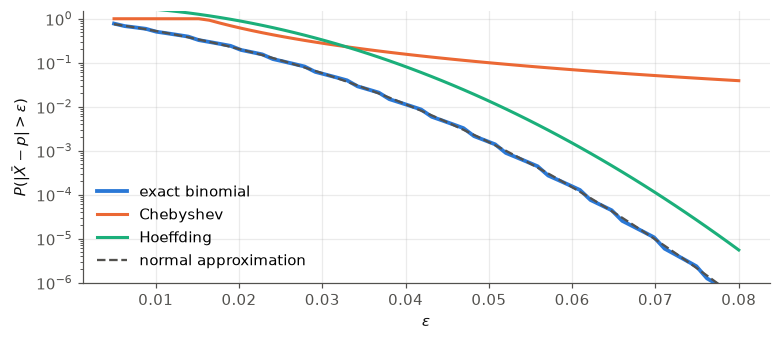

In [9]:
# Figure: the exact tail and the three bounds across eps
eg = np.linspace(0.005, 0.08, 60)
exact_ = [pmf[np.abs(k - n//2) >= int(np.ceil(n*e - 1e-9))].sum() for e in eg]   # integer counts, the >= event the bounds use
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(eg, exact_, color=C1, lw=2.5, label="exact binomial")
ax.plot(eg, np.minimum(1, p*(1-p)/(n*eg**2)), color=C2, lw=2, label="Chebyshev")
ax.plot(eg, 2*np.exp(-2*n*eg**2), color=C3, lw=2, label="Hoeffding")
ax.plot(eg, [2*(1-Phi(e/sqrt(p*(1-p)/n))) for e in eg], color="#52514e", lw=1.5, ls="--", label="normal approximation")
ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5); ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel(r"$P(|\bar X - p| > \varepsilon)$"); ax.legend(); plt.show()

### B6 — Coverage is a frequency

A "95% interval" is a procedure, and its coverage is how often, over replications, it contains the truth. Ten
thousand replicated intervals for $p = 0.1$: at $n = 100$ (ten expected events) both the textbook normal interval and
Wilson's cover about 94%, not 95%; at $n = 1000$ both reach 95%. The two differ where the count of events is small —
the normal interval collapses to zero width at $\hat p = 0$, Wilson's does not. If an eval reports one interval, the only
thing that makes it a 95% interval is this experiment having been done for its method and its $n$.

In [10]:
sec(
    "B6",
    "Coverage is a frequency: 10,000 replicated 95% intervals for p from n = 100 and n = 1000 Bernoulli(0.1) trials",
)
for n in (100, 1000):
    for method in ("normal", "wilson"):
        hits = 0
        reps = 10000
        x = rng.binomial(n, 0.1, reps)
        ph = x / n
        if method == "normal":
            lo, hi = ph - 1.96 * np.sqrt(ph * (1 - ph) / n), ph + 1.96 * np.sqrt(ph * (1 - ph) / n)
        else:
            zq = 1.96
            cen = (ph + zq**2 / (2 * n)) / (1 + zq**2 / n)
            half = zq * np.sqrt(ph * (1 - ph) / n + zq**2 / (4 * n**2)) / (1 + zq**2 / n)
            lo, hi = cen - half, cen + half
        print(
            f"n = {n:>4} {method:6}: coverage of p = 0.1 = {np.mean((lo <= 0.1) & (0.1 <= hi)):.4f}   mean half-width = {np.mean(hi-lo)/2:.4f}"
        )
# small expected-count rows (np = 3): the regime where the two intervals part company. Own generator, so the stream above is unchanged.
rng_b6 = np.random.default_rng(20261029 + 6)
for n, p in ((30, 0.1), (300, 0.01)):
    x = rng_b6.binomial(n, p, 10000)
    ph = x / n
    lo_w, hi_w = ph - 1.96 * np.sqrt(ph * (1 - ph) / n), ph + 1.96 * np.sqrt(ph * (1 - ph) / n)
    zq = 1.96
    cen = (ph + zq**2 / (2 * n)) / (1 + zq**2 / n)
    half = zq * np.sqrt(ph * (1 - ph) / n + zq**2 / (4 * n**2)) / (1 + zq**2 / n)
    lo_s, hi_s = cen - half, cen + half
    print(
        f"n = {n:>4} p = {p:<5} (np = {n*p:g}): normal coverage {np.mean((lo_w <= p) & (p <= hi_w)):.4f} (zero-width interval when x = 0: {np.mean(x == 0):.3f} of the time)   wilson coverage {np.mean((lo_s <= p) & (p <= hi_s)):.4f}"
    )


=== B6 Coverage is a frequency: 10,000 replicated 95% intervals for p from n = 100 and n = 1000 Bernoulli(0.1) trials ===
n =  100 normal: coverage of p = 0.1 = 0.9378   mean half-width = 0.0581
n =  100 wilson: coverage of p = 0.1 = 0.9387   mean half-width = 0.0589
n = 1000 normal: coverage of p = 0.1 = 0.9503   mean half-width = 0.0186
n = 1000 wilson: coverage of p = 0.1 = 0.9508   mean half-width = 0.0186
n =   30 p = 0.1   (np = 3): normal coverage 0.8076 (zero-width interval when x = 0: 0.044 of the time)   wilson coverage 0.9743
n =  300 p = 0.01  (np = 3): normal coverage 0.8009 (zero-width interval when x = 0: 0.052 of the time)   wilson coverage 0.9676


## 4. The eval-set error bar

### B7 — The table

Hoeffding's $n$ for a half-width $\varepsilon$ at 95%, beside the binomial $n$ at 80% accuracy: Hoeffding asks for about 3× the
sample size (1.7× the half-width) because it does not know the variance. At $n = 1000$ and 80% accuracy the standard deviation is $1.26$
points, the 95% half-width $2.5$ points, and a one-point gap between two *unpaired* models is $0.56$ standard
deviations — noise. The last line is the $n$ at which that gap becomes $1.96$ sd: about **12,300** examples.

In [11]:
sec(
    "B7",
    "Eval-set error bars: Hoeffding n for half-width eps at 95%; binomial sd and interval at acc = 0.80, n = 1000; the 1-point gap",
)
for e in (0.05, 0.02, 0.01, 0.005):
    print(
        f"Hoeffding n for eps = {e}: {math.ceil(log(2/0.05)/(2*e**2)):>7,}    binomial n at acc 0.80: {math.ceil(1.96**2*0.8*0.2/e**2):>7,}"
    )
n = 1000
se = sqrt(0.8 * 0.2 / n)
print(
    f"acc = 0.80, n = 1000: sd = {se:.4f}; 95% half-width = {1.96*se:.4f};  two models unpaired, difference sd = {sqrt(2)*se:.4f}  -> a 1-point gap is {0.01/(sqrt(2)*se):.2f} sd"
)
print(f"n for a 1-point gap to be 1.96 sd unpaired at acc 0.80: {math.ceil(2*0.8*0.2*1.96**2/0.01**2):,}")


=== B7 Eval-set error bars: Hoeffding n for half-width eps at 95%; binomial sd and interval at acc = 0.80, n = 1000; the 1-point gap ===
Hoeffding n for eps = 0.05:     738    binomial n at acc 0.80:     246
Hoeffding n for eps = 0.02:   4,612    binomial n at acc 0.80:   1,537
Hoeffding n for eps = 0.01:  18,445    binomial n at acc 0.80:   6,147
Hoeffding n for eps = 0.005:  73,778    binomial n at acc 0.80:  24,587
acc = 0.80, n = 1000: sd = 0.0126; 95% half-width = 0.0248;  two models unpaired, difference sd = 0.0179  -> a 1-point gap is 0.56 sd
n for a 1-point gap to be 1.96 sd unpaired at acc 0.80: 12,294


### B8 — Pairing: the disagreements are the sample

Two models scored on the same 1,000 examples disagree on 100 of them. Under "no difference" the wins are
$\mathrm{Bin}(100, 1/2)$, so $55$ wins is $z = 1$, $60$ wins is $z = 2$ (McNemar). The simulation shows why pairing is
worth so much: for two models that disagree on 8% of examples, the standard deviation of their accuracy difference
is about a third of the value computed as if they were independent.

In [12]:
sec(
    "B8",
    "Pairing: same n = 1000 test set, disagreement rate 10%, model B wins 55% / 60% / 65% of disagreements (McNemar)",
)
n = 1000
for win in (0.55, 0.60, 0.65):
    dis = 100
    W = win * dis
    gap = (2 * W - dis) / n
    z = (W - dis / 2) / sqrt(dis / 4)  # McNemar: under 'no difference' W ~ Bin(dis, 1/2)
    print(
        f"B wins {W:.0f} of {dis} disagreements: accuracy gap = {gap:+.3f};  expected wins under no difference = {dis/2:.0f} ± {sqrt(dis/4):.1f};  z = {z:.2f}"
    )
# simulate: two models with per-example correctness correlated
reps = 20000
n = 2000
sd_unpaired, sd_paired = [], []
for _ in range(200):
    base = rng.uniform(0, 1, n) < 0.715
    flip = rng.uniform(0, 1, n) < 0.08
    a = base
    b = np.where(flip, ~base, base)
    sd_unpaired.append(a.mean() - b.mean())
print(
    f"simulated n = 2000, two models that disagree on ~8%: sd of the accuracy difference = {np.std(sd_unpaired):.4f} (paired reality) vs {sqrt(2*0.715*0.285/2000):.4f} assumed independent"
)


=== B8 Pairing: same n = 1000 test set, disagreement rate 10%, model B wins 55% / 60% / 65% of disagreements (McNemar) ===
B wins 55 of 100 disagreements: accuracy gap = +0.010;  expected wins under no difference = 50 ± 5.0;  z = 1.00
B wins 60 of 100 disagreements: accuracy gap = +0.020;  expected wins under no difference = 50 ± 5.0;  z = 2.00
B wins 65 of 100 disagreements: accuracy gap = +0.030;  expected wins under no difference = 50 ± 5.0;  z = 3.00
simulated n = 2000, two models that disagree on ~8%: sd of the accuracy difference = 0.0062 (paired reality) vs 0.0143 assumed independent


### B9 — Selection bias: the best of $m$ equally good models

When $m$ models are all exactly 80% accurate, the best score on a 1,000-example test set averages
$0.819$ at $m = 10$, $0.831$ at $m = 100$, $0.840$ at $m = 1000$ — two to four points above the truth. The Gaussian-maximum
approximation $0.8 + 0.0126\sqrt{2\ln m}$ gives the shape and overstates the level by about half a point (it is an asymptotic
upper envelope; the figure shows the gap). A leaderboard's top entry has been selected on the same set it is evaluated on;
its reported number is the maximum of $m$ noisy draws, not an estimate of its accuracy. The scores here are drawn
*independently* for the $m$ models — an independent-score idealisation. Real models scored on one test set err on overlapping
examples, and that correlation moves the bias in either direction: for two scores $\mathbb E\max(Z_1, Z_2) = \sigma\sqrt{(1-\rho)/\pi}$
(`§52`), smaller under positive correlation, larger under negative; the flagship's §7.6 has the general statement.

In [13]:
sec(
    "B9",
    "Selection bias: best of m models on the same n = 1000 test set when all m are equally good (acc 0.80)",
)
for m in (1, 10, 100, 1000):
    scores = rng.binomial(1000, 0.8, (5000, m)) / 1000
    print(
        f"m = {m:>4}: mean of the best score = {scores.max(1).mean():.4f}  (true 0.8000; theory ≈ 0.8 + 0.0126*sqrt(2 ln m) = {0.8 + 0.0126*sqrt(2*log(m)) if m > 1 else 0.8:.4f})"
    )


=== B9 Selection bias: best of m models on the same n = 1000 test set when all m are equally good (acc 0.80) ===
m =    1: mean of the best score = 0.8000  (true 0.8000; theory ≈ 0.8 + 0.0126*sqrt(2 ln m) = 0.8000)
m =   10: mean of the best score = 0.8193  (true 0.8000; theory ≈ 0.8 + 0.0126*sqrt(2 ln m) = 0.8270)
m =  100: mean of the best score = 0.8312  (true 0.8000; theory ≈ 0.8 + 0.0126*sqrt(2 ln m) = 0.8382)


m = 1000: mean of the best score = 0.8400  (true 0.8000; theory ≈ 0.8 + 0.0126*sqrt(2 ln m) = 0.8468)


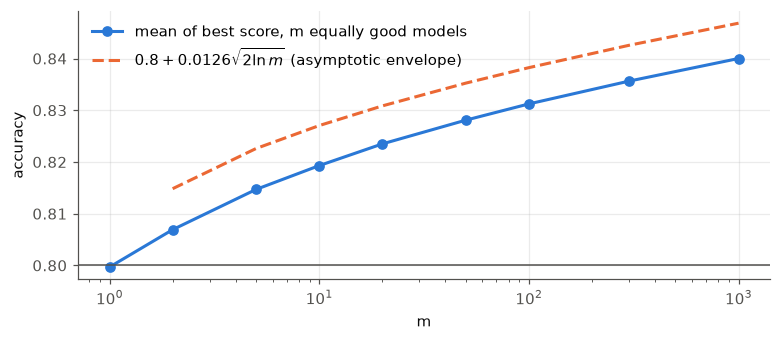

In [14]:
# Figure: the expected best-of-m score against the Gaussian-maximum approximation
ms = np.array([1, 2, 5, 10, 20, 50, 100, 300, 1000]); best = []
for m_ in ms:
    best.append((rng.binomial(1000, 0.8, (3000, m_))/1000).max(1).mean())
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(ms, best, "o-", color=C1, lw=2, ms=6, label="mean of best score, m equally good models")
ax.plot(ms[1:], 0.8 + 0.0126*np.sqrt(2*np.log(ms[1:])), color=C2, lw=2, ls="--", label=r"$0.8 + 0.0126\sqrt{2\ln m}$ (asymptotic envelope)")
ax.axhline(0.8, color="#52514e", lw=1); ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel("accuracy"); ax.legend(); plt.show()

## 5. High dimensions

### B10 — The shell, the cosines, and attention's $1/\sqrt d$

Norms concentrate at $\sqrt d$ with spread $1/\sqrt 2$ at every $d$; cosines have spread $1/\sqrt d$; dot products have spread
$\sqrt d$. The last line is the attention experiment: the softmax over 8 random keys with raw logits at $d = 4096$ puts
a mean of $0.98$ of its mass on one key (logit spread 64); with logits divided by $\sqrt d$ the top key gets $0.36$, against
$0.125$ for uniform. The division is
not a convention; it is the only scaling at which the initial attention pattern is neither saturated nor flat.

In [15]:
sec(
    "B10",
    "High dimensions: ||g|| for g ~ N(0, I_d), cosine between two independent g's, and the attention logit q.k",
)
for d in (2, 16, 256, 4096):
    g = rng.standard_normal((20000, d))
    h = rng.standard_normal((20000, d))
    nrm = np.linalg.norm(g, axis=1)
    cosv = np.sum(g * h, 1) / (nrm * np.linalg.norm(h, axis=1))
    print(
        f"d = {d:>5}: ||g|| mean {nrm.mean():8.3f} sd {nrm.std():.3f} (sqrt d = {sqrt(d):8.3f}, sd -> 1/sqrt 2 = 0.707);  cosine sd {cosv.std():.4f} (1/sqrt d = {1/sqrt(d):.4f});  q.k sd {np.sum(g*h,1).std():8.3f} (sqrt d);  q.k/sqrt d sd {np.sum(g*h,1).std()/sqrt(d):.3f}"
    )
print(
    f"softmax over 8 random keys at d = 4096, logits q.k: max prob mean = {np.mean([np.max(np.exp(l)/np.exp(l).sum()) for l in rng.standard_normal((2000, 8))*64]):.3f};  logits q.k/sqrt d: max prob mean = {np.mean([np.max(np.exp(l)/np.exp(l).sum()) for l in rng.standard_normal((2000, 8))]):.3f}  (uniform would be 0.125)"
)


=== B10 High dimensions: ||g|| for g ~ N(0, I_d), cosine between two independent g's, and the attention logit q.k ===
d =     2: ||g|| mean    1.256 sd 0.660 (sqrt d =    1.414, sd -> 1/sqrt 2 = 0.707);  cosine sd 0.7067 (1/sqrt d = 0.7071);  q.k sd    1.437 (sqrt d);  q.k/sqrt d sd 1.016
d =    16: ||g|| mean    3.929 sd 0.701 (sqrt d =    4.000, sd -> 1/sqrt 2 = 0.707);  cosine sd 0.2471 (1/sqrt d = 0.2500);  q.k sd    3.942 (sqrt d);  q.k/sqrt d sd 0.985


d =   256: ||g|| mean   15.988 sd 0.705 (sqrt d =   16.000, sd -> 1/sqrt 2 = 0.707);  cosine sd 0.0623 (1/sqrt d = 0.0625);  q.k sd   15.952 (sqrt d);  q.k/sqrt d sd 0.997


d =  4096: ||g|| mean   63.994 sd 0.710 (sqrt d =   64.000, sd -> 1/sqrt 2 = 0.707);  cosine sd 0.0156 (1/sqrt d = 0.0156);  q.k sd   63.956 (sqrt d);  q.k/sqrt d sd 0.999
softmax over 8 random keys at d = 4096, logits q.k: max prob mean = 0.984;  logits q.k/sqrt d: max prob mean = 0.361  (uniform would be 0.125)


### B11 — How many near-orthogonal directions fit

The worst $|\cos|$ between a query and $m$ random unit keys in $d = 4096$ tracks $\sqrt{2\ln m/d}$: between $0.05$ and $0.07$ for
$m = 100$ to $10{,}000$, against $0.047$ to $0.067$ from the formula. A query in a few thousand dimensions is nearly orthogonal to every one of a million random keys (worst $|\cos| \approx 0.08$ for one query against a million; the worst *pair* among the million is about $\sqrt{2\ln(m^2/2)/d} \approx 0.11$) — this is the room that makes a dot-product lookup over a vocabulary, or a key–value store,
work at all.

In [16]:
sec(
    "B11",
    "How many near-orthogonal directions fit: worst |cosine| among m random keys in d = 4096, vs sqrt(2 ln m / d)",
)
d = 4096
for m in (100, 1000, 10000):
    K = rng.standard_normal((m, d))
    K /= np.linalg.norm(K, axis=1, keepdims=True)
    q = rng.standard_normal(d)
    q /= np.linalg.norm(q)
    print(
        f"m = {m:>6}: worst |cos(q, key)| = {np.max(np.abs(K @ q)):.4f}   sqrt(2 ln m / d) = {sqrt(2*log(m)/d):.4f}"
    )
print(
    f"one fixed query in d = 4096 is within about sqrt(2 ln m / d) = {sqrt(2*log(1e6)/d):.3f} of orthogonal to every one of a million random keys (one-against-all, what a lookup needs);  the worst of ALL m^2/2 pairs among them is larger, about sqrt(4 ln m / d) = {sqrt(4*log(1e6)/d):.3f}"
)


=== B11 How many near-orthogonal directions fit: worst |cosine| among m random keys in d = 4096, vs sqrt(2 ln m / d) ===
m =    100: worst |cos(q, key)| = 0.0607   sqrt(2 ln m / d) = 0.0474
m =   1000: worst |cos(q, key)| = 0.0545   sqrt(2 ln m / d) = 0.0581


m =  10000: worst |cos(q, key)| = 0.0697   sqrt(2 ln m / d) = 0.0671
one fixed query in d = 4096 is within about sqrt(2 ln m / d) = 0.082 of orthogonal to every one of a million random keys (one-against-all, what a lookup needs);  the worst of ALL m^2/2 pairs among them is larger, about sqrt(4 ln m / d) = 0.116


### B12 — Nearest loses meaning for random points

The ratio of the nearest to the farthest distance from a query to 1,000 random points goes from $0.02$ in $d = 2$ to
$0.94$ in $d = 4096$: all distances cluster near $\sqrt{2d}$. For *random* points the nearest neighbour is almost as far
as the farthest. Real embeddings sit on a low-dimensional structure and escape this — which is the whole reason
retrieval works, and the reason it stops working when embeddings are nearly random.

In [17]:
sec(
    "B12",
    "Nearest loses meaning for random points: ratio of nearest to farthest distance among 1,000 random points in d dims",
)
for d in (2, 16, 256, 4096):
    P = rng.standard_normal((1000, d))
    q = rng.standard_normal(d)
    dist = np.linalg.norm(P - q, axis=1)
    print(
        f"d = {d:>5}: nearest/farthest = {dist.min()/dist.max():.4f};  all distances in [{dist.min():.2f}, {dist.max():.2f}], sqrt(2d) = {sqrt(2*d):.2f}"
    )


=== B12 Nearest loses meaning for random points: ratio of nearest to farthest distance among 1,000 random points in d dims ===
d =     2: nearest/farthest = 0.0168;  all distances in [0.08, 4.68], sqrt(2d) = 2.00
d =    16: nearest/farthest = 0.3367;  all distances in [2.65, 7.88], sqrt(2d) = 5.66
d =   256: nearest/farthest = 0.7821;  all distances in [19.66, 25.13], sqrt(2d) = 22.63
d =  4096: nearest/farthest = 0.9419;  all distances in [86.95, 92.30], sqrt(2d) = 90.51


### B13 — Johnson–Lindenstrauss on sampled pairs

The same projection as the flagship's `§13`, measured on $\sim20{,}000$ random pairs rather than all of them: distance
ratios with standard deviation $\approx 1/\sqrt{2k}$. The guarantee depends on the number of points, never on $d$.

In [18]:
sec(
    "B13", "Johnson–Lindenstrauss: 1,000 points in d = 4096 projected to k dims by a Gaussian matrix / sqrt k"
)
P = rng.standard_normal((1000, 4096))
idx = rng.integers(0, 1000, (20000, 2))
idx = idx[idx[:, 0] != idx[:, 1]]
D0 = np.linalg.norm(P[idx[:, 0]] - P[idx[:, 1]], axis=1)
for k in (64, 256, 1024):
    R = rng.standard_normal((4096, k)) / sqrt(k)
    Q = P @ R
    D1 = np.linalg.norm(Q[idx[:, 0]] - Q[idx[:, 1]], axis=1)
    ratio = D1 / D0
    print(
        f"k = {k:>5}: distance ratio mean {ratio.mean():.4f}, sd {ratio.std():.4f}, max distortion {np.max(np.abs(ratio-1)):.4f}   (theory sd ~ 1/sqrt(2k) = {1/sqrt(2*k):.4f})"
    )


=== B13 Johnson–Lindenstrauss: 1,000 points in d = 4096 projected to k dims by a Gaussian matrix / sqrt k ===


k =    64: distance ratio mean 0.9964, sd 0.0869, max distortion 0.3658   (theory sd ~ 1/sqrt(2k) = 0.0884)
k =   256: distance ratio mean 0.9994, sd 0.0442, max distortion 0.2064   (theory sd ~ 1/sqrt(2k) = 0.0442)


k =  1024: distance ratio mean 1.0001, sd 0.0221, max distortion 0.0895   (theory sd ~ 1/sqrt(2k) = 0.0221)


### B14 — Random Fourier features are Hoeffding on Bochner's theorem

$k(x, y) = \mathbb E_\omega[\cos(\omega^\top x + b)\cos(\omega^\top y + b)]\cdot 2$ for the RBF kernel; $D$ random features are $D$ samples of a
bounded variable and the error falls as $1/\sqrt D$ — the printed rms tracks it. The W38 package's kernel ↔ Fourier
duality, made into a Monte Carlo estimator with an error bar.

In [19]:
sec(
    "B14",
    "Random Fourier features = Hoeffding on Bochner: RBF kernel approximation error vs D, d = 8, 500 point pairs",
)
d = 8
X1 = rng.standard_normal((500, d))
X2 = rng.standard_normal((500, d))
true = np.exp(-np.sum((X1 - X2) ** 2, 1) / 2)
for D in (64, 256, 1024, 4096):
    W = rng.standard_normal((d, D))
    b = rng.uniform(0, 2 * pi, D)
    z1 = sqrt(2 / D) * np.cos(X1 @ W + b)
    z2 = sqrt(2 / D) * np.cos(X2 @ W + b)
    approx = np.sum(z1 * z2, 1)
    print(
        f"D = {D:>5}: max |k_hat - k| = {np.max(np.abs(approx-true)):.4f}   rms = {sqrt(np.mean((approx-true)**2)):.4f}   (1/sqrt D = {1/sqrt(D):.4f})"
    )


=== B14 Random Fourier features = Hoeffding on Bochner: RBF kernel approximation error vs D, d = 8, 500 point pairs ===
D =    64: max |k_hat - k| = 0.4273   rms = 0.1268   (1/sqrt D = 0.1250)
D =   256: max |k_hat - k| = 0.1935   rms = 0.0642   (1/sqrt D = 0.0625)
D =  1024: max |k_hat - k| = 0.1008   rms = 0.0319   (1/sqrt D = 0.0312)


D =  4096: max |k_hat - k| = 0.0464   rms = 0.0152   (1/sqrt D = 0.0156)


## 6. Correlated samples are worth fewer than they look

### B15 — The effective sample size of an AR(1) chain

For a stationary AR(1) with coefficient $\phi$, the variance of the time average over $n$ steps is $(1+\phi)/(1-\phi)$
times the i.i.d. value, measured over 2,000 chains. At $\phi = 0.9$ a chain of $10{,}000$ is worth $526$ independent
samples; at $\phi = 0.99$, $50$. A naive standard error is too small by $\sqrt{(1+\phi)/(1-\phi)}$ — 4.4× at $\phi = 0.9$.

In [20]:
sec(
    "B15",
    "Dependent samples: AR(1) with unit stationary variance, ESS = n (1-phi)/(1+phi); naive standard error is off by sqrt((1+phi)/(1-phi))",
)
n = 10000
for phi in (0.0, 0.5, 0.9, 0.99):
    runs = np.zeros(2000)
    x = rng.standard_normal(2000)
    acc = np.zeros(2000)
    for t_ in range(n):
        x = phi * x + sqrt(1 - phi**2) * rng.standard_normal(2000)
        acc += x
    runs = acc / n
    print(
        f"phi = {phi:<4}: var(time average)*n = {np.var(runs)*n:8.3f}   theory (1+phi)/(1-phi) = {(1+phi)/(1-phi):8.3f}   ESS of 10,000 = {int(n*(1-phi)/(1+phi)):>6}   naive SE too small by x{sqrt((1+phi)/(1-phi)):.1f}"
    )


=== B15 Dependent samples: AR(1) with unit stationary variance, ESS = n (1-phi)/(1+phi); naive standard error is off by sqrt((1+phi)/(1-phi)) ===


phi = 0.0 : var(time average)*n =    0.950   theory (1+phi)/(1-phi) =    1.000   ESS of 10,000 =  10000   naive SE too small by x1.0


phi = 0.5 : var(time average)*n =    3.191   theory (1+phi)/(1-phi) =    3.000   ESS of 10,000 =   3333   naive SE too small by x1.7


phi = 0.9 : var(time average)*n =   19.110   theory (1+phi)/(1-phi) =   19.000   ESS of 10,000 =    526   naive SE too small by x4.4


phi = 0.99: var(time average)*n =  200.728   theory (1+phi)/(1-phi) =  199.000   ESS of 10,000 =     50   naive SE too small by x14.1


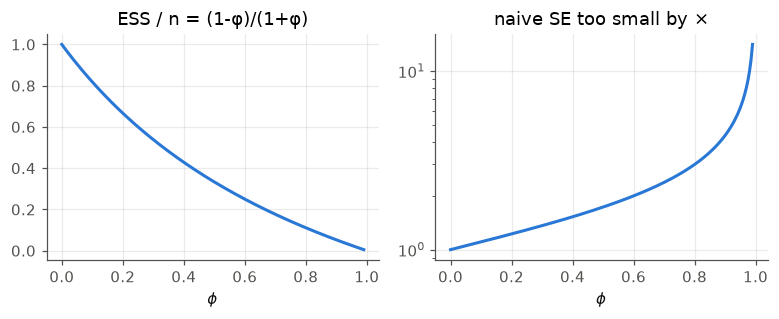

In [21]:
# Figure: the ESS fraction and the naive-SE error factor across phi (closed forms)
ph = np.linspace(0, 0.99, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
a1.plot(ph, (1-ph)/(1+ph), color=C1, lw=2); a1.set_xlabel(r"$\phi$"); a1.set_title("ESS / n = (1-φ)/(1+φ)")
a2.plot(ph, np.sqrt((1+ph)/(1-ph)), color=C1, lw=2); a2.set_yscale("log"); a2.set_xlabel(r"$\phi$"); a2.set_title("naive SE too small by ×")
plt.show()

### B16 — Batch means: the right error bar from one chain

One AR(1) chain of $100{,}000$ at $\phi = 0.9$, cut into 100 batches of 1,000: the standard error of the batch means is
$\sqrt{19} \approx 4.4$ times the naive one, and the batch means are nearly uncorrelated (lag-1 autocorrelation near
0). This is the estimator to use for any Monte Carlo average over a chain — MCMC, a replay buffer, a long
rollout — when only one chain exists.

In [22]:
sec(
    "B16",
    "Batch means recovers the right error bar from ONE chain: AR(1) phi = 0.9, n = 100,000, batches of 1,000",
)
n, phi = 100_000, 0.9
x = 0.0
path = np.empty(n)
for t_ in range(n):
    x = phi * x + sqrt(1 - phi**2) * rng.standard_normal()
    path[t_] = x
naive = path.std() / sqrt(n)
bm = path.reshape(100, 1000).mean(1)
batch_se = bm.std(ddof=1) / sqrt(100)
print(
    f"naive SE = {naive:.5f};  batch-means SE = {batch_se:.5f};  ratio = {batch_se/naive:.2f}  (theory sqrt(19) = {sqrt(19):.2f});  lag-1 autocorr of batch means = {np.corrcoef(bm[:-1], bm[1:])[0,1]:+.3f}"
)


=== B16 Batch means recovers the right error bar from ONE chain: AR(1) phi = 0.9, n = 100,000, batches of 1,000 ===
naive SE = 0.00317;  batch-means SE = 0.01415;  ratio = 4.47  (theory sqrt(19) = 4.36);  lag-1 autocorr of batch means = +0.030


### B17 — Metropolis–Hastings: acceptance is not the goal

A random-walk Metropolis sampler for $\mathcal N(0,1)$ at four step sizes. Step $0.1$ accepts 97% of proposals and
has an autocorrelation time of about $350$; step $10$ accepts 13% with an autocorrelation time of $11$; step $2.4$ (the
$2.38\sigma$ rule) accepts 44% and gives $4.2$ — about $47{,}000$ effective samples from $200{,}000$ draws, eighty times step $0.1$'s. The acceptance rate is a
symptom; the effective sample size is the quantity.

In [23]:
sec(
    "B17",
    "Metropolis–Hastings for N(0,1) with a Gaussian random-walk proposal: acceptance rate and ESS vs step size (n = 200,000)",
)


def mh(step, n=200_000):
    x = 0.0
    out = np.empty(n)
    acc = 0
    u = np.log(rng.uniform(0, 1, n))
    z = rng.standard_normal(n) * step
    for i in range(n):
        y = x + z[i]
        if u[i] < -0.5 * (y * y - x * x):
            x = y
            acc += 1
        out[i] = x
    return out, acc / n


for step in (0.1, 0.5, 2.4, 10.0):
    out, ar = mh(step)
    c = out - out.mean()
    ac = np.array([np.dot(c[:-k], c[k:]) / np.dot(c, c) for k in range(1, 400)])
    cut = np.argmax(ac < 0.05) if np.any(ac < 0.05) else 399
    tau = 1 + 2 * ac[:cut].sum()
    print(
        f"step = {step:>4}: acceptance = {ar:.3f};  integrated autocorrelation time = {tau:6.1f};  ESS of 200,000 ≈ {int(200_000/tau):>7}"
    )


=== B17 Metropolis–Hastings for N(0,1) with a Gaussian random-walk proposal: acceptance rate and ESS vs step size (n = 200,000) ===


step =  0.1: acceptance = 0.968;  integrated autocorrelation time =  347.3;  ESS of 200,000 ≈     575


step =  0.5: acceptance = 0.843;  integrated autocorrelation time =   21.8;  ESS of 200,000 ≈    9173


step =  2.4: acceptance = 0.442;  integrated autocorrelation time =    4.2;  ESS of 200,000 ≈   47398


step = 10.0: acceptance = 0.127;  integrated autocorrelation time =   10.8;  ESS of 200,000 ≈   18475


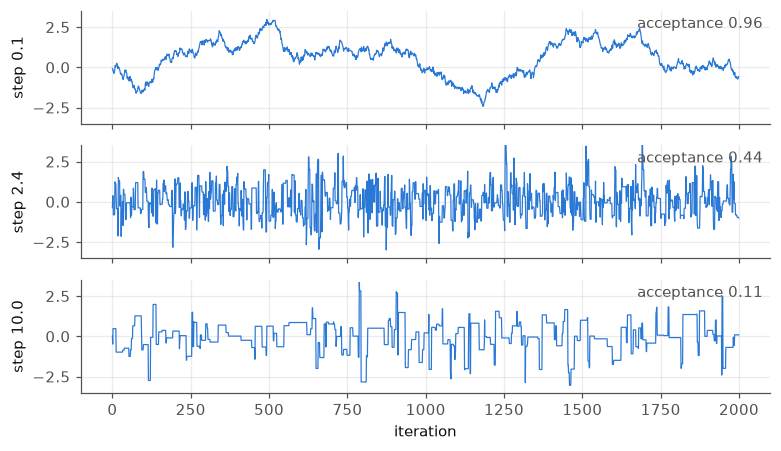

In [24]:
# Figure: the first 2,000 steps of the chain at three step sizes — sticky, mixing, stuck
fig, axes = plt.subplots(3, 1, figsize=(7.2, 4.2), sharex=True)
for ax, st in zip(axes, (0.1, 2.4, 10.0)):
    tr, ar_ = mh(st, n=2000); ax.plot(tr, color=C1, lw=0.8); ax.set_ylabel(f"step {st}"); ax.set_ylim(-3.5, 3.5)
    ax.text(0.99, 0.85, f"acceptance {ar_:.2f}", transform=ax.transAxes, ha="right", color="#52514e")
axes[-1].set_xlabel("iteration"); plt.show()

### B18 — Tokens are not independent samples

Per-token losses on 1,000 documents of 512 tokens with within-document AR(1) correlation $\phi = 0.95$. The naive
standard error treats $512{,}000$ tokens as i.i.d.; the document-level standard error is $6$× larger, and the
effective number of tokens per document is about $14$ of $512$ (the AR(1) formula says 13). A perplexity comparison that reports a token-level
error bar is reporting a number that is too small by this factor.

In [25]:
sec(
    "B18",
    "Tokens are not independent samples: per-token loss on an AR(1)-correlated stream, effective n per document",
)
# model: per-token loss = 2.0 + 0.5 * AR(1)(phi) noise, 1,000 documents of 512 tokens
docs, T, phi = 1000, 512, 0.95
x = rng.standard_normal(docs)
L = np.empty((docs, T))
for t_ in range(T):
    x = phi * x + sqrt(1 - phi**2) * rng.standard_normal(docs)
    L[:, t_] = 2.0 + 0.5 * x
naive_se = L.std() / sqrt(docs * T)
doc_se = L.mean(1).std(ddof=1) / sqrt(docs)
print(
    f"mean loss = {L.mean():.4f};  naive SE (tokens as i.i.d., n = {docs*T:,}) = {naive_se:.5f};  document-level SE (n = {docs}) = {doc_se:.5f};  ratio = {doc_se/naive_se:.1f}"
)
print(
    f"effective tokens per document ≈ {T/((doc_se/naive_se)**2):.0f} of {T}  (AR(1) theory (1-phi)/(1+phi) * T = {(1-phi)/(1+phi)*T:.0f} for a long document)"
)


=== B18 Tokens are not independent samples: per-token loss on an AR(1)-correlated stream, effective n per document ===
mean loss = 1.9968;  naive SE (tokens as i.i.d., n = 512,000) = 0.00069;  document-level SE (n = 1000) = 0.00424;  ratio = 6.1
effective tokens per document ≈ 14 of 512  (AR(1) theory (1-phi)/(1+phi) * T = 13 for a long document)


### B19 — Hoeffding versus Bernstein when the variance is small

On a 1% failure rate with $n = 10{,}000$: Hoeffding's half-width is $0.0136$ — wider than the rate itself — Bernstein's
is $0.0029$ (the sufficient half-width $\sqrt{2\sigma^2 L/n} + 2L/(3n)$, $L = \ln(2/\delta)$, the same form as the flagship's
`§31`; inverting the inequality exactly gives $0.0028$), and $1.96$ standard deviations is $0.0020$. Hoeffding knows only the range; Bernstein knows the
variance. For rare events (safety failures, retrieval misses) the inequality that ignores the variance cannot
even confirm the rate is below 2%.

In [26]:
sec(
    "B19",
    "Hoeffding vs Bernstein when the variance is small: Bernoulli(0.01), n = 10,000, delta = 0.05 — half-widths",
)
n, p, delta = 10000, 0.01, 0.05
# Bernstein: the sufficient half-width sqrt(2 sigma^2 L/n) + 2L/(3n), L = ln(2/delta) — the same form as the flagship §31; the exact positive root of the quadratic, L/(3n) + sqrt((L/(3n))^2 + 2 sigma^2 L/n), is slightly smaller
hoef = sqrt(log(2 / delta) / (2 * n))
bern = sqrt(2 * p * (1 - p) * log(2 / delta) / n) + 2 * log(2 / delta) / (3 * n)
exact_sd = sqrt(p * (1 - p) / n)
print(
    f"Hoeffding = {hoef:.5f};  Bernstein = {bern:.5f};  1.96 sd = {1.96*exact_sd:.5f};  the failure rate itself is {p}"
)
print(
    "Hoeffding knows only the range [0,1]; Bernstein knows the variance; on a 1% rate Hoeffding's interval is wider than the quantity it measures"
)


=== B19 Hoeffding vs Bernstein when the variance is small: Bernoulli(0.01), n = 10,000, delta = 0.05 — half-widths ===
Hoeffding = 0.01358;  Bernstein = 0.00295;  1.96 sd = 0.00195;  the failure rate itself is 0.01
Hoeffding knows only the range [0,1]; Bernstein knows the variance; on a 1% rate Hoeffding's interval is wider than the quantity it measures


### B20 — Selection bias when the scores are correlated

`B9` is the *independent-score* benchmark: $m$ models whose test-set errors are unrelated. A hundred checkpoints of one run scored
on one test set make correlated errors, and in the equicorrelated Gaussian model $Z_j = \sigma(\sqrt\rho\,W + \sqrt{1-\rho}\,G_j)$ the
shared component $W$ moves every score together and cannot be selected on, so $\mathbb E[\max_j Z_j] = \sigma\sqrt{1-\rho}\;\mathbb E[\max_j G_j]$:
about $+3.2$ points at $\rho = 0$, $+2.2$ at $\rho = 0.5$, $+1.0$ at $\rho = 0.9$, nothing at $\rho = 1$. Real dependence can be
richer than one shared correlation; read `B9` as the upper edge of the usual range.

In [27]:
sec(
    "B20",
    "Selection bias with CORRELATED scores: best of m = 100 equally good models (acc 0.80, n = 1000, score sd 0.01265) when the scores share a common correlation rho — equicorrelated Gaussian model; own generator",
)
rng_b20 = np.random.default_rng(20261029 + 20)
m_, sd_ = 100, sqrt(0.8 * 0.2 / 1000)
G = rng_b20.standard_normal((20000, m_))
Emax = G.max(1).mean()
print(f"E[max of {m_} independent standard normals] = {Emax:.4f}   (sqrt(2 ln m) = {sqrt(2*log(m_)):.4f} is only the leading term)")
for rho in (0.0, 0.5, 0.9, 1.0):
    W = rng_b20.standard_normal((20000, 1))  # the shared component: moves every score together, so selection cannot exploit it
    Z = sd_ * (sqrt(rho) * W + sqrt(1 - rho) * G)
    print(
        f"rho = {rho:.1f}: mean of (best score - truth) = {Z.max(1).mean()*100:+.2f} points   (theory sd * sqrt(1 - rho) * E[max] = {sd_*sqrt(1-rho)*Emax*100:+.2f} points)"
    )


=== B20 Selection bias with CORRELATED scores: best of m = 100 equally good models (acc 0.80, n = 1000, score sd 0.01265) when the scores share a common correlation rho — equicorrelated Gaussian model; own generator ===
E[max of 100 independent standard normals] = 2.5106   (sqrt(2 ln m) = 3.0349 is only the leading term)
rho = 0.0: mean of (best score - truth) = +3.18 points   (theory sd * sqrt(1 - rho) * E[max] = +3.18 points)
rho = 0.5: mean of (best score - truth) = +2.25 points   (theory sd * sqrt(1 - rho) * E[max] = +2.25 points)
rho = 0.9: mean of (best score - truth) = +1.00 points   (theory sd * sqrt(1 - rho) * E[max] = +1.00 points)


rho = 1.0: mean of (best score - truth) = +0.01 points   (theory sd * sqrt(1 - rho) * E[max] = +0.00 points)


### B21 — Two hypotheses the formulas carry

The §1 benchmark — $72.5\%$ against $71.0\%$ on $2{,}000$ examples — is $30$ net wins whatever the disagreement count, and the two
accuracies do not say what that count is. With $160$ disagreements ($95$ to $65$) McNemar gives $z = 2.37$, exact two-sided $p = 0.022$;
with $500$ ($265$ to $235$) the same gap is $z = 1.34$, $p = 0.19$. Second, Chebyshev's $\sigma^2/(n\varepsilon^2)$ assumes uncorrelated terms: one
fair coin copied $n$ times has sample mean $Z$ for every $n$, so $P(|\bar X_n - \tfrac12| \ge 0.4) = 1$ where the formula would claim
$0.0156$ at $n = 100$ — Chebyshev with the *true* variance of the mean, $\tfrac14$, correctly returns $1$.

In [28]:
sec(
    "B21",
    "Two things the formulas assume: McNemar needs the DISAGREEMENT count (same 30 net wins, two different tables), and Chebyshev's sigma^2/n needs uncorrelated terms (one coin copied n times)",
)
for D_, w_ in ((160, 95), (500, 265)):
    p_two_sided = min(1.0, 2 * sum(comb(D_, i) for i in range(w_, D_ + 1)) / 2**D_)  # W ~ Bin(D, 1/2) under 'no difference'
    print(
        f"n = 2000, gap 1.5 points = 30 net wins: {D_} disagreements, B wins {w_} / loses {D_ - w_}: z = {(w_ - D_/2)/sqrt(D_/4):.2f};  exact two-sided McNemar p = {p_two_sided:.4f}"
    )
n_, eps_ = 100, 0.4
print(
    f"X_1 = ... = X_n = Z, one fair coin copied n = {n_} times: P(|mean - 1/2| >= {eps_}) = 1 exactly;  sigma^2/(n eps^2) with sigma^2 = 1/4 would claim {0.25/(n_*eps_**2):.4f};  Chebyshev with the TRUE Var(mean) = 1/4 gives min(1, {0.25/eps_**2:.4f}) = 1"
)


=== B21 Two things the formulas assume: McNemar needs the DISAGREEMENT count (same 30 net wins, two different tables), and Chebyshev's sigma^2/n needs uncorrelated terms (one coin copied n times) ===
n = 2000, gap 1.5 points = 30 net wins: 160 disagreements, B wins 95 / loses 65: z = 2.37;  exact two-sided McNemar p = 0.0216
n = 2000, gap 1.5 points = 30 net wins: 500 disagreements, B wins 265 / loses 235: z = 1.34;  exact two-sided McNemar p = 0.1946
X_1 = ... = X_n = Z, one fair coin copied n = 100 times: P(|mean - 1/2| >= 0.4) = 1 exactly;  sigma^2/(n eps^2) with sigma^2 = 1/4 would claim 0.0156;  Chebyshev with the TRUE Var(mean) = 1/4 gives min(1, 1.5625) = 1


---
# Part II — The Probability Domain, `§15`–`§31`

The flagship's own sections, under the flagship's seed.

## Concentration and uniform convergence (Appendix C.1)

### §15 — Eval-set error bars, and the paired comparison

Hoeffding's $n$ per half-width; the binomial sd at $n = 1000$, 80% accuracy; and the paired comparison through the
disagreement rate: a 10% disagreement rate with a 55/45 split is a one-point gap at about $1$ sd.

In [29]:
sec(
    15,
    "Eval-set error bars: Hoeffding n for a half-width eps at confidence 1-delta, and a binomial check at n=1000, acc=0.80",
)
for eps in (0.05, 0.02, 0.01, 0.005):
    for delta in (0.05,):
        print(
            f"eps={eps:<6} delta={delta}: Hoeffding n >= ln(2/delta)/(2 eps^2) = {math.ceil(log(2/delta)/(2*eps**2)):>8,}"
        )
acc, n = 0.80, 1000
se = sqrt(acc * (1 - acc) / n)
print(
    f"acc=0.80, n=1000: binomial sd = {se:.4f}; 95% normal interval half-width = {1.96*se:.4f}; Hoeffding half-width sqrt(ln(2/0.05)/(2n)) = {sqrt(log(40)/(2*n)):.4f}"
)
# two models, same test set, paired: variance depends on disagreement rate
dis = 0.10
p_win = 0.55  # of the disagreements, model A wins 55%
diff_sd = sqrt(
    dis * (1 - (2 * p_win - 1) ** 2 * dis) / n
)  # approx sd of (accA - accB) via paired disagreements
print(
    f"paired comparison, n=1000, disagreement rate 10%, A wins 55% of them: gap = {dis*(2*p_win-1):.4f}, sd ~ {diff_sd:.4f}  -> {dis*(2*p_win-1)/diff_sd:.2f} sd"
)


=== §15 Eval-set error bars: Hoeffding n for a half-width eps at confidence 1-delta, and a binomial check at n=1000, acc=0.80 ===
eps=0.05   delta=0.05: Hoeffding n >= ln(2/delta)/(2 eps^2) =      738
eps=0.02   delta=0.05: Hoeffding n >= ln(2/delta)/(2 eps^2) =    4,612
eps=0.01   delta=0.05: Hoeffding n >= ln(2/delta)/(2 eps^2) =   18,445
eps=0.005  delta=0.05: Hoeffding n >= ln(2/delta)/(2 eps^2) =   73,778
acc=0.80, n=1000: binomial sd = 0.0126; 95% normal interval half-width = 0.0248; Hoeffding half-width sqrt(ln(2/0.05)/(2n)) = 0.0429
paired comparison, n=1000, disagreement rate 10%, A wins 55% of them: gap = 0.0100, sd ~ 0.0100  -> 1.00 sd


### §16 — Uniform convergence: a finite class, and Glivenko–Cantelli measured

For a finite hypothesis class the uniform deviation is $\sqrt{(\ln|H| + \ln(1/\delta))/(2n)}$ — the $\ln |H|$ is the union bound,
and even $|H| = 2^{32{,}000}$ (a thousand 32-bit parameters) costs only a factor of a few at $n = 10^5$. The second
table is Glivenko–Cantelli as an experiment: $\sup_x|F_n - F|$ on Gaussian samples against the DKW bound, which holds
at every $n$ and is loose by about a factor of two.

In [30]:
sec(
    16,
    "Finite hypothesis class bound: sqrt((ln|H| + ln(2/delta)) / (2n)) and the DKW / Glivenko–Cantelli measurement",
)
for H, n in ((10**6, 10**4), (10**6, 10**5), (2 ** (32 * 1000), 10**5)):
    print(
        f"|H|={H if H < 1e12 else '2^32000':>8}, n={n:>7}: uniform deviation bound {sqrt((log(H) + log(40))/(2*n)):.4f}"
    )
for n in (100, 1000, 10000, 100000):
    xs = np.sort(rng.standard_normal(n))
    Fn = np.arange(1, n + 1) / n
    F = np.array([Phi(x) for x in xs])
    sup = max(np.max(np.abs(Fn - F)), np.max(np.abs(Fn - 1 / n - F)))
    print(
        f"n={n:>7}: sup|F_n - F| = {sup:.4f}    DKW 95% bound sqrt(ln(2/0.05)/(2n)) = {sqrt(log(40)/(2*n)):.4f}"
    )


=== §16 Finite hypothesis class bound: sqrt((ln|H| + ln(2/delta)) / (2n)) and the DKW / Glivenko–Cantelli measurement ===
|H|= 1000000, n=  10000: uniform deviation bound 0.0296
|H|= 1000000, n= 100000: uniform deviation bound 0.0094
|H|= 2^32000, n= 100000: uniform deviation bound 0.3330
n=    100: sup|F_n - F| = 0.0697    DKW 95% bound sqrt(ln(2/0.05)/(2n)) = 0.1358
n=   1000: sup|F_n - F| = 0.0269    DKW 95% bound sqrt(ln(2/0.05)/(2n)) = 0.0429


n=  10000: sup|F_n - F| = 0.0074    DKW 95% bound sqrt(ln(2/0.05)/(2n)) = 0.0136
n= 100000: sup|F_n - F| = 0.0035    DKW 95% bound sqrt(ln(2/0.05)/(2n)) = 0.0043


### §17 — Random Fourier features at $d = 8$

The flagship's version of `B14`, on a 200-point kernel matrix: the max and rms error against $1/\sqrt D$.

In [31]:
sec(17, "Random Fourier features: Hoeffding on Bochner — RBF kernel approximation error vs D")


def rbf(x, y, s=1.0):
    return np.exp(-np.sum((x - y) ** 2) / (2 * s * s))


pts = rng.standard_normal((200, 8))
Ktrue = np.array([[rbf(a, b) for b in pts] for a in pts])
for D in (100, 1000, 10000):
    W = rng.standard_normal((8, D))
    b = rng.uniform(0, 2 * pi, D)
    Z = sqrt(2 / D) * np.cos(pts @ W + b)
    Kapp = Z @ Z.T
    print(
        f"D={D:>6}: max |K_approx - K| = {np.abs(Kapp-Ktrue).max():.4f}, rms = {np.sqrt(np.mean((Kapp-Ktrue)**2)):.4f}   (1/sqrt D = {1/sqrt(D):.4f})"
    )
    G17, gs17 = 10, D // 10  # delete-one-GROUP jackknife over the D iid features
    th17 = np.array(
        [
            (
                (lambda Kg: (np.abs(Kg - Ktrue).max(), np.sqrt(np.mean((Kg - Ktrue) ** 2))))(
                    (Kapp - Z[:, g * gs17 : (g + 1) * gs17] @ Z[:, g * gs17 : (g + 1) * gs17].T)
                    * D
                    / (D - gs17)
                )
            )
            for g in range(G17)
        ]
    )
    jk17 = lambda t: sqrt((G17 - 1) / G17 * np.sum((t - t.mean()) ** 2))
    print(
        f"    (SE of the line above: max ± {jk17(th17[:, 0]):.4f}, rms ± {jk17(th17[:, 1]):.4f}   — delete-one-group jackknife over {G17} groups of {gs17:,} features; the {D:,} features are the iid draws, the 200 points are fixed)"
    )


=== §17 Random Fourier features: Hoeffding on Bochner — RBF kernel approximation error vs D ===


D=   100: max |K_approx - K| = 0.3831, rms = 0.1018   (1/sqrt D = 0.1000)
    (SE of the line above: max ± 0.0439, rms ± 0.0016   — delete-one-group jackknife over 10 groups of 10 features; the 100 features are the iid draws, the 200 points are fixed)
D=  1000: max |K_approx - K| = 0.1311, rms = 0.0317   (1/sqrt D = 0.0316)
    (SE of the line above: max ± 0.0131, rms ± 0.0004   — delete-one-group jackknife over 10 groups of 100 features; the 1,000 features are the iid draws, the 200 points are fixed)
D= 10000: max |K_approx - K| = 0.0391, rms = 0.0099   (1/sqrt D = 0.0100)
    (SE of the line above: max ± 0.0051, rms ± 0.0002   — delete-one-group jackknife over 10 groups of 1,000 features; the 10,000 features are the iid draws, the 200 points are fixed)


## Expectations, gradients and divergences

### §18 — The gradient of an expectation: score function versus pathwise

$\partial_\mu \mathbb E[X^2]$ for $X \sim \mathcal N(\mu, 1)$ has the true value $2\mu = 3$. Both estimators are unbiased; the score-function
(REINFORCE) estimator's variance is $13$× the pathwise (reparameterisation) estimator's. This is the
variance gap between policy-gradient and reparameterised training, measured on the simplest case that has one.

In [32]:
sec(
    18,
    "Gradient of an expectation: score-function vs pathwise estimators of d/dmu E[X^2], X ~ N(mu, 1), true value 2 mu",
)
mu, n = 1.5, 1000
reps = 2000
sf, pw = [], []
for _ in range(reps):
    eps = rng.standard_normal(n)
    x = mu + eps
    sf.append(np.mean(x**2 * (x - mu)))  # score function: f(x) * d/dmu log p(x)
    pw.append(np.mean(2 * x))  # pathwise: d/dmu (mu + eps)^2 = 2(mu+eps)
sf, pw = np.array(sf), np.array(pw)
print(
    f"true 2mu = {2*mu}; score-function: mean {sf.mean():.4f}, sd {sf.std():.4f};  pathwise: mean {pw.mean():.4f}, sd {pw.std():.4f};  variance ratio {sf.var()/pw.var():.1f}"
)
d18s, d18p = (sf - sf.mean()) ** 2, (
    pw - pw.mean()
) ** 2  # per-replication contributions to the two variances
R18 = sf.var() / pw.var()
cov18 = np.mean(
    (d18s - d18s.mean()) * (d18p - d18p.mean())
)  # the two estimators share each replication's draws, so their variance estimates covary
se_R18 = R18 * sqrt(
    (d18s.var() / sf.var() ** 2 + d18p.var() / pw.var() ** 2 - 2 * cov18 / (sf.var() * pw.var())) / reps
)  # joint delta method for a ratio of two correlated variance estimates
se_R18_naive = R18 * sqrt(
    (d18s.var() / sf.var() ** 2 + d18p.var() / pw.var() ** 2) / reps
)  # the same without the covariance term
print(
    f"(SE of the line above: the two means ± {sf.std()/sqrt(reps):.4f} and ± {pw.std()/sqrt(reps):.4f} (sd/sqrt({reps:,}));  the sds ± {se_sd(sf):.4f} and ± {se_sd(pw):.4f};  the variance ratio ± {se_R18:.1f} by the joint delta method — the two estimators use the same draws in each replication (correlation {np.corrcoef(sf, pw)[0, 1]:.2f}; of their squared deviations {np.corrcoef(d18s, d18p)[0, 1]:.2f}), so the ratio's bar carries their covariance; ignoring it would print ± {se_R18_naive:.1f})"
)


=== §18 Gradient of an expectation: score-function vs pathwise estimators of d/dmu E[X^2], X ~ N(mu, 1), true value 2 mu ===


true 2mu = 3.0; score-function: mean 3.0048, sd 0.2356;  pathwise: mean 3.0008, sd 0.0644;  variance ratio 13.4
(SE of the line above: the two means ± 0.0053 and ± 0.0014 (sd/sqrt(2,000));  the sds ± 0.0038 and ± 0.0010;  the variance ratio ± 0.4 by the joint delta method — the two estimators use the same draws in each replication (correlation 0.74; of their squared deviations 0.55), so the ratio's bar carries their covariance; ignoring it would print ± 0.6)


### §19 — Jensen's gap is the ELBO's gap

$\log \mathbb E[X] - \mathbb E[\log X] = s^2/2$ for a lognormal: the gap between a log-marginal-likelihood and its evidence lower
bound is this inequality, and it grows with the variance of the thing inside the log.

In [33]:
sec(19, "Jensen's gap and the ELBO: E[log X] vs log E[X] for X lognormal(0, s^2)")
for s in (0.1, 0.5, 1.0, 2.0):
    print(f"s={s}: log E[X] = s^2/2 = {s*s/2:.4f},  E[log X] = 0  ->  gap {s*s/2:.4f} nats")


=== §19 Jensen's gap and the ELBO: E[log X] vs log E[X] for X lognormal(0, s^2) ===
s=0.1: log E[X] = s^2/2 = 0.0050,  E[log X] = 0  ->  gap 0.0050 nats
s=0.5: log E[X] = s^2/2 = 0.1250,  E[log X] = 0  ->  gap 0.1250 nats
s=1.0: log E[X] = s^2/2 = 0.5000,  E[log X] = 0  ->  gap 0.5000 nats
s=2.0: log E[X] = s^2/2 = 2.0000,  E[log X] = 0  ->  gap 2.0000 nats


### §20 — Divergences under disjoint support

Two uniforms shifted by $\theta$: KL is infinite for every $\theta > 0$, JS saturates at $\ln 2$ once they stop overlapping,
TV reaches 1, and only $W_1 = \theta$ keeps saying *how far*. The Pinsker check at the end is the inequality that
relates the two families. This is the reason Wasserstein training exists, and the reason a KL term on
non-overlapping supports produces no gradient.

In [34]:
sec(20, "Divergences under disjoint support: U[0,1] vs U[theta, 1+theta]")
for th in (0.0, 0.01, 0.1, 0.5, 1.0, 2.0):
    ov = max(0.0, 1 - th)
    tv = 1 - ov
    js = log(2) if th >= 1 else None
    kl = 0.0 if th == 0 else float('inf')
    print(
        f"theta={th:<4}: KL = {kl},  TV = {tv:.2f},  W1 = {th:.2f}"
        + (f",  JS = ln2 = {js:.4f} (saturated)" if js else "")
    )
print(
    "Pinsker check on Bernoulli(0.5) vs Bernoulli(0.6): TV = 0.1, KL(nats) = %.5f, sqrt(KL/2) = %.4f >= TV"
    % (0.5 * log(0.5 / 0.6) + 0.5 * log(0.5 / 0.4), sqrt((0.5 * log(0.5 / 0.6) + 0.5 * log(0.5 / 0.4)) / 2))
)


=== §20 Divergences under disjoint support: U[0,1] vs U[theta, 1+theta] ===
theta=0.0 : KL = 0.0,  TV = 0.00,  W1 = 0.00
theta=0.01: KL = inf,  TV = 0.01,  W1 = 0.01
theta=0.1 : KL = inf,  TV = 0.10,  W1 = 0.10
theta=0.5 : KL = inf,  TV = 0.50,  W1 = 0.50
theta=1.0 : KL = inf,  TV = 1.00,  W1 = 1.00,  JS = ln2 = 0.6931 (saturated)
theta=2.0 : KL = inf,  TV = 1.00,  W1 = 2.00,  JS = ln2 = 0.6931 (saturated)
Pinsker check on Bernoulli(0.5) vs Bernoulli(0.6): TV = 0.1, KL(nats) = 0.02041, sqrt(KL/2) = 0.1010 >= TV


## Stochastic approximation and optional stopping

### §21 — SGD on E2 is Robbins–Monro

Logistic regression on the mixture of `§4` by streaming SGD, four step schedules, test error at $t = 10^2 \dots 2\times10^4$
against the Bayes risk $\Phi(-1) = 0.1587$. Read it against the theorem: $1/t$ **satisfies Robbins–Monro and is the
slowest** (the conditions are about the limit, not the rate, and with $a/t$ the rate depends on $a$); $1/\sqrt t$ **violates**
$\sum\alpha_t^2 < \infty$ and is the best at every horizon shown (a rate theorem for the averaged iterate, not almost-sure
convergence); the constant steps do not settle here — $0.1$ wanders near $0.18$, $1.0$ touches $0.18$ and then jumps to $0.28$
(`§32`–`§46` below, in `§34` and `§40`, show what a constant step does and does not do: with persistent gradient noise it leaves a floor
$\alpha/(2-\alpha)$; with exact gradients or noise that vanishes at the optimum it converges — almost surely, even when the second
moment diverges).
"SGD converges" is three different claims under three different theorems, and the table shows all three.

In [35]:
sec(
    21,
    "Robbins–Monro SGD on E2 (logistic loss, d=20, mu=1): step 1/t vs constant 0.1, excess risk over Bayes",
)
d, mu = 20, 1.0


def stream(n):
    yy = rng.integers(0, 2, n) * 2 - 1
    XX = rng.standard_normal((n, d))
    XX[:, 0] += mu * yy
    return XX, yy


Xte, yte = stream(50_000)


def run(step_fn, T=20_000):
    w = np.zeros(d)
    out = []
    XX, yy = stream(T)
    for t in range(T):
        x, yv = XX[t], yy[t]
        g = -yv * x / (1 + exp(yv * (x @ w)))
        w -= step_fn(t + 1) * g
        if (t + 1) in (100, 1000, 10000, 20000):
            out.append(((t + 1), np.mean(np.sign(Xte @ w) != yte)))
    return out


traj21 = (
    {}
)  # the four trajectories are kept so that the notebook's figure plots THESE runs, not a fresh replicate
for name, fn in (
    ("1/t", lambda t: 1.0 / t),
    ("1/sqrt t", lambda t: 1.0 / sqrt(t)),
    ("const 0.1", lambda t: 0.1),
    ("const 1.0", lambda t: 1.0),
):
    res = run(fn)
    traj21[name] = res
    print(
        f"step {name:>9}: "
        + "  ".join(f"t={t:>5} err={e:.4f}" for t, e in res)
        + f"   (Bayes {Phi(-mu):.4f})"
    )


=== §21 Robbins–Monro SGD on E2 (logistic loss, d=20, mu=1): step 1/t vs constant 0.1, excess risk over Bayes ===


step       1/t: t=  100 err=0.2457  t= 1000 err=0.2110  t=10000 err=0.1931  t=20000 err=0.1884   (Bayes 0.1587)


step  1/sqrt t: t=  100 err=0.1918  t= 1000 err=0.1652  t=10000 err=0.1614  t=20000 err=0.1608   (Bayes 0.1587)


step const 0.1: t=  100 err=0.1922  t= 1000 err=0.1864  t=10000 err=0.1749  t=20000 err=0.1830   (Bayes 0.1587)


step const 1.0: t=  100 err=0.2418  t= 1000 err=0.2199  t=10000 err=0.1818  t=20000 err=0.2760   (Bayes 0.1587)


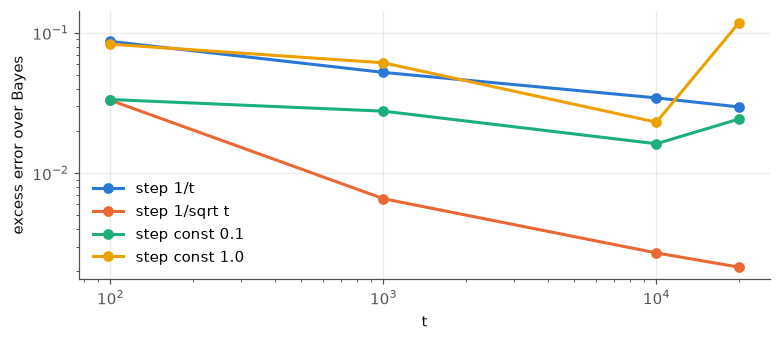

In [36]:
# Figure: excess test error over Bayes at the four checkpoints, per schedule — the SAME four runs the table above printed
# (traj21, stored by the section), not a fresh replicate
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for name, col in zip(("1/t", "1/sqrt t", "const 0.1", "const 1.0"), (C1, C2, C3, C4)):
    r_ = traj21[name]; ax.plot([t for t, _ in r_], [e - Phi(-mu) for _, e in r_], "o-", color=col, lw=2, ms=6, label=f"step {name}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("t"); ax.set_ylabel("excess error over Bayes"); ax.legend(); plt.show()

### §22 — Peeking, and the test martingale that survives it

Under a fair coin, a $z$-test at a fixed $n = 10{,}000$ rejects 5% of the time. The same test *checked every 100 samples*
rejects 38% of the time: optional stopping turns $\alpha = 0.05$ into a coin flip. The test martingale
$E_n = \prod(1 \pm \lambda(2x_i - 1))$, stopped when it exceeds $1/\alpha = 20$, rejects under 5% of the time **at every
stopping rule** (Ville's inequality). A/B tests read daily and "we'll
run until it's significant" are the second row; anytime-valid inference is the third. Picking the best checkpoint on one fixed
validation set is the sibling, selection bias — a maximum over correlated estimates — not a stopping-time problem.

In [37]:
sec(
    22,
    "Optional stopping: peeking at a z-test every 100 samples up to 10,000 vs a test martingale with Ville's inequality (alpha = 0.05)",
)
reps, N_, look = 4000, 10_000, 100
fp_peek = 0
fp_ville = 0
fp_fixed = 0
lam = 0.5
for _ in range(reps):
    x = rng.integers(0, 2, N_).astype(float)  # null: fair coin, mean 0.5
    S = np.cumsum(x - 0.5)
    ns = np.arange(1, N_ + 1)
    z = S[look - 1 :: look] / (0.5 * np.sqrt(ns[look - 1 :: look]))
    if np.any(np.abs(z) > 1.96):
        fp_peek += 1
    if abs(z[-1]) > 1.96:
        fp_fixed += 1
    # test martingale: product of (1 + lam*(2x-1)) with lam in (-1,1) -> nonneg martingale with E=1 under null; two-sided via mixture of +lam/-lam
    E_plus = np.cumprod(1 + lam * (2 * x - 1))
    E_minus = np.cumprod(1 - lam * (2 * x - 1))
    E = 0.5 * (E_plus + E_minus)
    if np.any(E >= 1 / 0.05):
        fp_ville += 1
print(f"fixed-n z-test at n=10,000:            false positive rate {fp_fixed/reps:.4f}")
print(f"z-test peeked every 100 (100 looks):   false positive rate {fp_peek/reps:.4f}")
print(
    f"test martingale, stop when E_n >= 20:  false positive rate {fp_ville/reps:.4f}   (Ville: <= 0.05 at EVERY stopping rule)"
)


=== §22 Optional stopping: peeking at a z-test every 100 samples up to 10,000 vs a test martingale with Ville's inequality (alpha = 0.05) ===


fixed-n z-test at n=10,000:            false positive rate 0.0460
z-test peeked every 100 (100 looks):   false positive rate 0.3835
test martingale, stop when E_n >= 20:  false positive rate 0.0437   (Ville: <= 0.05 at EVERY stopping rule)


## Chains: ergodicity, Metropolis, Langevin, diffusion

### §23 — Example E4: the AR(1) chain's effective sample size

$2{,}000$ chains of $10{,}000$ steps at $\phi = 0.9$: the variance of the time average, times $n$, is $19$ against the i.i.d.
value of $1$. The ergodic theorem says the average converges; the Markov-chain CLT says at what rate — and the
rate is the i.i.d. one divided by $(1+\phi)/(1-\phi)$.

In [38]:
sec(
    23,
    "E4 — AR(1) with phi = 0.9, unit stationary variance: ESS fraction (1-phi)/(1+phi), measured variance of the time average",
)
phi, n, reps = 0.9, 10_000, 2000
e = rng.standard_normal((n, reps)) * sqrt(1 - phi**2)
x = rng.standard_normal(reps)
acc = x.copy()
for t in range(1, n):
    x = phi * x + e[t]
    acc += x
means = acc / n
print(
    f"var(time average) * n = {means.var()*n:.3f};  theory (1+phi)/(1-phi) = {(1+phi)/(1-phi):.3f};  ESS = n*(1-phi)/(1+phi) = {n*(1-phi)/(1+phi):.0f} of {n}"
)
print(
    f"    (SE of the line above: var(time average) * n ± {se_var(means)*n:.3f}   — sqrt((m4 - s^4)/reps) x n from the same {reps:,} independent replicated time averages)"
)


=== §23 E4 — AR(1) with phi = 0.9, unit stationary variance: ESS fraction (1-phi)/(1+phi), measured variance of the time average ===


var(time average) * n = 19.906;  theory (1+phi)/(1-phi) = 19.000;  ESS = n*(1-phi)/(1+phi) = 526 of 10000
    (SE of the line above: var(time average) * n ± 0.614   — sqrt((m4 - s^4)/reps) x n from the same 2,000 independent replicated time averages)


### §24 — Metropolis–Hastings versus step size

The flagship's version of `B17`: acceptance, integrated autocorrelation time and effective samples per $10^4$
draws for four step sizes ($30$ at step $0.1$, $2{,}314$ at step $2.4$, $884$ at step $10$), with the sample variance as a sanity check that every chain targets $\mathcal N(0,1)$.

In [39]:
sec(
    24,
    "Metropolis–Hastings for N(0,1) with a Gaussian random walk: acceptance and integrated autocorrelation vs step size",
)


def mh(step, n=200_000):
    x = 0.0
    xs = np.empty(n)
    acc = 0
    u = np.log(rng.uniform(0, 1, n))
    prop = rng.standard_normal(n) * step
    for t in range(n):
        y = x + prop[t]
        if u[t] < -0.5 * (y * y - x * x):
            x = y
            acc += 1
        xs[t] = x
    return xs, acc / n


for step in (0.1, 0.5, 2.4, 10.0):
    xs, a = mh(step)
    xc = xs - xs.mean()
    var = xc.var()
    rho = [np.dot(xc[:-k], xc[k:]) / ((len(xc) - k) * var) for k in range(1, 400)]
    tau = 1 + 2 * sum(r for r in rho if r > 0.01)
    print(
        f"step={step:>4}: acceptance {a:.3f}, integrated autocorrelation time ~ {tau:6.1f}, ESS per 10^4 draws ~ {10_000/tau:7.0f}, sample var {var:.3f}"
    )


=== §24 Metropolis–Hastings for N(0,1) with a Gaussian random walk: acceptance and integrated autocorrelation vs step size ===


step= 0.1: acceptance 0.968, integrated autocorrelation time ~  336.3, ESS per 10^4 draws ~      30, sample var 1.010


step= 0.5: acceptance 0.844, integrated autocorrelation time ~   25.1, ESS per 10^4 draws ~     399, sample var 0.997


step= 2.4: acceptance 0.442, integrated autocorrelation time ~    4.3, ESS per 10^4 draws ~    2314, sample var 0.994


step=10.0: acceptance 0.126, integrated autocorrelation time ~   11.3, ESS per 10^4 draws ~     884, sample var 0.985


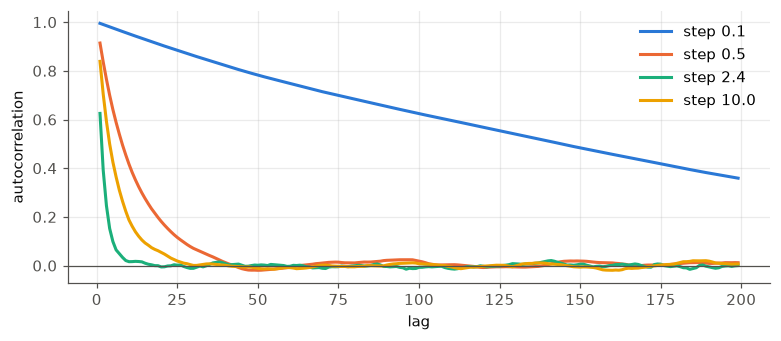

In [40]:
# Figure: the autocorrelation function of the chain at each step size
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for st, col in zip((0.1, 0.5, 2.4, 10.0), (C1, C2, C3, C4)):
    xs_, _ = mh(st, n=50_000); xc_ = xs_ - xs_.mean()
    acf = [np.dot(xc_[:-k_], xc_[k_:])/np.dot(xc_, xc_) for k_ in range(1, 200)]
    ax.plot(range(1, 200), acf, color=col, lw=2, label=f"step {st}")
ax.axhline(0, color="#52514e", lw=0.8); ax.set_xlabel("lag"); ax.set_ylabel("autocorrelation"); ax.legend(); plt.show()

### §25 — Unadjusted Langevin has a bias, and we know its size

$x \leftarrow x - hx + \sqrt{2h}\,\xi$ targets $\mathcal N(0,1)$ only as $h \to 0$; at finite $h$ its stationary variance is
$1/(1 - h/2)$ — $1.05$ at $h = 0.1$, $2$ at $h = 1$ — and the measurement matches to three decimals. The discretisation
error of a sampler is a bias, not a variance, and no number of steps removes it; a Metropolis correction does.

In [41]:
sec(
    25,
    "Unadjusted Langevin for N(0,1): x <- x - h x + sqrt(2h) xi has stationary variance 1/(1 - h/2), not 1",
)
for h in (0.01, 0.1, 0.5, 1.0):
    n = 2_000_000 if h < 0.05 else 400_000
    x = 0.0
    xs = np.empty(n)
    xi = rng.standard_normal(n)
    for t in range(n):
        x = x - h * x + sqrt(2 * h) * xi[t]
        xs[t] = x
    print(
        f"h={h:<5}: measured stationary var {xs[int(20/h):].var():.4f}   theory 1/(1-h/2) = {1/(1-h/2):.4f}"
    )
    ys25 = xs[int(20 / h) :]
    nb25 = 100
    yb25 = ys25[: len(ys25) // nb25 * nb25].reshape(nb25, -1)
    print(
        f"    (SE of the line above: measured stationary var ± {yb25.var(axis=1).std(ddof=1)/sqrt(nb25):.4f}   — batch means, {nb25} batches of {len(ys25)//nb25:,} steps of the same chain;  AR(1) asymptotic sqrt((2/n)(1 + rho^2)/(1 - rho^2)) x var with rho = 1 - h: {sqrt(2/len(ys25)*(1 + (1-h)**2)/(1 - (1-h)**2))*ys25.var():.4f})"
    )


=== §25 Unadjusted Langevin for N(0,1): x <- x - h x + sqrt(2h) xi has stationary variance 1/(1 - h/2), not 1 ===


h=0.01 : measured stationary var 1.0056   theory 1/(1-h/2) = 1.0050
    (SE of the line above: measured stationary var ± 0.0106   — batch means, 100 batches of 19,980 steps of the same chain;  AR(1) asymptotic sqrt((2/n)(1 + rho^2)/(1 - rho^2)) x var with rho = 1 - h: 0.0100)


h=0.1  : measured stationary var 1.0595   theory 1/(1-h/2) = 1.0526
    (SE of the line above: measured stationary var ± 0.0073   — batch means, 100 batches of 3,998 steps of the same chain;  AR(1) asymptotic sqrt((2/n)(1 + rho^2)/(1 - rho^2)) x var with rho = 1 - h: 0.0073)


h=0.5  : measured stationary var 1.3317   theory 1/(1-h/2) = 1.3333
    (SE of the line above: measured stationary var ± 0.0040   — batch means, 100 batches of 3,999 steps of the same chain;  AR(1) asymptotic sqrt((2/n)(1 + rho^2)/(1 - rho^2)) x var with rho = 1 - h: 0.0038)


h=1.0  : measured stationary var 2.0043   theory 1/(1-h/2) = 2.0000
    (SE of the line above: measured stationary var ± 0.0047   — batch means, 100 batches of 3,999 steps of the same chain;  AR(1) asymptotic sqrt((2/n)(1 + rho^2)/(1 - rho^2)) x var with rho = 1 - h: 0.0045)


### §26 — Diffusion is the time reversal of a chain

Forward: an Ornstein–Uhlenbeck process from a two-point mixture ($-2$ with probability $0.3$, $+2$ with $0.7$) to $T = 3$,
where it is nearly $\mathcal N(0,1)$. Reverse: Anderson's time-reversed SDE with the *exact* score of the forward marginal,
3,000 Euler steps. The samples land on $\pm 2$ with the right weights and a spread near zero. A diffusion model is
this cell with the score replaced by a network, and its error is three separate terms, which the flagship's §9.4 tells you to
diagnose separately: the score approximation; the Euler discretisation (the $0.045$ spread here is the last step's $\sqrt{2\,dt}$,
and the rate at which it shrinks with the step is something to measure on your sampler, not assume); and the terminal-prior
mismatch — starting from $\mathcal N(0,1)$ instead of the exact $p_T$, which at $T = 3$ still has means $\pm 2e^{-3}$.

In [42]:
sec(
    26,
    "Diffusion as SDE reversal: OU forward on a two-point mixture, reverse with the EXACT score recovers the modes",
)


# forward: dx = -x dt + sqrt2 dW, T = 3, from x0 in {-2 (prob 0.3), +2 (prob 0.7)}; marginal at t is a mixture of N(m e^{-t}, 1-e^{-2t})
def score(x, t):
    m = 2 * exp(-t)
    v = 1 - exp(-2 * t)
    w1, w2 = 0.3, 0.7
    p1 = w1 * np.exp(-((x + m) ** 2) / (2 * v))
    p2 = w2 * np.exp(-((x - m) ** 2) / (2 * v))
    return (-(x + m) / v * p1 - (x - m) / v * p2) / (p1 + p2)


T, K, n = 3.0, 3000, 100_000
dt_ = T / K
x = (
    rng.standard_normal(n) * sqrt(1 - exp(-2 * T)) + 0
)  # start near the stationary N(0,1): mixture at T has means ±2e^-3 ≈ ±0.1
for k in range(K):
    t = T - k * dt_
    # reverse SDE (Anderson): dx = [-x - 2*score] (-dt) ... in reverse-time form: x <- x + (x + 2 score(x,t)) dt + sqrt(2 dt) xi
    x = x + (x + 2 * score(x, t)) * dt_ + sqrt(2 * dt_) * rng.standard_normal(n)
pneg = np.mean(x < 0)
npos = int(np.sum(x > 0))
print(
    f"reverse-time OU with exact score, T=3, {K} steps: mass at x<0 = {np.mean(x<0):.4f} (target 0.300), mean of x>0 group = {x[x>0].mean():.3f} (target 2.0), sd {x[x>0].std():.3f} (noise of the last Euler step, sqrt(2 dt) = {sqrt(2*dt_):.3f}; exact target 0 at t = 0)"
)
print(
    f"(SE of the line above, from the same {n:,} paths: mass at x<0 ± {sqrt(pneg*(1-pneg)/n):.4f} (binomial);  mean of the x>0 group ± {x[x>0].std()/sqrt(npos):.4f} (sd/sqrt({npos:,}));  the mass is {abs(pneg-0.3)/sqrt(pneg*(1-pneg)/n):.1f} SE from 0.300 and the mean {abs(x[x>0].mean()-2.0)/(x[x>0].std()/sqrt(npos)):.1f} SE from 2.0)"
)


=== §26 Diffusion as SDE reversal: OU forward on a two-point mixture, reverse with the EXACT score recovers the modes ===


reverse-time OU with exact score, T=3, 3000 steps: mass at x<0 = 0.3022 (target 0.300), mean of x>0 group = 2.000 (target 2.0), sd 0.045 (noise of the last Euler step, sqrt(2 dt) = 0.045; exact target 0 at t = 0)
(SE of the line above, from the same 100,000 paths: mass at x<0 ± 0.0015 (binomial);  mean of the x>0 group ± 0.0002 (sd/sqrt(69,781));  the mass is 1.5 SE from 0.300 and the mean 1.4 SE from 2.0)


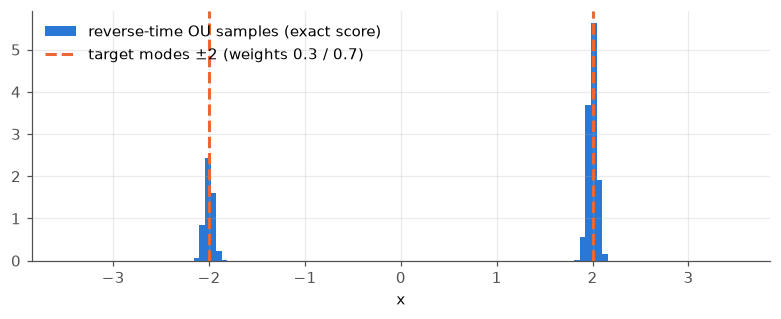

In [43]:
# Figure: the reverse-time samples recover the two modes with the right weights
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.hist(x, bins=120, range=(-3.5, 3.5), density=True, color=C1, label="reverse-time OU samples (exact score)")
ax.axvline(-2, color=C2, lw=2, ls="--"); ax.axvline(2, color=C2, lw=2, ls="--", label="target modes ±2 (weights 0.3 / 0.7)")
ax.set_xlabel("x"); ax.legend(loc="upper left"); plt.show()

## Minimax, exchangeability, infinite width, and two final traps

### §27 — Le Cam's two-point bound, and the nonparametric rate

For a Gaussian mean with $n = 100$: two hypotheses $\sigma/\sqrt n$ apart cannot be told apart, so no estimator beats a
constant times $\sigma^2/n$ — and the sample mean achieves it. The second table is the minimax rate for density
estimation at smoothness $s = 2$, $n^{-4/(4+d)}$: at $d = 10$ it is $0.0027$ at $n = 10^9$; at $d = 100$ it is $0.45$ at $n = 10^9$,
and reaching $0.01$ would take $10^{52}$ samples. This is the curse of dimensionality as a theorem, and the reason "learn the density" is
only possible under structure the theorem does not assume.

In [44]:
sec(27, "Minimax: Le Cam two-point for a Gaussian mean, and the nonparametric density rate n^(-2s/(2s+d))")
sigma, n = 1.0, 100
# two-point: theta0 = 0, theta1 = delta; KL(P0^n || P1^n) = n delta^2 / (2 sigma^2); choose delta so KL = 1/2 -> delta = sigma/sqrt(n)
delta = sigma / sqrt(n)
print(
    f"n={n}, sigma=1: Le Cam separation delta = sigma/sqrt n = {delta:.3f}; Le Cam lower bound on minimax MSE >= (delta/2)^2 * (1 - sqrt(KL/2)) / 2 = {(delta/2)**2*(1-sqrt(0.5/2))/2:.6f};  sample-mean risk sigma^2/n = {sigma**2/n:.5f}"
)
print("nonparametric density estimation, smoothness s=2, squared-L2 minimax rate n^(-2s/(2s+d)):")
for d in (1, 2, 10, 100, 1000):
    for n in (10**4, 10**6, 10**9):
        print(f"  d={d:>5} n=10^{int(round(math.log10(n)))}: rate = {n**(-4/(4+d)):.2e}", end="")
    print()
print("  n needed for rate 0.01 at s=2: " + ", ".join(f"d={d}: 10^{(4+d)/4*2:g}" for d in (1, 2, 10, 100)))


=== §27 Minimax: Le Cam two-point for a Gaussian mean, and the nonparametric density rate n^(-2s/(2s+d)) ===
n=100, sigma=1: Le Cam separation delta = sigma/sqrt n = 0.100; Le Cam lower bound on minimax MSE >= (delta/2)^2 * (1 - sqrt(KL/2)) / 2 = 0.000625;  sample-mean risk sigma^2/n = 0.01000
nonparametric density estimation, smoothness s=2, squared-L2 minimax rate n^(-2s/(2s+d)):
  d=    1 n=10^4: rate = 6.31e-04  d=    1 n=10^6: rate = 1.58e-05  d=    1 n=10^9: rate = 6.31e-08
  d=    2 n=10^4: rate = 2.15e-03  d=    2 n=10^6: rate = 1.00e-04  d=    2 n=10^9: rate = 1.00e-06
  d=   10 n=10^4: rate = 7.20e-02  d=   10 n=10^6: rate = 1.93e-02  d=   10 n=10^9: rate = 2.68e-03
  d=  100 n=10^4: rate = 7.02e-01  d=  100 n=10^6: rate = 5.88e-01  d=  100 n=10^9: rate = 4.51e-01
  d= 1000 n=10^4: rate = 9.64e-01  d= 1000 n=10^6: rate = 9.46e-01  d= 1000 n=10^9: rate = 9.21e-01
  n needed for rate 0.01 at s=2: d=1: 10^2.5, d=2: 10^3, d=10: 10^7, d=100: 10^52


### §28 — The Pólya urn: exchangeable, not independent, with a latent

Draws from a Pólya urn are exchangeable but not independent, and the limiting red fraction over $20{,}000$ urns is
uniform on $[0,1]$ — de Finetti's latent, with its prior. Every "i.i.d. given $\theta$" model — a Bayesian model, a
mixed-effects model, a dataset of users each with their own rate — is this theorem read from right to left.

In [45]:
sec(
    28,
    "Exchangeable but not independent: the Pólya urn, and de Finetti's latent (the limiting fraction is Beta(1,1))",
)
reps, n = 20_000, 2000
a = np.ones(reps)
b = np.ones(reps)
for _ in range(n):
    red = rng.uniform(size=reps) < a / (a + b)
    a += red
    b += ~red
fr = (a - 1) / n
print(
    f"P(first ball red) = 0.5; P(second red | first red) = 2/3; P(second red) = {0.5*2/3+0.5*1/3:.4f} = P(first red): exchangeable, not independent"
)
h, _ = np.histogram(fr, bins=5, range=(0, 1))
print(f"limiting red fraction over {reps:,} urns, 5 bins: {h/h.sum()}  (Beta(1,1) = uniform -> 0.2 each)")
print(
    f"(SE of the line above: each bin frequency ± {sqrt(0.2*0.8/reps):.4f}, binomial sqrt(0.2 · 0.8 / {reps:,}); the farthest entry is {np.max(np.abs(h/h.sum()-0.2))/sqrt(0.2*0.8/reps):.1f} SE from 0.2)"
)


=== §28 Exchangeable but not independent: the Pólya urn, and de Finetti's latent (the limiting fraction is Beta(1,1)) ===


P(first ball red) = 0.5; P(second red | first red) = 2/3; P(second red) = 0.5000 = P(first red): exchangeable, not independent
limiting red fraction over 20,000 urns, 5 bins: [0.2011 0.2047 0.1957 0.1981 0.2004]  (Beta(1,1) = uniform -> 0.2 each)
(SE of the line above: each bin frequency ± 0.0028, binomial sqrt(0.2 · 0.8 / 20,000); the farthest entry is 1.7 SE from 0.2)


### §29 — Infinite width is a central limit theorem

A one-hidden-layer ReLU network with $1/\sqrt{\text{width}}$ output scaling, evaluated at two unit inputs at angle
$\arccos 0.6$. The output variance is $0.5$ and the covariance between the two outputs is the
arc-cosine kernel (Cho & Saul 2009), $0.3388$, *at every width* — these are population moments of the finite-width network,
and the printed values differ from them only by Monte Carlo error (the SE line under each width). What changes with width is
the *law*: the excess kurtosis goes to $0$ as $15/N$ (`§32`), and the output is a Gaussian process only in the limit. This is the
NNGP *prior* at initialisation — a kernel the architecture fixes, not a predictor; what training does is the NTK story, a
different theorem (flagship §6.6) — and it is `§10` with neurons as the summands.

In [46]:
sec(
    29,
    "Infinite width is a CLT: one hidden ReLU layer, output at two inputs, vs the arc-cosine kernel (Cho & Saul 2009)",
)
x1 = np.array([1.0, 0.0])
x2 = np.array([0.6, 0.8])  # unit vectors, angle = acos(0.6)
theta = math.acos(0.6)
k_arccos = (1 / (2 * pi)) * (
    math.sin(theta) + (pi - theta) * math.cos(theta)
)  # kernel for ||x||=1 with var-1 weights, normalised by width
for width in (10, 100, 1000, 10000):
    reps, chunk = 20000, 500
    f1 = np.empty(reps)
    f2 = np.empty(reps)
    for c in range(0, reps, chunk):
        W = rng.standard_normal((chunk, width, 2))
        v = rng.standard_normal((chunk, width))
        h1 = np.maximum(W @ x1, 0)
        h2 = np.maximum(W @ x2, 0)
        f1[c : c + chunk] = (v * h1).sum(1) / sqrt(width)
        f2[c : c + chunk] = (v * h2).sum(1) / sqrt(width)
    print(
        f"width={width:>6}: var f(x1) = {f1.var():.4f} (theory 0.5000 = k(x1,x1)), cov(f(x1), f(x2)) = {np.mean(f1*f2):.4f} (arc-cos kernel {k_arccos:.4f}), excess kurtosis of f(x1) = {np.mean(((f1-f1.mean())/f1.std())**4)-3:+.3f}"
    )
    print(
        f"        (SE of the line above, from the same {reps:,} networks: var ± {se_var(f1):.4f};  cov ± {np.std(f1*f2)/sqrt(reps):.4f} (sd of the products / sqrt n);  the kurtosis SE at this width is §41's, not sqrt(24/n))"
    )


=== §29 Infinite width is a CLT: one hidden ReLU layer, output at two inputs, vs the arc-cosine kernel (Cho & Saul 2009) ===
width=    10: var f(x1) = 0.4876 (theory 0.5000 = k(x1,x1)), cov(f(x1), f(x2)) = 0.3313 (arc-cos kernel 0.3388), excess kurtosis of f(x1) = +1.472
        (SE of the line above, from the same 20,000 networks: var ± 0.0064;  cov ± 0.0052 (sd of the products / sqrt n);  the kurtosis SE at this width is §41's, not sqrt(24/n))
width=   100: var f(x1) = 0.4870 (theory 0.5000 = k(x1,x1)), cov(f(x1), f(x2)) = 0.3274 (arc-cos kernel 0.3388), excess kurtosis of f(x1) = +0.156
        (SE of the line above, from the same 20,000 networks: var ± 0.0051;  cov ± 0.0043 (sd of the products / sqrt n);  the kurtosis SE at this width is §41's, not sqrt(24/n))


width=  1000: var f(x1) = 0.4968 (theory 0.5000 = k(x1,x1)), cov(f(x1), f(x2)) = 0.3376 (arc-cos kernel 0.3388), excess kurtosis of f(x1) = +0.016
        (SE of the line above, from the same 20,000 networks: var ± 0.0050;  cov ± 0.0042 (sd of the products / sqrt n);  the kurtosis SE at this width is §41's, not sqrt(24/n))


width= 10000: var f(x1) = 0.4978 (theory 0.5000 = k(x1,x1)), cov(f(x1), f(x2)) = 0.3387 (arc-cos kernel 0.3388), excess kurtosis of f(x1) = +0.029
        (SE of the line above, from the same 20,000 networks: var ± 0.0050;  cov ± 0.0042 (sd of the products / sqrt n);  the kurtosis SE at this width is §41's, not sqrt(24/n))


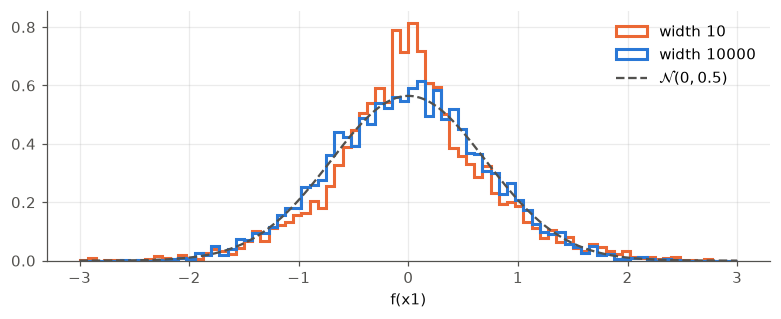

In [47]:
# Figure: the output distribution at width 10 and 10,000 against the limiting Gaussian
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for wd, col in zip((10, 10000), (C2, C1)):
    W_ = rng.standard_normal((4000, wd, 2)); v_ = rng.standard_normal((4000, wd))
    f_ = (v_*np.maximum(W_@x1, 0)).sum(1)/sqrt(wd)
    ax.hist(f_, bins=80, range=(-3, 3), density=True, histtype="step", lw=2, color=col, label=f"width {wd}")
g = np.linspace(-3, 3, 200); ax.plot(g, np.exp(-g**2)/sqrt(pi), color="#52514e", lw=1.5, ls="--", label=r"$\mathcal{N}(0, 0.5)$")
ax.set_xlabel("f(x1)"); ax.legend(); plt.show()

### §30 — St Petersburg

The flagship's run of the game with infinite expectation: the sample mean at $n = 10^2 \dots 10^6$ grows like
$\log_2 n$ (Feller: $S_n/(n\log_2 n) \to 1$ in probability, slowly — $25.0$ at $n = 10^6$ against $\log_2 10^6 = 19.9$) and never settles.

In [48]:
sec(30, "St Petersburg: a game with infinite expectation, and what the sample mean of n games does")
n = 1_000_000
k = rng.geometric(0.5, n)  # number of tosses until first head
pay = 2.0**k
print(
    "sample mean of 2^K at n = 10^2..10^6:",
    [round(float(pay[:m].mean()), 1) for m in (100, 1000, 10000, 100000, 1000000)],
    "  (grows like log2(n) — Feller: S_n/(n log2 n) -> 1 in probability — and never settles)",
)


=== §30 St Petersburg: a game with infinite expectation, and what the sample mean of n games does ===
sample mean of 2^K at n = 10^2..10^6: [11.1, 10.2, 10.7, 17.2, 25.0]   (grows like log2(n) — Feller: S_n/(n log2 n) -> 1 in probability — and never settles)


### §31 — Hoeffding versus Bernstein on a 1% rate

The flagship's version of `B19`: on $n = 10{,}000$ Bernoulli(0.01) trials, Hoeffding's half-width ($0.0136$) exceeds the rate it is
bounding, Bernstein's ($0.0029$) is three true standard deviations ($0.0010$).

In [49]:
sec(
    31, "Hoeffding vs Bernstein when the variance is small: Bernoulli(0.01), n=10,000, delta=0.05 half-widths"
)
p, n, delta = 0.01, 10_000, 0.05
hoeff = sqrt(log(2 / delta) / (2 * n))
bern = sqrt(2 * p * (1 - p) * log(2 / delta) / n) + 2 * log(2 / delta) / (3 * n)
print(
    f"Hoeffding half-width {hoeff:.4f};  Bernstein half-width {bern:.4f};  the true sd {sqrt(p*(1-p)/n):.4f}"
)


# §32–§39. Each section below uses its OWN generator (g32 … g39, seeded 2026_1016_NN) and never
# the shared `rng`, so the §1–§31 output above (ending in the first DONE marker) does not depend on them.


=== §31 Hoeffding vs Bernstein when the variance is small: Bernoulli(0.01), n=10,000, delta=0.05 half-widths ===
Hoeffding half-width 0.0136;  Bernstein half-width 0.0029;  the true sd 0.0010


---
# Part III — Sections `§32`–`§39`

Eight further sections of the flagship. Each draws from its own generator
(`g32` … `g39`, seeded `2026_1016_NN`), never the shared one, so the `§1`–`§31` numbers above are untouched and these
cells print the same numbers wherever they are run; `§32` and `§35` are pure arithmetic with no draws at all.

### §32 — The §29 kurtosis has an exact finite-width value: $15/N$

No draws. With $Z = v\,\mathrm{ReLU}(g)$ for independent standard normals, $\mathbb E[Z^2] = 1/2$ and $\mathbb E[Z^4] = 9/2$ (a
deterministic grid integral of the normal density confirms the half-Gaussian moments to four decimals), so $Z$ has excess
kurtosis exactly $15$ and the width-$N$ output of `§29` has $15/N$: $+1.5$, $+0.15$, $+0.015$, $+0.0015$. A sample kurtosis
over $20{,}000$ Gaussian replicates has Monte Carlo standard error $\sqrt{24/20000} = 0.0346$, and every `§29` measurement
sits within one standard error of the theory — including the $+0.029$ at width $10^4$, which is noise, not a
finite-width effect. The Gaussian $0.0346$ is the SE only in the limit: `§41` (Part IV) measures it per width as
$0.1198$ / $0.0433$ / $0.0366$ / $0.0348$ at $N = 10, 100, 1000, 10^4$, which makes the width-$10$ discrepancy $0.23$ SE rather than
the $0.81$ printed here; the conclusion is unchanged. Flagship §6.6.

In [50]:
sec(
    32,
    "Exact finite-width excess kurtosis of the §29 ReLU network: 15/N, with the Monte Carlo standard error of the sample kurtosis",
)
# Z = v * ReLU(g), v and g independent N(0,1); f(x1) = sum_i Z_i / sqrt(N), so excess kurtosis of f = excess kurtosis of Z / N.
# Half-Gaussian moments: E[ReLU(g)^2] = E[g^2]/2 = 1/2, E[ReLU(g)^4] = E[g^4]/2 = 3/2; E[v^2] = 1, E[v^4] = 3.
# Numerical cross-check with a deterministic grid integral of the standard normal density (no random draws).
_gx = np.linspace(-12, 12, 2_000_001)
_gw = np.exp(-(_gx**2) / 2) / sqrt(2 * pi) * (_gx[1] - _gx[0])
E_relu2 = float(np.sum(np.maximum(_gx, 0) ** 2 * _gw))
E_relu4 = float(np.sum(np.maximum(_gx, 0) ** 4 * _gw))
E_v4 = float(np.sum(_gx**4 * _gw))
E_Z2 = 1.0 * E_relu2
E_Z4 = E_v4 * E_relu4
kappa_Z = E_Z4 / E_Z2**2 - 3
print(
    f"E[ReLU(g)^2] = {E_relu2:.4f} (theory 1/2), E[ReLU(g)^4] = {E_relu4:.4f} (theory 3/2), E[v^4] = {E_v4:.4f} (theory 3)"
)
print(
    f"Z = v*ReLU(g): E[Z^2] = {E_Z2:.4f} (theory 1/2), E[Z^4] = {E_Z4:.4f} (theory 9/2), excess kurtosis E[Z^4]/E[Z^2]^2 - 3 = {kappa_Z:.4f} (theory 15)"
)
se_kurt = sqrt(24 / 20000)
print(
    f"MC standard error of the sample excess kurtosis, 20,000 Gaussian replicates: sqrt(24/20000) = {se_kurt:.4f}"
)
for N, meas in ((10, 1.472), (100, 0.156), (1000, 0.016), (10000, 0.029)):
    th = 15 / N
    print(
        f"width={N:>6}: theory 15/N = {th:+.4f}   §29 measured {meas:+.3f}   |measured - theory| / SE = {abs(meas-th)/se_kurt:.2f}"
    )


=== §32 Exact finite-width excess kurtosis of the §29 ReLU network: 15/N, with the Monte Carlo standard error of the sample kurtosis ===


E[ReLU(g)^2] = 0.5000 (theory 1/2), E[ReLU(g)^4] = 1.5000 (theory 3/2), E[v^4] = 3.0000 (theory 3)
Z = v*ReLU(g): E[Z^2] = 0.5000 (theory 1/2), E[Z^4] = 4.5000 (theory 9/2), excess kurtosis E[Z^4]/E[Z^2]^2 - 3 = 15.0000 (theory 15)
MC standard error of the sample excess kurtosis, 20,000 Gaussian replicates: sqrt(24/20000) = 0.0346
width=    10: theory 15/N = +1.5000   §29 measured +1.472   |measured - theory| / SE = 0.81
width=   100: theory 15/N = +0.1500   §29 measured +0.156   |measured - theory| / SE = 0.17
width=  1000: theory 15/N = +0.0150   §29 measured +0.016   |measured - theory| / SE = 0.03
width= 10000: theory 15/N = +0.0015   §29 measured +0.029   |measured - theory| / SE = 0.79


### §33 — The score-function gradient when the support moves with the parameter

$X \sim U(0,\theta)$, $f(x) = x$, so $\partial_\theta\,\mathbb E[X] = 1/2$. The naive score-function (REINFORCE) estimator
$\mathbb E[f(X)\,\partial_\theta \log p_\theta(X)] = \mathbb E[-X/\theta]$ gives $-0.5014 \pm 0.0006$ — the wrong sign — because
the Leibniz rule's boundary term $f(\theta)\,p_\theta(\theta) = 1$ was dropped; adding it back gives $+0.4986$, and a finite
difference with common random numbers gives $+0.5014$. The identity behind `§18` holds when the boundary term vanishes — a support
that does not move with the parameter is the usual sufficient condition, not a necessary one; a moving support on which
$f\,p_\theta$ vanishes at the boundary is fine too. Flagship §3.3.

In [51]:
sec(
    33,
    "Score-function gradient with a parameter-dependent support: X ~ U(0, theta), f(x) = x — the naive estimator gives -1/2, the boundary term 1 restores the true 1/2",
)
g33 = np.random.default_rng(2026_1016_33)
theta, n = 2.0, 200_000
U = g33.uniform(0, 1, n)
X = theta * U
print(f"true d/dtheta E[X] = d/dtheta (theta/2) = {0.5:.4f}")
naive = X * (-1 / theta)  # f(x) * d/dtheta log p_theta(x) = x * (-1/theta)
print(
    f"naive score-function estimate E[X * d/dtheta log p_theta(X)] = E[-X/theta] = {naive.mean():+.4f}   (SE {naive.std(ddof=1)/sqrt(n):.4f}; theory -1/2)"
)
boundary = theta * (1 / theta)  # f(theta) * p_theta(theta) * d(theta)/d(theta)
print(f"boundary term f(theta) p_theta(theta) = theta * (1/theta) = {boundary:.4f}")
print(f"corrected = naive + boundary = {naive.mean()+boundary:+.4f}   (theory +0.5000)")
h = 0.01
fd = (np.mean((theta + h) * U) - np.mean((theta - h) * U)) / (
    2 * h
)  # common random numbers: same U at theta +/- h
print(f"finite-difference check with common random numbers, theta ± {h}: {fd:+.4f}   (theory +0.5000)")


=== §33 Score-function gradient with a parameter-dependent support: X ~ U(0, theta), f(x) = x — the naive estimator gives -1/2, the boundary term 1 restores the true 1/2 ===
true d/dtheta E[X] = d/dtheta (theta/2) = 0.5000
naive score-function estimate E[X * d/dtheta log p_theta(X)] = E[-X/theta] = -0.5014   (SE 0.0006; theory -1/2)
boundary term f(theta) p_theta(theta) = theta * (1/theta) = 1.0000
corrected = naive + boundary = +0.4986   (theory +0.5000)
finite-difference check with common random numbers, theta ± 0.01: +0.5014   (theory +0.5000)


### §34 — What a constant step does, and does not do, on the noisy quadratic

$f(x) = x^2/2$ from $x_0 = 5$ with three gradient oracles. (a) Exact gradient: $x_t = 5(1-\alpha)^t$, geometric convergence.
(b) Additive noise $g_t = x_t + \xi_t$: the iterate is an AR(1) whose stationary variance is $\alpha/(2-\alpha)$ — $0.3333$,
$0.0526$, $0.0050$ at $\alpha = 0.5, 0.1, 0.01$, measured to four decimals over the last $10{,}000$ steps of $200$ chains — a
floor that no number of steps removes, only a smaller step. (c) Multiplicative noise $g_t = x_t(1+\zeta_t)$, which vanishes at
the optimum: $|x_t|$ contracts like $e^{-0.1068\,t}$, slightly *faster* than the noiseless $e^{-0.1054\,t}$ — but only because the
contraction condition $\mathbb E\log\lvert 1 - \alpha(1+\zeta)\rvert < 0$ holds at this noise level; vanishing noise is not enough
on its own, and `§40`'s $\zeta = \pm 20$ has $\mathbb E\log\lvert m\rvert = +0.58 > 0$ and diverges on every path. "A constant step
does not converge" is only claim (b); this is the theorem behind the constant-step rows of `§21`. Flagship §8.4.

In [52]:
sec(
    34,
    "Constant-step SGD on the noisy quadratic f(x) = x^2/2: exact gradient converges, additive noise leaves a floor alpha sigma^2/(2 - alpha), noise that vanishes at the optimum converges a.s. only under the contraction condition E log|1 - alpha(1+zeta)| < 0",
)
g34 = np.random.default_rng(2026_1016_34)
x0, T, chains = 5.0, 20_000, 200
# (a) exact gradient g_t = x_t: x_{t+1} = (1 - alpha) x_t
alpha = 0.1
print(
    f"(a) exact gradient, alpha={alpha}: "
    + "   ".join(
        f"|x_{t}| = {abs(x0*(1-alpha)**t):.4e} (theory (1-alpha)^t * 5 = {x0*(1-alpha)**t:.4e})"
        for t in (10, 100, 1000)
    )
)
# (b) additive noise g_t = x_t + xi_t, xi ~ N(0,1): x_{t+1} = (1-alpha) x_t - alpha xi_t -> stationary var alpha^2/(1-(1-alpha)^2) = alpha/(2-alpha)
for alpha in (0.5, 0.1, 0.01):
    x = np.full(chains, x0)
    acc2 = 0.0
    acc1 = 0.0
    acc1c = np.zeros(chains)
    acc2c = np.zeros(chains)  # per-chain sums for the SE line (same iterates, no new draw)
    xi = g34.standard_normal((T, chains))
    for t in range(T):
        x = x - alpha * (x + xi[t])
        if t >= T // 2:
            acc1 += x.sum()
            acc2 += (x * x).sum()
            acc1c += x
            acc2c += x * x
    m = acc1 / (chains * (T - T // 2))
    v = acc2 / (chains * (T - T // 2)) - m * m
    print(
        f"(b) additive noise, alpha={alpha:<5}: stationary var of x_t over the last 10,000 steps x 200 chains = {v:.4f}   (theory alpha/(2-alpha) = {alpha/(2-alpha):.4f}; mean x_t {m:+.4f})"
    )
    vc = acc2c / (T - T // 2) - (acc1c / (T - T // 2)) ** 2
    print(
        f"    (SE of the line above: stationary var ± {vc.std(ddof=1)/sqrt(chains):.4f}   — SD across the {chains} independent chains of each chain's own last-10,000-step variance, divided by sqrt({chains}))"
    )
# (c) multiplicative noise g_t = x_t (1 + zeta_t), zeta ~ N(0, 0.25) (variance 0.25, sd 0.5): x_{t+1} = x_t (1 - alpha (1 + zeta_t))
alpha, zsd = 0.1, 0.5
zeta = g34.standard_normal((10_000, chains)) * zsd
logabs = np.log(x0) + np.cumsum(
    np.log(np.abs(1 - alpha * (1 + zeta))), axis=0
)  # log|x_t| tracked exactly (no underflow)
for t in (100, 1000, 10000):
    la = logabs[t - 1]
    med, p90 = np.median(la), np.percentile(la, 90)
    print(
        f"(c) multiplicative noise, alpha={alpha}, zeta sd {zsd}: t={t:>5}: median |x_t| = {exp(med):.3e} (log10 {med/log(10):+.2f}), 90th pct |x_t| = {exp(p90):.3e} (log10 {p90/log(10):+.2f})"
    )
contr = np.log(np.abs(1 - alpha * (1 + zeta)))
print(
    f"(c) expected log-contraction E log|1 - alpha(1 + zeta)| = {contr.mean():+.4f} per step (MC over {contr.size:,} draws; log(1-alpha) = {log(1-alpha):+.4f} without noise)  -> |x_t| ~ 5 exp({contr.mean():+.4f} t): noise that vanishes at the optimum converges a.s. only because this contraction condition E log|1 - alpha(1+zeta)| < 0 holds here (§40: zeta = ±20 makes it positive and the iterates diverge a.s.)"
)
_gx34 = np.linspace(-12, 12, 2_000_001)
_gw34 = np.exp(-(_gx34**2) / 2) / sqrt(2 * pi) * (_gx34[1] - _gx34[0])
print(
    f"    (SE of the line above: E log|1 - alpha(1 + zeta)| ± {contr.std(ddof=1)/sqrt(contr.size):.4f}   — sd/sqrt(n) from the same {contr.size:,} draws; exact value by Gaussian quadrature {float(np.sum(np.log(np.abs(1 - alpha*(1 + zsd*_gx34)))*_gw34)):+.4f})"
)


=== §34 Constant-step SGD on the noisy quadratic f(x) = x^2/2: exact gradient converges, additive noise leaves a floor alpha sigma^2/(2 - alpha), noise that vanishes at the optimum converges a.s. only under the contraction condition E log|1 - alpha(1+zeta)| < 0 ===
(a) exact gradient, alpha=0.1: |x_10| = 1.7434e+00 (theory (1-alpha)^t * 5 = 1.7434e+00)   |x_100| = 1.3281e-04 (theory (1-alpha)^t * 5 = 1.3281e-04)   |x_1000| = 8.7394e-46 (theory (1-alpha)^t * 5 = 8.7394e-46)


(b) additive noise, alpha=0.5  : stationary var of x_t over the last 10,000 steps x 200 chains = 0.3333   (theory alpha/(2-alpha) = 0.3333; mean x_t +0.0002)


    (SE of the line above: stationary var ± 0.0004   — SD across the 200 independent chains of each chain's own last-10,000-step variance, divided by sqrt(200))


(b) additive noise, alpha=0.1  : stationary var of x_t over the last 10,000 steps x 200 chains = 0.0526   (theory alpha/(2-alpha) = 0.0526; mean x_t -0.0005)
    (SE of the line above: stationary var ± 0.0002   — SD across the 200 independent chains of each chain's own last-10,000-step variance, divided by sqrt(200))


(b) additive noise, alpha=0.01 : stationary var of x_t over the last 10,000 steps x 200 chains = 0.0050   (theory alpha/(2-alpha) = 0.0050; mean x_t +0.0011)
    (SE of the line above: stationary var ± 0.0001   — SD across the 200 independent chains of each chain's own last-10,000-step variance, divided by sqrt(200))
(c) multiplicative noise, alpha=0.1, zeta sd 0.5: t=  100: median |x_t| = 1.169e-04 (log10 -3.93), 90th pct |x_t| = 2.297e-04 (log10 -3.64)
(c) multiplicative noise, alpha=0.1, zeta sd 0.5: t= 1000: median |x_t| = 2.447e-46 (log10 -45.61), 90th pct |x_t| = 2.036e-45 (log10 -44.69)
(c) multiplicative noise, alpha=0.1, zeta sd 0.5: t=10000: median |x_t| = 0.000e+00 (log10 -463.35), 90th pct |x_t| = 0.000e+00 (log10 -460.14)
(c) expected log-contraction E log|1 - alpha(1 + zeta)| = -0.1068 per step (MC over 2,000,000 draws; log(1-alpha) = -0.1054 without noise)  -> |x_t| ~ 5 exp(-0.1068 t): noise that vanishes at the optimum converges a.s. only because this contraction condit

    (SE of the line above: E log|1 - alpha(1 + zeta)| ± 0.0000   — sd/sqrt(n) from the same 2,000,000 draws; exact value by Gaussian quadrature -0.1069)


### §35 — McNemar: the same one-point gap, three verdicts

No draws; the exact two-sided binomial tail. On $n = 1000$ paired examples a one-point gap is $55$ wins of $100$ discordant
pairs ($p = 0.368$, $z = 1.00$) or $10$ wins of $10$ ($p = 2\cdot(1/2)^{10} = 0.00195$): the discordant count, not the gap, is
the sample. The flagship's exercise 7 — $95$ of $160$, a net $30$ wins on $n = 2{,}000$, a $1.5$-point gap — gives $p = 0.0216$. Flagship §7.6.

In [53]:
sec(
    35,
    "McNemar on a paired evaluation: the same one-point gap at n = 1,000 is noise with 100 discordant pairs and decisive with 10",
)
from math import comb


def binom_two_sided(m, k):
    """exact two-sided p = 2 * P(Bin(m, 1/2) >= k) for k >= m/2, capped at 1"""
    return min(1.0, 2 * sum(comb(m, j) for j in range(k, m + 1)) / 2**m)


for m, k, note, n_eval in (
    (100, 55, "(i)", 1000),
    (10, 10, "(ii)", 1000),
    (160, 95, "(iii) exercise 7", 2000),
):  # exercise 7 scores a 2,000-example test set
    gap = (k - (m - k)) / n_eval * 100
    p = binom_two_sided(m, k)
    z = (k - m / 2) / sqrt(m / 4)
    print(
        f"{note:<17} discordant = {m:>3}, B wins {k:>3}: gap = {gap:.1f} points of {n_eval};  exact two-sided p = {p:.6f}"
        + (
            f";  normal-approximation z = {z:.3f}"
            if note != "(ii)"
            else f"  (= 2 * (1/2)^10 = {2*0.5**10:.6f})"
        )
    )


=== §35 McNemar on a paired evaluation: the same one-point gap at n = 1,000 is noise with 100 discordant pairs and decisive with 10 ===
(i)               discordant = 100, B wins  55: gap = 1.0 points of 1000;  exact two-sided p = 0.368202;  normal-approximation z = 1.000
(ii)              discordant =  10, B wins  10: gap = 1.0 points of 1000;  exact two-sided p = 0.001953  (= 2 * (1/2)^10 = 0.001953)
(iii) exercise 7  discordant = 160, B wins  95: gap = 1.5 points of 2000;  exact two-sided p = 0.021574;  normal-approximation z = 2.372


### §36 — Two effective sample sizes that share a name

(a) Importance sampling $\mathcal N(\mu,1)$ from $\mathcal N(0,1)$: $\mathrm{ESS} = (\sum w)^2/\sum w^2$, whose limit is
$n\,e^{-\mu^2}$ — $7825$ of $10{,}000$ at $\mu = 0.5$, $47$ at $\mu = 3$, where the single largest weight carries $8\%$ of the
total. (b) The Markov-chain $\mathrm{ESS} = n/(1 + 2\sum_k \rho_k)$ on an AR(1), the autocorrelation sum truncated at the first
lag below $0.01$: $3077$, $558$, $59$ against the theory $3333$, $526$, $50$ at $\phi = 0.5, 0.9, 0.99$. One counts weight
degeneracy, the other correlation; the formulas and the diagnostics are different. Flagship §3.4 and §9.1.

In [54]:
sec(
    36,
    "Two effective sample sizes that share a name: importance-sampling ESS (sum w)^2 / sum w^2 vs Markov-chain ESS n / (1 + 2 sum rho_k)",
)
g36 = np.random.default_rng(2026_1016_36)
n = 10_000
# (a) IS: q = N(0,1), p = N(mu,1), w = p/q = exp(mu x - mu^2/2); E_q[w] = 1, E_q[w^2] = exp(mu^2) -> ESS/n -> exp(-mu^2)
xq = g36.standard_normal(n)
for mu in (0.5, 1.0, 2.0, 3.0):
    w = np.exp(mu * xq - mu * mu / 2)
    ess = w.sum() ** 2 / (w * w).sum()
    print(
        f"(a) IS, target N({mu},1) from N(0,1), n={n:,}: ESS = {ess:9.1f}, ESS/n = {ess/n:.4f}   (theory limit E[w]^2/E[w^2] = exp(-mu^2) = {exp(-mu*mu):.4f}; max weight share {w.max()/w.sum():.4f})"
    )
    A36, B36 = w.mean(), (w * w).mean()
    C36 = np.cov(w, w * w) / n
    g36v = np.array([2 * A36 / B36, -A36 * A36 / B36**2])
    se36 = sqrt(float(g36v @ C36 @ g36v))
    print(
        f"    (SE of the line above: ESS/n ± {se36:.4f}, ESS ± {n*se36:.1f}   — delta method on (mean w)^2 / mean w^2 from the same n = {n:,} weights; at mu >= 2 the weights are heavy-tailed and this SE is itself unreliable, cf. §48)"
    )
# (b) MCMC: AR(1) x_t = phi x_{t-1} + sqrt(1-phi^2) e_t; rho_k = phi^k -> ESS = n (1-phi)/(1+phi)
for phi in (0.5, 0.9, 0.99):
    e = g36.standard_normal(n) * sqrt(1 - phi**2)
    x = np.empty(n)
    x[0] = g36.standard_normal()
    for t in range(1, n):
        x[t] = phi * x[t - 1] + e[t]
    xc = x - x.mean()
    var = xc.var()
    s = 0.0
    K = 0
    for k in range(1, n // 2):
        r = np.dot(xc[:-k], xc[k:]) / ((n - k) * var)
        if r < 0.01:
            break
        s += r
        K = k
    tau = 1 + 2 * s
    print(
        f"(b) AR(1) phi={phi:<4}, n={n:,}: theory ESS = n(1-phi)/(1+phi) = {n*(1-phi)/(1+phi):7.1f};  empirical (rho_k summed to lag {K}, first rho_k < 0.01) tau = {tau:6.1f}, ESS = n/tau = {n/tau:7.1f}"
    )
    se_tau = tau * sqrt(2 * (2 * K + 1) / n)
    print(
        f"    (SE of the line above: tau ± {se_tau:.1f}, ESS = n/tau ± {n*se_tau/tau**2:.1f}   — Sokal's asymptotic Var(tau_hat) ~ 2(2K + 1) tau^2/n with the window K = {K}, from the same chain)"
    )


=== §36 Two effective sample sizes that share a name: importance-sampling ESS (sum w)^2 / sum w^2 vs Markov-chain ESS n / (1 + 2 sum rho_k) ===
(a) IS, target N(0.5,1) from N(0,1), n=10,000: ESS =    7824.6, ESS/n = 0.7825   (theory limit E[w]^2/E[w^2] = exp(-mu^2) = 0.7788; max weight share 0.0006)
    (SE of the line above: ESS/n ± 0.0039, ESS ± 39.1   — delta method on (mean w)^2 / mean w^2 from the same n = 10,000 weights; at mu >= 2 the weights are heavy-tailed and this SE is itself unreliable, cf. §48)
(a) IS, target N(1.0,1) from N(0,1), n=10,000: ESS =    3737.7, ESS/n = 0.3738   (theory limit E[w]^2/E[w^2] = exp(-mu^2) = 0.3679; max weight share 0.0025)
    (SE of the line above: ESS/n ± 0.0138, ESS ± 138.4   — delta method on (mean w)^2 / mean w^2 from the same n = 10,000 weights; at mu >= 2 the weights are heavy-tailed and this SE is itself unreliable, cf. §48)
(a) IS, target N(2.0,1) from N(0,1), n=10,000: ESS =     325.1, ESS/n = 0.0325   (theory limit E[w]^2/E[w^2] = exp

### §37 — Error bars on §22, and a martingale that bets on several $\lambda$ at once

(a) The `§22` rates come from $4{,}000$ replications, so the martingale's $0.0437$ carries a standard error of $0.0032$ and
the peeked $z$-test's $0.3835$ one of $0.0077$. (b) A fixed $\lambda = 0.5$ only grows when $P(1)$ is far from $1/2$ — its
expected log-growth at $p = 0.6$ is $-0.0340$ per step — so it crosses $20$ in only $41\%$ of runs; the mixture of eight
branches ($\lambda \in \{0.1, 0.2, 0.3, 0.5\}$, both signs) crosses in $100\%$ of runs at $p = 0.6$ (median $169$ steps) and
at $p = 0.55$ (median $771$), while its null false-positive rate stays at $0.0465$, under Ville's $0.05$. A mixture is free
under the null and decisive under the alternative. Flagship §8.2.

In [55]:
sec(
    37,
    "Monte Carlo standard errors for the §22 false-positive rates, and a mixture test martingale that bets on several lambdas at once",
)
g37 = np.random.default_rng(2026_1016_37)
R22 = 4000
for name, p in (
    ("fixed-n z-test", 0.0460),
    ("z-test peeked every 100", 0.3835),
    ("test martingale E_n >= 20", 0.0437),
):
    print(
        f"(a) §22 {name:<27} rate {p:.4f} at {R22:,} replications: SE = sqrt(p(1-p)/{R22}) = {sqrt(p*(1-p)/R22):.4f}"
    )
lams = (0.1, 0.2, 0.3, 0.5)
for p1 in (0.6, 0.55):
    print(
        f"(b) growth rate per step at P(1)={p1}: "
        + ", ".join(f"lambda={l}: {p1*log(1+l)+(1-p1)*log(1-l):+.4f}" for l in lams)
        + "   (p log(1+lambda) + (1-p) log(1-lambda); the optimum is lambda = 2p-1)"
    )
reps, N_, thresh = 2000, 10_000, 20.0


def run_martingales(p1):
    """returns (crossed, cross_time) for the 8-branch mixture and for the fixed lambda=0.5 two-sided (§22) martingale"""
    Emix = np.ones((8, reps))
    Efix = np.ones((2, reps))
    t_mix = np.full(reps, -1)
    t_fix = np.full(reps, -1)
    for t in range(N_):
        s = 2.0 * (g37.uniform(0, 1, reps) < p1) - 1.0  # ±1 with P(+1) = p1
        for j, l in enumerate(lams):
            Emix[2 * j] *= 1 + l * s
            Emix[2 * j + 1] *= 1 - l * s
        Efix[0] *= 1 + 0.5 * s
        Efix[1] *= 1 - 0.5 * s
        new = (t_mix < 0) & (Emix.mean(0) >= thresh)
        t_mix[new] = t + 1
        new = (t_fix < 0) & (Efix.mean(0) >= thresh)
        t_fix[new] = t + 1
    return t_mix, t_fix


t_mix, t_fix = run_martingales(0.5)
fp = np.mean(t_mix >= 0)
fpf = np.mean(t_fix >= 0)
print(
    f"(b) null P(1)=0.5, {reps:,} replications, n={N_:,}: mixture (8 branches) false-positive rate of 'stop when E_n >= 20' = {fp:.4f} (SE {sqrt(fp*(1-fp)/reps):.4f});  fixed lambda=0.5 (§22) = {fpf:.4f} (SE {sqrt(fpf*(1-fpf)/reps):.4f});  Ville bound 0.0500"
)
for p1 in (0.6, 0.55):
    t_mix, t_fix = run_martingales(p1)
    cm, cf = np.mean(t_mix >= 0), np.mean(t_fix >= 0)
    med_m = np.median(t_mix[t_mix >= 0]) if cm > 0 else float('nan')
    med_f = np.median(t_fix[t_fix >= 0]) if cf > 0 else float('nan')
    print(
        f"(b) alternative P(1)={p1}: mixture crosses 20 by n={N_:,} in {cm:.4f} of runs, median crossing time {med_m:.0f};  fixed lambda=0.5 crosses in {cf:.4f} of runs, median crossing time {med_f:.0f}"
    )
    print(
        f"    (SE of the line above: mixture fraction ± {sqrt(cm*(1-cm)/reps):.4f}, median crossing time ± {se_median(t_mix[t_mix >= 0]):.0f};  fixed lambda=0.5 fraction ± {sqrt(cf*(1-cf)/reps):.4f}, median ± {se_median(t_fix[t_fix >= 0]):.0f}   — binomial SEs from the same {reps:,} runs; median SEs are half the order-statistic 68% interval of the crossing times)"
    )


=== §37 Monte Carlo standard errors for the §22 false-positive rates, and a mixture test martingale that bets on several lambdas at once ===
(a) §22 fixed-n z-test              rate 0.0460 at 4,000 replications: SE = sqrt(p(1-p)/4000) = 0.0033
(a) §22 z-test peeked every 100     rate 0.3835 at 4,000 replications: SE = sqrt(p(1-p)/4000) = 0.0077
(a) §22 test martingale E_n >= 20   rate 0.0437 at 4,000 replications: SE = sqrt(p(1-p)/4000) = 0.0032
(b) growth rate per step at P(1)=0.6: lambda=0.1: +0.0150, lambda=0.2: +0.0201, lambda=0.3: +0.0147, lambda=0.5: -0.0340   (p log(1+lambda) + (1-p) log(1-lambda); the optimum is lambda = 2p-1)
(b) growth rate per step at P(1)=0.55: lambda=0.1: +0.0050, lambda=0.2: -0.0001, lambda=0.3: -0.0162, lambda=0.5: -0.0889   (p log(1+lambda) + (1-p) log(1-lambda); the optimum is lambda = 2p-1)


(b) null P(1)=0.5, 2,000 replications, n=10,000: mixture (8 branches) false-positive rate of 'stop when E_n >= 20' = 0.0465 (SE 0.0047);  fixed lambda=0.5 (§22) = 0.0485 (SE 0.0048);  Ville bound 0.0500


(b) alternative P(1)=0.6: mixture crosses 20 by n=10,000 in 1.0000 of runs, median crossing time 169;  fixed lambda=0.5 crosses in 0.4065 of runs, median crossing time 61
    (SE of the line above: mixture fraction ± 0.0000, median crossing time ± 6;  fixed lambda=0.5 fraction ± 0.0110, median ± 4   — binomial SEs from the same 2,000 runs; median SEs are half the order-statistic 68% interval of the crossing times)


(b) alternative P(1)=0.55: mixture crosses 20 by n=10,000 in 1.0000 of runs, median crossing time 771;  fixed lambda=0.5 crosses in 0.0930 of runs, median crossing time 34
    (SE of the line above: mixture fraction ± 0.0000, median crossing time ± 24;  fixed lambda=0.5 fraction ± 0.0065, median ± 3   — binomial SEs from the same 2,000 runs; median SEs are half the order-statistic 68% interval of the crossing times)


`§38` and `§46` call `fit_logreg`, which the script defines inside `§4` (a cell of notebook 00); it is in this notebook's setup
cell, verbatim, as is `Phi`, so either cell runs on its own right after setup.

### §38 — The §4.3 learning curve with an error bar

`§4` fitted logistic regression once per $n$; here it is $20$ independent training sets per $n$ against one held-out set of
$100{,}000$ (whose own Bayes-classifier error is $0.1596$ against $\Phi(-1) = 0.1587$). Mean excess risk
$0.0948 \pm 0.0081$, $0.0301 \pm 0.0017$, $0.0037 \pm 0.0002$, $0.0014 \pm 0.0001$ at $n = 50, 200, 2000, 20000$. The decade from
$200$ to $2000$ gives a ratio of $8.23$ against $\Phi(-1)$ and $10.75$ against the held-out set's own Bayes error — a $d/n$ rate,
not the $\sqrt{10} = 3.16$ of $1/\sqrt n$. In the last decade the two ratios ($2.68$ and $6.47$) split, because the held-out
set's sampling offset of $0.0009$ is most of an excess of $0.0014$. Flagship §4.3.

In [56]:
sec(
    38,
    "The §4.3 learning curve over 20 independent training sets per n: mean excess risk, its standard error, and the per-decade ratio",
)
g38 = np.random.default_rng(2026_1016_38)
mu, dsz, reps38, n_ho = 1.0, 20, 20, 100_000
bayes = Phi(-mu)
yho = g38.integers(0, 2, n_ho) * 2 - 1
Xho = g38.standard_normal((n_ho, dsz))
Xho[:, 0] += mu * yho
print(
    f"held-out set: {n_ho:,} points drawn once; Bayes classifier error on it {np.mean(np.sign(Xho[:,0]) != yho):.4f} (theory Phi(-1) = {bayes:.4f})"
)
bayes_ho = np.mean(
    np.sign(Xho[:, 0]) != yho
)  # the held-out set's own Bayes-classifier error (its sampling offset from Phi(-1))
exc = {}
exc_ho = {}
with np.errstate(over='ignore'):
    for ntr in (50, 200, 2000, 20000):
        errs = np.empty(reps38)
        for r in range(reps38):
            ytr = g38.integers(0, 2, ntr) * 2 - 1
            Xtr = g38.standard_normal((ntr, dsz))
            Xtr[:, 0] += mu * ytr
            w = fit_logreg(Xtr, ytr, iters=25)
            errs[r] = np.mean(np.sign(Xho @ w) != yho)
        exc[ntr] = errs - bayes
        exc_ho[ntr] = errs - bayes_ho
        print(
            f"n_train={ntr:>6}, d=20, {reps38} reps: mean held-out error {errs.mean():.4f}, mean excess over Bayes Phi(-1) {exc[ntr].mean():+.4f}, SE of the mean excess {exc[ntr].std(ddof=1)/sqrt(reps38):.4f}  (min {errs.min():.4f}, max {errs.max():.4f}; excess over the held-out set's own Bayes error {bayes_ho:.4f}: {exc_ho[ntr].mean():+.4f})"
        )
for a, b in ((50, 200), (200, 2000), (2000, 20000)):
    r_n = b / a
    print(
        f"excess({a})/excess({b}) = {exc[a].mean()/exc[b].mean():.2f} against Phi(-1), {exc_ho[a].mean()/exc_ho[b].mean():.2f} against the held-out set's Bayes error   (n ratio {r_n:g}: a 1/sqrt(n) rate predicts sqrt({r_n:g}) = {sqrt(r_n):.2f}, a d/n rate predicts {r_n:g})"
    )


=== §38 The §4.3 learning curve over 20 independent training sets per n: mean excess risk, its standard error, and the per-decade ratio ===
held-out set: 100,000 points drawn once; Bayes classifier error on it 0.1596 (theory Phi(-1) = 0.1587)


n_train=    50, d=20, 20 reps: mean held-out error 0.2535, mean excess over Bayes Phi(-1) +0.0948, SE of the mean excess 0.0081  (min 0.2099, max 0.3431; excess over the held-out set's own Bayes error 0.1596: +0.0939)


n_train=   200, d=20, 20 reps: mean held-out error 0.1888, mean excess over Bayes Phi(-1) +0.0301, SE of the mean excess 0.0017  (min 0.1737, max 0.2053; excess over the held-out set's own Bayes error 0.1596: +0.0292)


n_train=  2000, d=20, 20 reps: mean held-out error 0.1623, mean excess over Bayes Phi(-1) +0.0037, SE of the mean excess 0.0002  (min 0.1612, max 0.1641; excess over the held-out set's own Bayes error 0.1596: +0.0027)


n_train= 20000, d=20, 20 reps: mean held-out error 0.1600, mean excess over Bayes Phi(-1) +0.0014, SE of the mean excess 0.0001  (min 0.1594, max 0.1605; excess over the held-out set's own Bayes error 0.1596: +0.0004)
excess(50)/excess(200) = 3.15 against Phi(-1), 3.22 against the held-out set's Bayes error   (n ratio 4: a 1/sqrt(n) rate predicts sqrt(4) = 2.00, a d/n rate predicts 4)
excess(200)/excess(2000) = 8.23 against Phi(-1), 10.75 against the held-out set's Bayes error   (n ratio 10: a 1/sqrt(n) rate predicts sqrt(10) = 3.16, a d/n rate predicts 10)
excess(2000)/excess(20000) = 2.68 against Phi(-1), 6.47 against the held-out set's Bayes error   (n ratio 10: a 1/sqrt(n) rate predicts sqrt(10) = 3.16, a d/n rate predicts 10)


### §39 — Median-of-means on a heavy tail

Pareto(1.5) has a mean ($3$) and no variance. Over $1{,}000$ replications at $n = 10{,}000$, the sample mean's *empirical* RMSE is $0.29$
— its population RMSE is infinite, since the mean of Pareto($1.5$) draws has no variance, so another $1{,}000$ replications can
print a very different number (`§53`: $0.18$ to $0.98$ across twenty batches) — with a 99th-percentile error of $0.71$ and a worst case of $6.5$; median-of-means over $20$ blocks of $500$ has RMSE $0.19$,
99th-percentile error $0.34$ and worst case $0.40$ — but a bias of $-0.17$, since the median of a right-skewed block mean sits
below its mean. The robust estimator trades a bias for its tail. Flagship §6.4.

In [57]:
sec(
    39,
    "Median-of-means on Pareto(alpha = 1.5): a finite-variance-free estimator against the sample mean, n = 10,000, 1,000 replications",
)
g39 = np.random.default_rng(2026_1016_39)
alpha, n, reps39, blocks = 1.5, 10_000, 1000, 20
true_mean = alpha / (alpha - 1)  # x_min = 1, same construction as §11: U^(-1/alpha)
par = g39.uniform(0, 1, (reps39, n)) ** (-1 / alpha)
sm = par.mean(1)
mom = np.median(par.reshape(reps39, blocks, n // blocks).mean(2), axis=1)
print(
    f"Pareto(1.5), x_min=1: true mean alpha/(alpha-1) = {true_mean:.4f}; n={n:,}, {reps39:,} replications, median-of-means with {blocks} blocks of {n//blocks}"
)
for name, est in (("sample mean    ", sm), ("median-of-means", mom)):
    err = est - true_mean
    ae = np.abs(err)
    print(
        f"{name}: RMSE {np.sqrt(np.mean(err**2)):.4f}, median |error| {np.median(ae):.4f}, 99th pct |error| {np.percentile(ae, 99):.4f}   (bias = mean error {err.mean():+.4f}, max |error| {ae.max():.3f})"
    )


# §40–§46 are appended AFTER the "DONE (§32–§39)" marker so that the first 255 output lines stay byte-identical.
# Each section owns its generator gNN = default_rng(2026_1016_NN) and never touches the shared `rng`.


=== §39 Median-of-means on Pareto(alpha = 1.5): a finite-variance-free estimator against the sample mean, n = 10,000, 1,000 replications ===


Pareto(1.5), x_min=1: true mean alpha/(alpha-1) = 3.0000; n=10,000, 1,000 replications, median-of-means with 20 blocks of 500
sample mean    : RMSE 0.2926, median |error| 0.1096, 99th pct |error| 0.7080   (bias = mean error -0.0167, max |error| 6.490)
median-of-means: RMSE 0.1880, median |error| 0.1688, 99th pct |error| 0.3412   (bias = mean error -0.1661, max |error| 0.396)


---
# Part IV — Sections `§40`–`§46`

Seven further sections, printed after the `DONE (§32–§39)` marker of `worked_numbers_output.txt`, so nothing above
them depends on them. Each draws from its own generator (`g40` … `g46`, seeded
`2026_1016_NN`), never the shared one; `§44` is pure arithmetic with no draws at all. `§46` calls `fit_logreg`, which is in the
setup cell.

### §40 — Multiplicative-noise SGD: almost-sure convergence while the second moment diverges

$x_{t+1} = x_t\,(1 - \alpha(1+\zeta_t))$ on $f(x) = x^2/2$ with $\alpha = 0.1$. (a) $\zeta = \pm 5$: the multipliers are $0.4 / 1.4$, so
$\mathbb E\log|m| = \tfrac12\ln 0.56 = -0.2899 < 0$ (almost-sure contraction) while $\mathbb E[m^2] = 1.06 > 1$ (mean-square blow-up).
Over $2{,}000$ paths the median $|x_t|$ is $5.07\times10^{-7}$, $2.57\times10^{-13}$, $6.59\times10^{-26}$ at $t = 50, 100, 200$ and every
path is below $10^{-6}$ by $t = 200$ — yet the exact $\mathbb E[x_t^2] = 1.06^t$ grows, and the Monte Carlo mean ($1.210$, $0.742$,
$0.0866$ at $t = 10, 20, 40$ against $1.791$, $3.207$, $10.29$) undershoots it because the mean is carried by paths rarer than $1$ in
$2{,}000$. (b) $\zeta = \pm 20$: $\mathbb E\log|m| = +0.5800 > 0$ and all $2{,}000$ paths exceed $10^6$ by $t = 100$. (c) The two exact
scalar conditions, with the `§34`(c) Gaussian case by quadrature: $\mathcal N(0, 0.5^2)$ converges in both senses ($-0.1069$, $0.8125$);
$\pm 5$ converges a.s. and diverges in $L^2$; $\pm 20$ diverges in both. (d) Additive noise at $\alpha = 1$, $\xi = \pm 1$: $x_{t+1} = -\xi_t$
is a two-point law on $\{-1, +1\}$ (excess kurtosis $-2.0$) whose variance $1.0000$ still matches $\alpha\sigma^2/(2-\alpha)$ — the
formula fixes the variance, not the shape. Flagship §8.4.

In [58]:
sec(
    40,
    "Multiplicative-noise SGD on f(x) = x^2/2: a.s. convergence with E[x_t^2] -> infinity, and the two exact contraction conditions",
)
g40 = np.random.default_rng(2026_1016_40)
alpha, x0, paths, T40 = 0.1, 1.0, 2000, 200
# x_{t+1} = x_t (1 - alpha (1 + zeta_t)); zeta = ±5 equiprobable -> multipliers 0.4 / 1.4
m_lo, m_hi = 1 - alpha * (1 + 5), 1 - alpha * (1 - 5)
Elog, Em2 = 0.5 * (log(abs(m_lo)) + log(abs(m_hi))), 0.5 * (m_lo**2 + m_hi**2)
print(
    f"(a) zeta = ±5, alpha={alpha}, x_0={x0}: multipliers {m_lo:.1f} / {m_hi:.1f};  E log|m| = (1/2) ln(0.56) = {Elog:+.4f} < 0 (a.s. contraction)   E[m^2] = (0.16 + 1.96)/2 = {Em2:.2f} > 1 (mean-square blow-up)   [exact]"
)
mult = np.where(g40.integers(0, 2, (T40, paths)) == 0, m_lo, m_hi)
logabs = log(x0) + np.cumsum(np.log(np.abs(mult)), axis=0)  # log|x_t| tracked exactly, as §34(c)
print(
    f"(a) {paths:,} paths: "
    + "   ".join(
        f"t={t}: median |x_t| = {exp(np.median(logabs[t-1])):.2e}, frac |x_t| < 1e-6 = {np.mean(logabs[t-1] < log(1e-6)):.4f}"
        for t in (50, 100, 200)
    )
    + f"   (theory median ~ exp({Elog:+.4f} t))"
)
print(
    f"    (SE of the line above: "
    + "   ".join(
        f"t={t}: median within a factor exp(±{se_median(logabs[t-1]):.3f}), frac ± {sqrt(np.mean(logabs[t-1] < log(1e-6))*(1 - np.mean(logabs[t-1] < log(1e-6)))/paths):.4f}"
        for t in (50, 100, 200)
    )
    + f"   — order-statistic SE of the median on the log scale and binomial SEs, from the same {paths:,} paths)"
)
Em4 = 0.5 * (m_lo**4 + m_hi**4)  # E[m^4], for the exact SD of x_t^2
for t in (10, 20, 40):
    x2 = np.exp(2 * logabs[t - 1])
    print(
        f"(a) t={t:>2}: MC mean of x_t^2 over {paths:,} paths = {x2.mean():.3e}   (exact E[x_t^2] = 1.06^{t} = {Em2**t:.3e};  max path x_t^2 = {x2.max():.3e}, median {np.median(x2):.3e} — the mean is carried by rare paths, so the MC mean undershoots the exact value once those paths are rarer than 1 in {paths:,})"
    )
    print(
        f"    (SE of the line above: MC mean of x_t^2 ± {x2.std(ddof=1)/sqrt(paths):.3e}   — sd/sqrt({paths:,}) from the same paths;  the exact SE, sqrt((E[m^4]^t - 1.06^(2t))/{paths:,}) with E[m^4] = {Em4:.4f}, is {sqrt((Em4**t - Em2**(2*t))/paths):.3e}: the empirical SE understates by the same rare-path mechanism)"
    )
# (b) zeta = ±20 -> multipliers -1.1 / 2.9
m_lo, m_hi = 1 - alpha * (1 + 20), 1 - alpha * (1 - 20)
Elog20 = 0.5 * (log(abs(m_lo)) + log(abs(m_hi)))
mult = np.where(g40.integers(0, 2, (100, paths)) == 0, m_lo, m_hi)
logabs20 = log(x0) + np.cumsum(np.log(np.abs(mult)), axis=0)
print(
    f"(b) zeta = ±20, alpha={alpha}: multipliers {m_lo:.1f} / {m_hi:.1f};  E log|m| = (1/2)(ln 1.1 + ln 2.9) = {Elog20:+.4f} > 0;  frac of {paths:,} paths with |x_100| > 1e6 = {np.mean(logabs20[99] > log(1e6)):.4f}  (median |x_100| = {exp(np.median(logabs20[99])):.2e})"
)
f20 = np.mean(logabs20[99] > log(1e6))
print(
    f"    (SE of the line above: frac ± {sqrt(f20*(1-f20)/paths):.4f} (binomial, from the same {paths:,} paths: every path exceeded 1e6);  median |x_100| within a factor exp(±{se_median(logabs20[99]):.3f}) (order-statistic SE on the log scale; exact median exp(100 E log|m|) = {exp(100*Elog20):.2e}))"
)
# (c) the two exact scalar conditions; Gaussian case by deterministic quadrature on the §32 grid (zeta = 0.5 g, g ~ N(0,1))
_gx = np.linspace(-12, 12, 2_000_001)
_gw = np.exp(-(_gx**2) / 2) / sqrt(2 * pi) * (_gx[1] - _gx[0])
mg = 1 - alpha * (1 + 0.5 * _gx)
rows = (
    ("N(0, 0.5^2) [§34(c)]", float(np.sum(np.log(np.abs(mg)) * _gw)), float(np.sum(mg**2 * _gw))),
    ("±5                 ", Elog, Em2),
    ("±20                ", Elog20, 0.5 * ((1 - alpha * 21) ** 2 + (1 - alpha * (-19)) ** 2)),
)
print(
    f"(c) alpha={alpha}: a.s. contraction iff E log|1 - alpha(1+zeta)| < 0;  mean-square contraction iff E[(1 - alpha(1+zeta))^2] < 1   (no noise: log(1-alpha) = {log(1-alpha):+.4f}, (1-alpha)^2 = {(1-alpha)**2:.4f})"
)
for name, el, em in rows:
    print(
        f"(c)   zeta ~ {name}:  E log|m| = {el:+.4f} ({'a.s. converges' if el < 0 else 'a.s. diverges '})   E[m^2] = {em:.4f} ({'L2 converges' if em < 1 else 'L2 diverges '})"
    )
# (d) additive noise, alpha = 1, xi = ±1: x_{t+1} = x_t - alpha (x_t + xi_t) = -xi_t
xi = np.where(g40.integers(0, 2, 10_000) == 0, -1.0, 1.0)
xd = np.empty(10_000)
x = x0
for t in range(10_000):
    x = x - 1.0 * (x + xi[t])
    xd[t] = x
vals, cnts = np.unique(xd, return_counts=True)
print(
    f"(d) additive noise, alpha=1, xi = ±1, 10,000 steps from x_0={x0}: x_{{t+1}} = -xi_t;  empirical support {{{', '.join(f'{v:+.0f}' for v in vals)}}} with frequencies {np.round(cnts/cnts.sum(), 4).tolist()}  — a two-point law, not Gaussian (excess kurtosis {np.mean(xd**4)/np.mean(xd**2)**2 - 3:+.1f} vs 0 for a Gaussian)"
)
p40 = np.mean(xd == 1)
print(
    f"    (SE of the line above: each frequency ± {sqrt(p40*(1-p40)/len(xd)):.4f} (binomial at p = 1/2, from the same 10,000 steps);  the excess kurtosis -2 is exact for any ±1 sample (x^4 = x^2 = 1), no SE)"
)
print(
    f"(d) stationary variance: empirical {xd.var():.4f}   (theory alpha sigma^2/(2 - alpha) = 1 * 1/(2 - 1) = {1.0*1.0/(2-1.0):.4f} still holds — the formula fixes the variance, not the shape)"
)
print(
    f"    (SE of the line above: empirical variance ± {se_var(xd):.4f}   — sqrt((m4 - s^4)/n) from the same 10,000 steps; for a ±1 sample s^2 = 1 - mean^2, so the SE is 2 |mean| sqrt(p(1-p)/n) up to O(1/n))"
)


=== §40 Multiplicative-noise SGD on f(x) = x^2/2: a.s. convergence with E[x_t^2] -> infinity, and the two exact contraction conditions ===
(a) zeta = ±5, alpha=0.1, x_0=1.0: multipliers 0.4 / 1.4;  E log|m| = (1/2) ln(0.56) = -0.2899 < 0 (a.s. contraction)   E[m^2] = (0.16 + 1.96)/2 = 1.06 > 1 (mean-square blow-up)   [exact]
(a) 2,000 paths: t=50: median |x_t| = 5.07e-07, frac |x_t| < 1e-6 = 0.5510   t=100: median |x_t| = 2.57e-13, frac |x_t| < 1e-6 = 0.9945   t=200: median |x_t| = 6.59e-26, frac |x_t| < 1e-6 = 1.0000   (theory median ~ exp(-0.2899 t))
    (SE of the line above: t=50: median within a factor exp(±0.000), frac ± 0.0111   t=100: median within a factor exp(±0.000), frac ± 0.0017   t=200: median within a factor exp(±0.000), frac ± 0.0000   — order-statistic SE of the median on the log scale and binomial SEs, from the same 2,000 paths)
(a) t=10: MC mean of x_t^2 over 2,000 paths = 1.210e+00   (exact E[x_t^2] = 1.06^10 = 1.791e+00;  max path x_t^2 = 8.367e+02, median 3.033e-

### §41 — The Monte Carlo standard error of a sample kurtosis at finite width

`§32` used the Gaussian $\sqrt{24/m} = 0.0346$ for the SE of a sample excess kurtosis over $m = 20{,}000$ replicates. Here the `§29`
model is sampled exactly at any width — conditional on the $K \sim \mathrm{Bin}(N, 1/2)$ active units, $f = \sqrt{S/N}\,u$ with
$S \mid K \sim \chi^2_K$ — and the estimate is replicated $R = 1{,}000$ times per width. The empirical SD is $0.1198$, $0.0433$, $0.0366$,
$0.0348$ at $N = 10, 100, 1000, 10^4$, against the asymptotic $\sqrt{(24 + 1080/N + 12810/N^2 + 32490/N^3)/m}$ ($0.1210$, $0.0425$,
$0.0354$, $0.0347$; ratios $0.991$ to $1.033$), and the replicated means ($+1.4965 \pm 0.0038$, $+0.1472 \pm 0.0014$, $+0.0161 \pm 0.0012$,
$+0.0015 \pm 0.0011$) agree with $15/N$. The direct `§29` sampler gives the same SD ($0.1199$ at $N = 10$ over $400$ reps, $0.0426$ at
$N = 100$ over $100$). The Gaussian figure understates the SE by $3.5\times$ at width $10$. Flagship §6.6.

In [59]:
sec(
    41,
    "Monte Carlo standard error of the sample excess kurtosis at finite width: the Gaussian sqrt(24/m) understates it at small N",
)
g41 = np.random.default_rng(2026_1016_41)
# §29 model, copied exactly: f(x1) = N^{-1/2} sum_i v_i ReLU(w_i . x1), w_i ~ N(0, I_2), v_i ~ N(0,1), x1 = e_1, so g_i = w_i . x1 ~ N(0,1).
# Exact sampler of the same law: conditional on g, f ~ N(0, S/N) with S = sum_i ReLU(g_i)^2 = sum of K squared normals, K ~ Bin(N, 1/2):
#   f = sqrt(S/N) u,  K ~ Bin(N, 1/2),  S | K ~ chi^2_K (= Gamma(K/2, scale 2); S = 0 when K = 0),  u ~ N(0,1).   Three draws per f at any width.
m41, R41 = (
    20_000,
    1000,
)  # R = 1,000 replicated estimates per width (the exact sampler costs ~2 s per 400 at any width)


def excess_kurt(f):
    return np.mean(((f - f.mean()) / f.std()) ** 4) - 3  # the §29 estimator


def kurt_reps_exact(N, R):
    K = g41.binomial(N, 0.5, (R, m41))
    S = g41.gamma(K / 2, 2.0)
    u = g41.standard_normal((R, m41))
    f = np.sqrt(S / N) * u
    return np.array([excess_kurt(f[r]) for r in range(R)])


def kurt_reps_direct(N, R, chunk):
    out = np.empty(R)
    for r in range(R):
        f = np.empty(m41)
        for c in range(0, m41, chunk):
            W = g41.standard_normal((chunk, N, 2))
            v = g41.standard_normal((chunk, N))
            f[c : c + chunk] = (v * np.maximum(W @ np.array([1.0, 0.0]), 0)).sum(1) / sqrt(N)
        out[r] = excess_kurt(f)
    return out


se_gauss = sqrt(24 / m41)
print(
    f"(a) m = {m41:,} samples per kurtosis estimate, R = {R41} replicated estimates per width (exact sampler); Gaussian SE sqrt(24/m) = {se_gauss:.4f}; reviewer's asymptotic SE sqrt((24 + 1080/N + 12810/N^2 + 32490/N^3)/m)"
)
direct = {}
direct[10] = kurt_reps_direct(10, 400, 2000)
direct[100] = kurt_reps_direct(100, 100, 500)
for N in (10, 100, 1000, 10000):
    k = kurt_reps_exact(N, R41)
    se_rev = sqrt((24 + 1080 / N + 12810 / N**2 + 32490 / N**3) / m41)
    sd = k.std(ddof=1)
    extra = (
        f";  direct §29 sampler ({len(direct[N])} reps): SD {direct[N].std(ddof=1):.4f}, mean {direct[N].mean():+.4f}"
        if N in direct
        else ""
    )
    print(
        f"(b) width={N:>6}: empirical SD of the estimate = {sd:.4f} (its own SE ~ SD/sqrt(2(R-1)) = {sd/sqrt(2*(R41-1)):.4f})   vs (i) Gaussian {se_gauss:.4f}   (ii) reviewer {se_rev:.4f} [ratio emp/(ii) = {sd/se_rev:.3f}];   mean of the {R41} estimates {k.mean():+.4f} ± {sd/sqrt(R41):.4f} vs exact 15/N = {15/N:+.4f}{extra}"
    )


=== §41 Monte Carlo standard error of the sample excess kurtosis at finite width: the Gaussian sqrt(24/m) understates it at small N ===
(a) m = 20,000 samples per kurtosis estimate, R = 1000 replicated estimates per width (exact sampler); Gaussian SE sqrt(24/m) = 0.0346; reviewer's asymptotic SE sqrt((24 + 1080/N + 12810/N^2 + 32490/N^3)/m)


(b) width=    10: empirical SD of the estimate = 0.1198 (its own SE ~ SD/sqrt(2(R-1)) = 0.0027)   vs (i) Gaussian 0.0346   (ii) reviewer 0.1210 [ratio emp/(ii) = 0.991];   mean of the 1000 estimates +1.4965 ± 0.0038 vs exact 15/N = +1.5000;  direct §29 sampler (400 reps): SD 0.1199, mean +1.4987


(b) width=   100: empirical SD of the estimate = 0.0433 (its own SE ~ SD/sqrt(2(R-1)) = 0.0010)   vs (i) Gaussian 0.0346   (ii) reviewer 0.0425 [ratio emp/(ii) = 1.019];   mean of the 1000 estimates +0.1472 ± 0.0014 vs exact 15/N = +0.1500;  direct §29 sampler (100 reps): SD 0.0426, mean +0.1441


(b) width=  1000: empirical SD of the estimate = 0.0366 (its own SE ~ SD/sqrt(2(R-1)) = 0.0008)   vs (i) Gaussian 0.0346   (ii) reviewer 0.0354 [ratio emp/(ii) = 1.033];   mean of the 1000 estimates +0.0161 ± 0.0012 vs exact 15/N = +0.0150


(b) width= 10000: empirical SD of the estimate = 0.0348 (its own SE ~ SD/sqrt(2(R-1)) = 0.0008)   vs (i) Gaussian 0.0346   (ii) reviewer 0.0347 [ratio emp/(ii) = 1.002];   mean of the 1000 estimates +0.0015 ± 0.0011 vs exact 15/N = +0.0015


### §42 — Selecting the best of $m = 100$ fixed models: which bound is a guarantee

(a) For $X \sim \mathrm{Bernoulli}(0.8)$, $\mathbb E[e^{-(X - 0.8)}] = 1.10009 > e^{\mathrm{Var}(X)/2} = 1.08329$, so $p(1-p)$ is **not** a
valid sub-Gaussian variance proxy; Hoeffding's $1/4$ is ($e^{1/8} = 1.13315$). (b) At $n = 1{,}000$, $\sigma = \sqrt{p(1-p)/n} = 0.01265$,
the variance-proxy bound $\sigma\sqrt{2\ln m} = 0.0384$ and the Hoeffding-valid $\sqrt{\ln m/(2n)} = 0.0480$. (c) Over $2{,}000$
replications the mean of $\max_j(\mathrm{acc}_j - 0.8)$ is $0.0312$ (MC SE $0.0001$; median $0.0310$, 99th percentile $0.0440$) — under
both numbers, but the max exceeds $0.0384$ in $8.35\%$ of replications and $0.0480$ in $0.45\%$. Only the second is a proven bound on
$\mathbb E[\max]$. Flagship §7.6.

In [60]:
sec(
    42,
    "Selecting the best of m = 100 fixed models on n = 1,000 held-out examples: the variance-proxy bound sigma sqrt(2 ln m) is not a Hoeffding guarantee",
)
g42 = np.random.default_rng(2026_1016_42)
p, n42, m42, R42 = 0.8, 1000, 100, 2000
mgf = p * exp(-(1 - p)) + (1 - p) * exp(
    p
)  # E[exp(-(X - p))], X ~ Bernoulli(p), lambda = -1 (the lower tail of the accuracy)
print(
    f"(a) X ~ Bernoulli({p}): E[e^(-(X-{p}))] = {p} e^-{1-p:.1f} + {1-p:.1f} e^{p} = {mgf:.5f}  >  e^(Var(X)/2) = e^{p*(1-p)/2:.2f} = {exp(p*(1-p)/2):.5f}  -> p(1-p) is NOT a valid sub-Gaussian variance proxy;  Hoeffding's proxy 1/4 holds: e^(1/8) = {exp(1/8):.5f} >= {mgf:.5f}"
)
sigma = sqrt(p * (1 - p) / n42)
b_var, b_hoeff = sigma * sqrt(2 * log(m42)), sqrt(log(m42) / (2 * n42))
print(
    f"(b) n={n42:,}, m={m42}, p={p}: sigma = sqrt(p(1-p)/n) = {sigma:.5f};  variance-proxy bound sigma sqrt(2 ln m) = {b_var:.4f} (not a guarantee for Bernoulli)   Hoeffding-valid sqrt(ln m / (2n)) = {b_hoeff:.4f}"
)
acc = (
    g42.binomial(n42, p, (R42, m42)) / n42
)  # m independent models, each scored on its own n Bernoulli(p) correctness indicators
mx = (acc - p).max(1)
print(
    f"(c) {R42:,} replications: mean of max_j (accuracy_j - {p}) = {mx.mean():.4f} (MC SE {mx.std(ddof=1)/sqrt(R42):.4f};  median {np.median(mx):.4f}, 99th pct {np.percentile(mx, 99):.4f})   — under both {b_var:.4f} and {b_hoeff:.4f}; only the second is a proven bound on E[max]"
)
print(
    f"(c) fraction of replications whose max exceeds the variance-proxy bound {b_var:.4f}: {np.mean(mx > b_var):.4f};  exceeds the Hoeffding bound {b_hoeff:.4f}: {np.mean(mx > b_hoeff):.4f}"
)


=== §42 Selecting the best of m = 100 fixed models on n = 1,000 held-out examples: the variance-proxy bound sigma sqrt(2 ln m) is not a Hoeffding guarantee ===
(a) X ~ Bernoulli(0.8): E[e^(-(X-0.8))] = 0.8 e^-0.2 + 0.2 e^0.8 = 1.10009  >  e^(Var(X)/2) = e^0.08 = 1.08329  -> p(1-p) is NOT a valid sub-Gaussian variance proxy;  Hoeffding's proxy 1/4 holds: e^(1/8) = 1.13315 >= 1.10009
(b) n=1,000, m=100, p=0.8: sigma = sqrt(p(1-p)/n) = 0.01265;  variance-proxy bound sigma sqrt(2 ln m) = 0.0384 (not a guarantee for Bernoulli)   Hoeffding-valid sqrt(ln m / (2n)) = 0.0480
(c) 2,000 replications: mean of max_j (accuracy_j - 0.8) = 0.0312 (MC SE 0.0001;  median 0.0310, 99th pct 0.0440)   — under both 0.0384 and 0.0480; only the second is a proven bound on E[max]
(c) fraction of replications whose max exceeds the variance-proxy bound 0.0384: 0.0835;  exceeds the Hoeffding bound 0.0480: 0.0045


### §43 — The paired standard error of a checkpoint difference

Two classifiers at error rate $0.18$ on $n = 50{,}000$ examples, $D_i = \mathbf 1\{A\ \text{wrong}\} - \mathbf 1\{B\ \text{wrong}\}$. The
per-classifier SE is $0.00172$ and $\sqrt 2$ times it is $0.00243$. The exact $\mathrm{SE}(\bar D) = \sqrt{\mathrm{Var}(D)/n}$ is $0.00268$
when the errors are disjoint ($1.562\times$ the per-classifier SE — *above* $\sqrt 2\times$), $0.00243$ when independent ($1.414\times$),
and $0.00085$ when $90\%$ shared ($0.494\times$). One simulated disjoint draw gives $\bar D = +0.00388$ with empirical SE $0.00268$,
matching the exact value. $\sqrt 2 \times$SE is the independent case, not an upper bound. Flagship §7.6.

In [61]:
sec(
    43,
    "The paired standard error of a checkpoint difference is sqrt(Var(D_i)/n), and sqrt(2) x SE is not an upper bound",
)
g43 = np.random.default_rng(2026_1016_43)
pA = pB = 0.18
n43 = 50_000
se_one = sqrt(pA * (1 - pA) / n43)
print(
    f"two classifiers, error rate {pA} each, n = {n43:,}, D_i = 1{{A wrong}} - 1{{B wrong}};  per-classifier SE sqrt(0.18 * 0.82/n) = {se_one:.5f},  sqrt(2) x that = {sqrt(2)*se_one:.5f}"
)
for name, p_both in (
    ("errors disjoint        ", 0.0),
    ("errors independent     ", pA * pB),
    ("errors 90 % shared     ", 0.162),
):
    varD = (
        pA * (1 - pA) + pB * (1 - pB) - 2 * (p_both - pA * pB)
    )  # Var(1A - 1B) = Var 1A + Var 1B - 2 Cov; P(both wrong) = p_both
    print(
        f"{name}: P(both wrong) = {p_both:.4f}, Var(D) = {varD:.4f}, exact SE(D-bar) = sqrt(Var(D)/n) = {sqrt(varD/n43):.5f}   = {sqrt(varD/n43)/se_one:.3f} x per-classifier SE ({'above' if sqrt(varD/n43) > sqrt(2)*se_one else 'below'} sqrt(2) x SE = {sqrt(2)*se_one:.5f})"
    )
u = g43.uniform(0, 1, n43)
D = np.where(
    u < pA, 1.0, np.where(u < pA + pB, -1.0, 0.0)
)  # disjoint: A-only wrong w.p. 0.18, B-only wrong w.p. 0.18, neither w.p. 0.64
print(
    f"simulated disjoint case once, n = {n43:,}: mean D = {D.mean():+.5f}, empirical SE from the per-example D_i = sqrt(var(D)/n) = {D.std(ddof=1)/sqrt(n43):.5f}   (exact {sqrt(0.36/n43):.5f})"
)


=== §43 The paired standard error of a checkpoint difference is sqrt(Var(D_i)/n), and sqrt(2) x SE is not an upper bound ===
two classifiers, error rate 0.18 each, n = 50,000, D_i = 1{A wrong} - 1{B wrong};  per-classifier SE sqrt(0.18 * 0.82/n) = 0.00172,  sqrt(2) x that = 0.00243
errors disjoint        : P(both wrong) = 0.0000, Var(D) = 0.3600, exact SE(D-bar) = sqrt(Var(D)/n) = 0.00268   = 1.562 x per-classifier SE (above sqrt(2) x SE = 0.00243)
errors independent     : P(both wrong) = 0.0324, Var(D) = 0.2952, exact SE(D-bar) = sqrt(Var(D)/n) = 0.00243   = 1.414 x per-classifier SE (below sqrt(2) x SE = 0.00243)
errors 90 % shared     : P(both wrong) = 0.1620, Var(D) = 0.0360, exact SE(D-bar) = sqrt(Var(D)/n) = 0.00085   = 0.494 x per-classifier SE (below sqrt(2) x SE = 0.00243)
simulated disjoint case once, n = 50,000: mean D = +0.00388, empirical SE from the per-example D_i = sqrt(var(D)/n) = 0.00268   (exact 0.00268)


### §44 — JS saturates, $W_1$ does not — and where even $W_1$ has zero gradient

No draws. (a) $P = \delta_0$, $Q_\theta = \delta_\theta$: the Jensen–Shannon divergence is $\ln 2 = 0.6931$ at every $\theta \in \{0.1, \dots, 5\}$
(flat, zero gradient) while $W_1 = |\theta|$ with $dW_1/d\theta = +1$; a quantile-grid evaluation of $W_1$ agrees to four decimals.
(b) $P = \delta_1$, $Q_\theta = \delta_{\theta^2}$: $W_1 = |1 - \theta^2|$, $dW_1/d\theta = -2\theta\,\mathrm{sign}(1 - \theta^2)$ — $-1.0$, $-1.8$,
$+2.2$ at $\theta = 0.5, 0.9, 1.1$, but at $\theta = 0$ the distance is $1$ and the gradient exactly $0$: a Wasserstein generator can sit at
a stationary point at distance $1$. Flagship §2.4.

In [62]:
sec(44, "Where JS saturates and W1 does not, and where even a finite W1 has zero generator gradient")
uq = (
    np.arange(100_000) + 0.5
) / 100_000  # quantile grid for the 1-D formula W1 = int_0^1 |F^-1(u) - G^-1(u)| du


def js_two_points(a, b):
    """JS(delta_a, delta_b) in nats: M = (delta_a + delta_b)/2 has mass 1/2 at each point when a != b, so each KL term is ln 2"""
    return 0.0 if a == b else 0.5 * log(1 / 0.5) + 0.5 * log(1 / 0.5)


print(
    f"(a) P = delta_0, Q_theta = delta_theta:   JS in nats (ln 2 = {log(2):.4f}),  W1 = |theta|,  dW1/dtheta = sign(theta)"
)
for th in (0.1, 0.5, 1.0, 2.0, 5.0):
    w1_num = float(np.mean(np.abs(np.zeros_like(uq) - np.full_like(uq, th))))
    print(
        f"(a)   theta = {th:<4}: JS = {js_two_points(0.0, th):.4f} (= ln 2, flat in theta: zero gradient)   W1 = {abs(th):.4f} (quantile formula {w1_num:.4f})   dW1/dtheta = {math.copysign(1.0, th):+.1f}"
    )
print(
    f"(b) P = delta_1, Q_theta = delta_(theta^2):   W1 = |1 - theta^2|,  dW1/dtheta = -2 theta sign(1 - theta^2)"
)
for th in (0.0, 0.5, 0.9, 1.1):
    w1 = abs(1 - th**2)
    grad = -2 * th * math.copysign(1.0, 1 - th**2) + 0.0  # + 0.0 turns IEEE -0.0 into 0.0 at theta = 0
    w1_num = float(np.mean(np.abs(np.ones_like(uq) - np.full_like(uq, th**2))))
    print(
        f"(b)   theta = {th:<4}: W1 = {w1:.4f} (quantile formula {w1_num:.4f})   dW1/dtheta = {grad:+.4f}"
        + (
            "   <- distance 1, gradient exactly 0: the generator is stuck at a stationary point"
            if th == 0.0
            else ""
        )
    )


=== §44 Where JS saturates and W1 does not, and where even a finite W1 has zero generator gradient ===
(a) P = delta_0, Q_theta = delta_theta:   JS in nats (ln 2 = 0.6931),  W1 = |theta|,  dW1/dtheta = sign(theta)
(a)   theta = 0.1 : JS = 0.6931 (= ln 2, flat in theta: zero gradient)   W1 = 0.1000 (quantile formula 0.1000)   dW1/dtheta = +1.0
(a)   theta = 0.5 : JS = 0.6931 (= ln 2, flat in theta: zero gradient)   W1 = 0.5000 (quantile formula 0.5000)   dW1/dtheta = +1.0
(a)   theta = 1.0 : JS = 0.6931 (= ln 2, flat in theta: zero gradient)   W1 = 1.0000 (quantile formula 1.0000)   dW1/dtheta = +1.0
(a)   theta = 2.0 : JS = 0.6931 (= ln 2, flat in theta: zero gradient)   W1 = 2.0000 (quantile formula 2.0000)   dW1/dtheta = +1.0
(a)   theta = 5.0 : JS = 0.6931 (= ln 2, flat in theta: zero gradient)   W1 = 5.0000 (quantile formula 5.0000)   dW1/dtheta = +1.0
(b) P = delta_1, Q_theta = delta_(theta^2):   W1 = |1 - theta^2|,  dW1/dtheta = -2 theta sign(1 - theta^2)
(b)   theta = 0.0 : W1 

### §45 — Stationary but not ergodic

A latent fair coin $Z$ and $X_t = Z$ for every $t$. Across $1{,}000$ trajectories of $T = 1{,}000$ steps the per-trajectory sample mean is
$0$ in $0.488$ of them, $1$ in $0.512$, exactly $1/2$ in none; the marginal law is $\mathrm{Bernoulli}(1/2)$ at every $t$ (stationary), but
the variance of the time average across trajectories is $0.2501$ against an ergodic i.i.d. chain's $1/(4T) = 0.00025$ (not ergodic).
From one trajectory, the moving-block bootstrap (block $50$, $200$ resamples) and batch means ($20$ of $50$) both report $0.0000$ for a
truth of $1/4$: no amount of $T$ or resampling reveals the latent coin from a single path. Flagship §9.1.

In [63]:
sec(45, "Stationary but not ergodic: a latent fair coin Z, X_t = Z for every t")
g45 = np.random.default_rng(2026_1016_45)
R45, T45, B45, nboot = 1000, 1000, 50, 200
Z = g45.integers(0, 2, R45).astype(float)
X = np.repeat(Z[:, None], T45, axis=1)  # R trajectories of length T, each constant
means = X.mean(1)
print(
    f"{R45:,} trajectories x T = {T45:,} steps: per-trajectory sample mean takes the value 0 in {np.mean(means == 0):.3f} of trajectories, 1 in {np.mean(means == 1):.3f}, exactly 1/2 in {np.mean(means == 0.5):.3f}   (marginal law of X_t is Bernoulli(1/2) at every t: stationary ✓)"
)
print(
    f"    (SE of the line above: each fraction ± {sqrt(0.5*0.5/R45):.3f}   — binomial at p = 1/2 from the same {R45:,} trajectories)"
)
print(
    f"variance of the sample mean across trajectories: empirical {means.var(ddof=1):.4f}   (theory 1/4 = {0.25:.4f}; an ergodic iid Bernoulli(1/2) chain would give 1/(4T) = {0.25/T45:.5f})   -> time average != ensemble average: ergodic ✗"
)
print(
    f"    (SE of the line above: empirical variance ± {se_var(means):.4f}   — sqrt((m4 - s^4)/R) from the same {R45:,} trajectory means)"
)
x1 = X[0]  # ONE trajectory
starts = g45.integers(
    0, T45 - B45 + 1, (nboot, T45 // B45)
)  # moving-block bootstrap, 20 blocks of length 50 per resample
boot_means = np.array([np.concatenate([x1[s : s + B45] for s in st]).mean() for st in starts])
batch_means = x1.reshape(T45 // B45, B45).mean(1)
print(
    f"from ONE trajectory (Z = {x1[0]:.0f}): block-bootstrap variance estimate (block length {B45}, {nboot} resamples) = {boot_means.var(ddof=1):.4f};  batch-means estimate ({T45//B45} batches of {B45}) = {batch_means.var(ddof=1)/(T45//B45):.4f}   (truth 1/4)"
)
print(
    "stationary ✓, ergodic ✗: both one-trajectory estimators report zero — no amount of T or resampling reveals the latent coin from a single path"
)


=== §45 Stationary but not ergodic: a latent fair coin Z, X_t = Z for every t ===
1,000 trajectories x T = 1,000 steps: per-trajectory sample mean takes the value 0 in 0.488 of trajectories, 1 in 0.512, exactly 1/2 in 0.000   (marginal law of X_t is Bernoulli(1/2) at every t: stationary ✓)
    (SE of the line above: each fraction ± 0.016   — binomial at p = 1/2 from the same 1,000 trajectories)
variance of the sample mean across trajectories: empirical 0.2501   (theory 1/4 = 0.2500; an ergodic iid Bernoulli(1/2) chain would give 1/(4T) = 0.00025)   -> time average != ensemble average: ergodic ✗
    (SE of the line above: empirical variance ± 0.0004   — sqrt((m4 - s^4)/R) from the same 1,000 trajectory means)
from ONE trajectory (Z = 1): block-bootstrap variance estimate (block length 50, 200 resamples) = 0.0000;  batch-means estimate (20 batches of 50) = 0.0000   (truth 1/4)
stationary ✓, ergodic ✗: both one-trajectory estimators report zero — no amount of T or resampling reveals the 

### §46 — Two uncertainties on the §38 learning curve at $n = 2{,}000$

Uses `fit_logreg` from the setup cell. One shared held-out set of $100{,}000$ (its own Bayes error $0.1587$, against
$\Phi(-1) = 0.1587$) and $20$ seeds each trained on $n = 2{,}000$, $d = 20$. (a) Across seeds the mean excess is $+0.0028$ with SD
$0.0009$ and SE of the mean $0.0002$ (min $+0.0012$, max $+0.0048$). (b) Per seed, the *paired* SE of the excess on the shared set,
$\sqrt{\mathrm{Var}(D_i)/n}$ with $D_i = \mathbf 1\{\text{model wrong}\} - \mathbf 1\{\text{Bayes wrong}\}$, is $0.00054$ on average
($0.00043$ to $0.00063$) against the unpaired $0.00164$. (c) The same $20$ models on an independent second set (Bayes error $0.1580$)
give mean excess $+0.0034$ ($+0.0028$ over $\Phi(-1)$), SD $0.0011$; the shared-set offset is $-0.0006$ and the per-seed excesses
correlate at $0.856$ across the two sets — the seed variation is real, the set offset is common to every seed. Flagship §4.3.

In [64]:
sec(
    46,
    "Two uncertainties on the §38 learning curve at n = 2,000: variation across training seeds vs the paired test-set uncertainty of the excess risk",
)
g46 = np.random.default_rng(2026_1016_46)
mu, dsz, seeds46, ntr46, n_ho = 1.0, 20, 20, 2000, 100_000


def draw_e2(g, n):
    y = g.integers(0, 2, n) * 2 - 1
    X = g.standard_normal((n, dsz))
    X[:, 0] += mu * y
    return X, y


Xho1, yho1 = draw_e2(g46, n_ho)  # ONE shared held-out set, as §38
bayes_ho1 = np.mean(np.sign(Xho1[:, 0]) != yho1)
ws = []
with np.errstate(over='ignore'):
    for r in range(seeds46):
        Xtr, ytr = draw_e2(g46, ntr46)
        ws.append(fit_logreg(Xtr, ytr, iters=25))  # §4's fit_logreg, re-used
Xho2, yho2 = draw_e2(g46, n_ho)  # a SECOND independent held-out set, drawn after the training sets
bayes_ho2 = np.mean(np.sign(Xho2[:, 0]) != yho2)
err1 = np.array([np.mean(np.sign(Xho1 @ w) != yho1) for w in ws])
err2 = np.array([np.mean(np.sign(Xho2 @ w) != yho2) for w in ws])
exc1 = err1 - bayes_ho1
exc2 = err2 - bayes_ho2
print(
    f"held-out set 1: {n_ho:,} points, its own Bayes-classifier error {bayes_ho1:.4f} (population floor Phi(-1) = {Phi(-mu):.4f});  {seeds46} seeds, each trained on n = {ntr46:,}, d = {dsz}"
)
print(
    f"(a) across {seeds46} seeds on set 1: mean excess error over the set's Bayes error = {exc1.mean():+.4f} (over Phi(-1): {(err1 - Phi(-mu)).mean():+.4f});  SD across seeds = {exc1.std(ddof=1):.4f};  SE of the mean = SD/sqrt({seeds46}) = {exc1.std(ddof=1)/sqrt(seeds46):.4f}   (min {exc1.min():+.4f}, max {exc1.max():+.4f})"
)
pse = np.empty(seeds46)
for r, w in enumerate(ws):
    Dr = (np.sign(Xho1 @ w) != yho1).astype(float) - (np.sign(Xho1[:, 0]) != yho1).astype(float)
    pse[r] = Dr.std(ddof=1) / sqrt(n_ho)
print(
    f"(b) per seed, paired SE of the excess on set 1 = sqrt(Var(D_i)/{n_ho:,}), D_i = 1{{model wrong}} - 1{{Bayes wrong}}: mean {pse.mean():.5f}, min {pse.min():.5f}, max {pse.max():.5f}   (vs the unpaired sqrt(2 * 0.16 * 0.84/n) = {sqrt(2*0.16*0.84/n_ho):.5f})"
)
print(
    f"(c) the SAME {seeds46} models on an independent held-out set 2 ({n_ho:,} points, its own Bayes error {bayes_ho2:.4f}): mean excess over the set's Bayes error = {exc2.mean():+.4f} (over Phi(-1): {(err2 - Phi(-mu)).mean():+.4f});  SD across seeds {exc2.std(ddof=1):.4f}"
)
print(
    f"(c) shared-test-set offset between the two sets: mean excess set 1 - set 2 = {exc1.mean() - exc2.mean():+.4f} (raw error {err1.mean() - err2.mean():+.4f});  per-seed correlation of excess across the two sets = {np.corrcoef(exc1, exc2)[0, 1]:.3f}   — compare with the across-seed SE {exc1.std(ddof=1)/sqrt(seeds46):.4f} and the paired SE ~{pse.mean():.5f}"
)


=== §46 Two uncertainties on the §38 learning curve at n = 2,000: variation across training seeds vs the paired test-set uncertainty of the excess risk ===


held-out set 1: 100,000 points, its own Bayes-classifier error 0.1587 (population floor Phi(-1) = 0.1587);  20 seeds, each trained on n = 2,000, d = 20
(a) across 20 seeds on set 1: mean excess error over the set's Bayes error = +0.0028 (over Phi(-1): +0.0028);  SD across seeds = 0.0009;  SE of the mean = SD/sqrt(20) = 0.0002   (min +0.0012, max +0.0048)
(b) per seed, paired SE of the excess on set 1 = sqrt(Var(D_i)/100,000), D_i = 1{model wrong} - 1{Bayes wrong}: mean 0.00054, min 0.00043, max 0.00063   (vs the unpaired sqrt(2 * 0.16 * 0.84/n) = 0.00164)
(c) the SAME 20 models on an independent held-out set 2 (100,000 points, its own Bayes error 0.1580): mean excess over the set's Bayes error = +0.0034 (over Phi(-1): +0.0028);  SD across seeds 0.0011
(c) shared-test-set offset between the two sets: mean excess set 1 - set 2 = -0.0006 (raw error +0.0000);  per-seed correlation of excess across the two sets = 0.856   — compare with the across-seed SE 0.0002 and the paired SE ~0.00054


---
# Part V — Sections `§47`–`§49`

Three further sections, placed after `§46` in `worked_numbers_output.txt`, so no earlier line depends on them.
Each draws from its own generator (`g47` … `g49`, seeded
`2026_1016_NN`), never the shared one. `§48` re-creates `§36`'s draw from `§36`'s seed to quote its ESS, without touching `§36`.

### §47 — The covariance bound needs $K^2$

$X = \pm\varepsilon^{-1/2}$ with probability $\varepsilon/2$ each and $0$ otherwise: mean $0$, variance $1$, bounded. At $\varepsilon = 10^{-4}$ and
$n = 1{,}000$ the exact probability that a dataset is all zeros — so $\hat\Sigma = 0$ — is $(1 - \varepsilon)^n = 0.9048$; over $R = 20{,}000$
simulated datasets the fraction is $0.9014$ (binomial SE $0.0021$). In $d = 1$, $\hat\Sigma = N/(n\varepsilon)$ with $N \sim \mathrm{Bin}(n, \varepsilon)$,
so the mean operator-norm error is the exact finite sum $\mathbb E|N/(n\varepsilon) - 1| = 2(1-\varepsilon)^n = 1.8097$ (simulated $1.8324 \pm 0.0185$)
— $55\times$ the constant-free $\sqrt{d/n} + d/n = 0.0326$. Solving $\mathbb E\exp(X^2/t^2) = 2$ gives the exact
$K^2 = \|X\|_{\psi_2}^2 = 1/(\varepsilon\ln((1+\varepsilon)/\varepsilon)) = 1085.7$, under the bounded-variable bound $1/(\varepsilon\ln 2) = 14427.0$;
$K^2(\sqrt{d/n} + d/n) = 35.4$ does cover the error. $K^2$ tracks $1/(\varepsilon\ln(1/\varepsilon))$ ($21.7$, $144.7$, $1085.7$ at
$\varepsilon = 10^{-2}, 10^{-3}, 10^{-4}$), against a Gaussian's scale-free $8/3$. Flagship §7.4.

In [65]:
sec(
    47,
    "The covariance bound needs K^2: a bounded, mean-0, variance-1 three-point law (eps = 1e-4) whose sample covariance is 0 in nine datasets of ten at n = 1,000, d = 1",
)
g47 = np.random.default_rng(2026_1016_47)
# §47–§49 sit before the final DONE marker, after every earlier line of output; each owns its
# generator gNN = default_rng(2026_1016_NN) and never touches the shared `rng`, so the §1–§46 output does not depend on them.
eps47, n47, R47, chunk47 = 1e-4, 1000, 20_000, 1000
a47 = sqrt(1 / eps47)  # X = ±eps^(-1/2) w.p. eps/2 each, 0 w.p. 1 - eps
print(
    f"(a) X = ±eps^(-1/2) = ±{a47:.1f} w.p. eps/2 each, 0 w.p. 1 - eps, eps = {eps47:g}:  E X = 0,  E X^2 = eps * eps^(-1) = {eps47*a47**2:.4f}  [exact];  Sigma_hat = (1/n) sum X_i^2 = N/(n eps) with N ~ Bin(n, eps)"
)
p0 = (1 - eps47) ** n47
print(
    f"(b) exact P(all n = {n47:,} samples zero) = (1 - eps)^n = {p0:.4f}  -> Sigma_hat = 0, operator-norm error ||Sigma|| = 1, in that fraction of datasets"
)
allzero = np.empty(R47, dtype=bool)
s2 = np.empty(R47)
for c in range(0, R47, chunk47):
    u = g47.uniform(0, 1, (chunk47, n47))
    X = np.where(u < eps47 / 2, -a47, np.where(u < eps47, a47, 0.0))
    allzero[c : c + chunk47] = np.all(X == 0, axis=1)
    s2[c : c + chunk47] = (X * X).mean(1)
fz = allzero.mean()
print(
    f"(b) simulated, R = {R47:,} datasets of n = {n47:,}: fraction all-zero = {fz:.4f}  (binomial SE sqrt(p(1-p)/R) = {sqrt(p0*(1-p0)/R47):.4f};  |sim - exact| / SE = {abs(fz-p0)/sqrt(p0*(1-p0)/R47):.2f})"
)
err47 = np.abs(s2 - 1)
pmf = [
    comb(n47, k) * eps47**k * (1 - eps47) ** (n47 - k) for k in range(0, 61)
]  # Bin(1000, 1e-4): mass beyond k = 60 is below 1e-100
E_err = sum(pk * abs(k / (n47 * eps47) - 1) for k, pk in enumerate(pmf))
print(
    f"(c) d = 1 operator-norm error |Sigma_hat - 1|: simulated mean over R = {R47:,} = {err47.mean():.4f} (SE {err47.std(ddof=1)/sqrt(R47):.4f});  exact E|N/(n eps) - 1| = sum_k P(N=k)|k/(n eps) - 1| = {E_err:.4f}  (= 2(1 - eps)^n = {2*p0:.4f}, since E[N/(n eps)] = 1)"
)
ref = sqrt(1 / n47) + 1 / n47
K2 = 1 / (eps47 * log((1 + eps47) / eps47))
print(
    f"(c) constant-free Gaussian-type reference sqrt(d/n) + d/n at d = 1, n = {n47:,} = {ref:.4f}  -> the mean error is {E_err/ref:.0f}x it: no universal C can cover this law"
)
print(
    f"(d) ||X||_psi2 = inf{{t: E exp(X^2/t^2) <= 2}};  E exp(X^2/t^2) = 1 - eps + eps exp(1/(eps t^2)) = 2  =>  K^2 = ||X||_psi2^2 = 1/(eps ln((1 + eps)/eps)) = {K2:.1f}  (check: E exp(X^2/K^2) = {1 - eps47 + eps47*exp(1/(eps47*K2)):.6f})"
)
print(
    f"(d) the bounded-variable bound ||X||_psi2 <= ||X||_inf/sqrt(ln 2) gives K^2 <= 1/(eps ln 2) = {1/(eps47*log(2)):.1f};  K^2 (sqrt(d/n) + d/n) = {K2*ref:.1f} (C = 1), which does cover the mean error {E_err:.4f}"
)
print(
    f"(d) for contrast, a standard Gaussian: E exp(g^2/t^2) = (1 - 2/t^2)^(-1/2) = 2  =>  K^2 = 8/3 = {8/3:.4f} at every scale (absorbed into C)"
)
for e in (1e-2, 1e-3, 1e-4):
    k2 = 1 / (e * log((1 + e) / e))
    print(
        f"(e) eps = {e:g}: exact K^2 = 1/(eps ln((1+eps)/eps)) = {k2:9.1f}   1/(eps ln(1/eps)) = {1/(e*log(1/e)):9.1f} (ratio {k2*e*log(1/e):.4f})   bound 1/(eps ln 2) = {1/(e*log(2)):9.1f}   (1 - eps)^n at n = 1,000 = {(1-e)**n47:.4f}"
    )


=== §47 The covariance bound needs K^2: a bounded, mean-0, variance-1 three-point law (eps = 1e-4) whose sample covariance is 0 in nine datasets of ten at n = 1,000, d = 1 ===
(a) X = ±eps^(-1/2) = ±100.0 w.p. eps/2 each, 0 w.p. 1 - eps, eps = 0.0001:  E X = 0,  E X^2 = eps * eps^(-1) = 1.0000  [exact];  Sigma_hat = (1/n) sum X_i^2 = N/(n eps) with N ~ Bin(n, eps)
(b) exact P(all n = 1,000 samples zero) = (1 - eps)^n = 0.9048  -> Sigma_hat = 0, operator-norm error ||Sigma|| = 1, in that fraction of datasets


(b) simulated, R = 20,000 datasets of n = 1,000: fraction all-zero = 0.9014  (binomial SE sqrt(p(1-p)/R) = 0.0021;  |sim - exact| / SE = 1.63)
(c) d = 1 operator-norm error |Sigma_hat - 1|: simulated mean over R = 20,000 = 1.8324 (SE 0.0185);  exact E|N/(n eps) - 1| = sum_k P(N=k)|k/(n eps) - 1| = 1.8097  (= 2(1 - eps)^n = 1.8097, since E[N/(n eps)] = 1)
(c) constant-free Gaussian-type reference sqrt(d/n) + d/n at d = 1, n = 1,000 = 0.0326  -> the mean error is 55x it: no universal C can cover this law
(d) ||X||_psi2 = inf{t: E exp(X^2/t^2) <= 2};  E exp(X^2/t^2) = 1 - eps + eps exp(1/(eps t^2)) = 2  =>  K^2 = ||X||_psi2^2 = 1/(eps ln((1 + eps)/eps)) = 1085.7  (check: E exp(X^2/K^2) = 2.000000)
(d) the bounded-variable bound ||X||_psi2 <= ||X||_inf/sqrt(ln 2) gives K^2 <= 1/(eps ln 2) = 14427.0;  K^2 (sqrt(d/n) + d/n) = 35.4 (C = 1), which does cover the mean error 1.8097
(d) for contrast, a standard Gaussian: E exp(g^2/t^2) = (1 - 2/t^2)^(-1/2) = 2  =>  K^2 = 8/3 = 2.6667 at every sca

### §48 — Weight-based IS ESS is not a standard error

The `§36` setting at $\mu = 2$: target $\mathcal N(2, 1)$, proposal $\mathcal N(0, 1)$, $f(x) = x$, $n = 10{,}000$. Closed forms (checked by
quadrature): $\mathrm{Var}_q(wf) = 17e^4 - 4 = 924.2$, IS SE $0.3040$; SNIS asymptotic variance $5e^4 = 273.0$, SE $0.1652$. The bar
$\sqrt{\mathrm{Var}_p f/\mathrm{ESS}}$ is $0.0555$ at `§36`'s sample ESS $325.1$ — $5.48\times$ and $2.98\times$ too small — and $0.0739$ at the
population ESS $n e^{-\mu^2} = 183.2$ ($4.11\times$, $2.24\times$). The sample ESS overstates the population one in $84\%$ of replications
(median $325.3$). Over $R = 2{,}000$ replications the empirical SDs ($0.2577$, $0.1196$) sit below the closed forms because one estimate's
exact excess kurtosis is $13904$: an $R = 2{,}000$ SD has relative SE $\approx 1.3$, the variance being carried by draws a few million
samples rarely contain. Limiting cases: with $f \equiv 1$ the SNIS estimate is exactly $1$ in every replication, whatever the ESS
($13.0$ to $721.6$); with $p = q$ every weight is $1$ and $\mathrm{ESS} = n$, yet a Cauchy integrand's replicated means have IQR $2.175$ at
$n = 1{,}000$ and $2.046$ at $n = 10{,}000$ (exact $2$ at every $n$) — no $1/\sqrt n$ shrinkage, the weights blameless. Flagship §3.4.

In [66]:
sec(
    48,
    "Weight-based IS ESS is not a standard error: the §36 setting at mu = 2 (target N(2,1), proposal N(0,1), f(x) = x, n = 10,000), closed-form IS and SNIS standard errors against sqrt(Var_p f / ESS)",
)
g48 = np.random.default_rng(2026_1016_48)
mu, n48, R48, chunk48 = 2.0, 10_000, 2000, 100
var_is = (
    exp(mu * mu) * (1 + 4 * mu * mu) - mu * mu
)  # E_q[w^2 x^2] = e^(mu^2) E[(X + 2mu)^2], minus (E_q[w x])^2 = mu^2
var_snis = exp(mu * mu) * (1 + mu * mu)  # E_q[w^2 (x - mu)^2] = e^(mu^2) E[(X + mu)^2];  E_q w = 1
se_is, se_snis = sqrt(var_is / n48), sqrt(var_snis / n48)
print(
    f"(a) closed forms, from E[g(X) e^(aX)] = e^(a^2/2) E[g(X + a)] for X ~ N(0,1):  Var_q(w f) = e^(mu^2)(1 + 4 mu^2) - mu^2 = 17 e^4 - 4 = {var_is:.1f};  IS SE = sqrt({var_is:.1f}/n) = {se_is:.4f}"
)
print(
    f"(a) SNIS asymptotic variance E_q[w^2 (f - mu)^2]/(E_q w)^2 = e^(mu^2)(1 + mu^2) = 5 e^4 = {var_snis:.1f};  SNIS SE = sqrt({var_snis:.1f}/n) = {se_snis:.4f}"
)
_gx = np.linspace(-12, 12, 2_000_001)
_gw = (
    np.exp(-(_gx**2) / 2) / sqrt(2 * pi) * (_gx[1] - _gx[0])
)  # the §32 grid: deterministic quadrature under q
_w = np.exp(mu * _gx - mu * mu / 2)
print(
    f"(a) quadrature check on the §32 grid: Var_q(w f) = {float(np.sum((_w*_gx)**2*_gw)) - float(np.sum(_w*_gx*_gw))**2:.1f},  E_q[w^2 (f - mu)^2] = {float(np.sum(_w**2*(_gx - mu)**2*_gw)):.1f},  E_q[w^2] = {float(np.sum(_w**2*_gw)):.2f} (e^(mu^2) = {exp(mu*mu):.2f})"
)
ess_pop = n48 * exp(-mu * mu)
xq36 = np.random.default_rng(2026_1016_36).standard_normal(
    n48
)  # §36's draw, re-created from §36's seed (§36 itself is untouched)
w36 = np.exp(mu * xq36 - mu * mu / 2)
ess36 = w36.sum() ** 2 / (w36 * w36).sum()
bar_s, bar_p = sqrt(1 / ess36), sqrt(1 / ess_pop)
print(
    f"(b) weight-based bar sqrt(Var_p f / ESS), Var_p f = 1:  §36's sample ESS on its own draw = {ess36:.1f} -> sqrt(1/{ess36:.1f}) = {bar_s:.4f};  population ESS n/E_q[w^2] = n e^(-mu^2) = {ess_pop:.1f} -> {bar_p:.4f}"
)
print(
    f"(b) understatement: IS SE / bar = {se_is/bar_s:.2f}x (sample ESS {ess36:.1f}), {se_is/bar_p:.2f}x (population ESS {ess_pop:.1f});  SNIS SE / bar = {se_snis/bar_s:.2f}x, {se_snis/bar_p:.2f}x"
)
wf = w36 * xq36
snis36 = wf.sum() / w36.sum()
wn = w36 / w36.sum()
print(
    f"(b) from §36's single draw: IS estimate {wf.mean():.4f}, draw-based SE sd(w_i f_i)/sqrt(n) = {wf.std(ddof=1)/sqrt(n48):.4f};  SNIS estimate {snis36:.4f}, delta-method SE sqrt(sum wn_i^2 (f_i - SNIS)^2) = {sqrt(np.sum(wn**2*(xq36 - snis36)**2)):.4f}   (truth mu = {mu})"
)
is_est = np.empty(R48)
snis_est = np.empty(R48)
one_est = np.empty(R48)
ess_r = np.empty(R48)
for c in range(0, R48, chunk48):
    x = g48.standard_normal((chunk48, n48))
    w = np.exp(mu * x - mu * mu / 2)
    sw = w.sum(1)
    is_est[c : c + chunk48] = (w * x).mean(1)
    snis_est[c : c + chunk48] = (w * x).sum(1) / sw
    one_est[c : c + chunk48] = (w * 1.0).sum(1) / sw
    ess_r[c : c + chunk48] = sw**2 / (w * w).sum(1)
for name, est, se in (("IS  ", is_est, se_is), ("SNIS", snis_est, se_snis)):
    sd = est.std(ddof=1)
    print(
        f"(c) {name}, R = {R48:,} replications of n = {n48:,}: mean {est.mean():.4f} (truth {mu}, MC SE {sd/sqrt(R48):.4f}), empirical SD {sd:.4f} vs closed-form SE {se:.4f} (ratio {sd/se:.3f})"
    )
mom = [
    exp(j * (j - 1) * mu * mu / 2)
    * sum(
        comb(j, i) * (j * mu) ** (j - i) * (0 if i % 2 else math.prod(range(i - 1, 0, -2)))
        for i in range(j + 1)
    )
    for j in range(1, 5)
]  # E_q[(w x)^j] = e^(j(j-1)mu^2/2) E[(X + j mu)^j]
m4c = mom[3] - 4 * mom[2] * mom[0] + 6 * mom[1] * mom[0] ** 2 - 3 * mom[0] ** 4
kap = (m4c - 3 * var_is**2) / (n48 * var_is**2)  # exact excess kurtosis of one n-draw IS estimate
print(
    f"(c) why the empirical SDs sit below the closed forms: the IS estimate's exact excess kurtosis is kappa_4(w f)/(n Var^2) = {kap:.0f}, so an SD over R = {R48:,} replications has relative SE ~ (1/2) sqrt((kappa + 2)/R) = {0.5*sqrt((kap + 2)/R48):.1f} — the variance is carried by draws (x near 2 mu = 4 and beyond under q) that a few million samples rarely contain"
)
print(
    f"(c) sample ESS across the {R48:,} replications: median {np.median(ess_r):.1f}, 5th-95th pct {np.percentile(ess_r, 5):.1f}-{np.percentile(ess_r, 95):.1f}, fraction above the population {ess_pop:.1f} = {np.mean(ess_r > ess_pop):.4f}  — the sample ESS overstates n e^(-mu^2) because the weights that would pull it down are rarely drawn"
)
print(
    f"(d) limiting case f = 1: the SNIS estimate sum w_i / sum w_i equals 1 in every one of the {R48:,} replications (max |est - 1| = {np.abs(one_est - 1).max():.1e}) whatever the ESS ({ess_r.min():.1f} to {ess_r.max():.1f})"
)
_erfc = np.frompyfunc(math.erfc, 1, 1)


def cauchy_from_normal(x):
    """f(x) = tan(pi (Phi(x) - 1/2)): a standard Cauchy draw via its quantile; written as sign(x) / tan(pi Phi(-|x|)) for tail precision"""
    tail = 0.5 * _erfc(np.abs(x) / sqrt(2)).astype(float)  # Phi(-|x|)
    return np.sign(x) / np.tan(pi * tail)


iqr = {}
_fq = 1 / (2 * pi)  # standard Cauchy density at its quartiles ±1
se_iqr = sqrt(
    (2 * 0.25 * 0.75 - 2 * 0.25 * 0.25) / (R48 * _fq**2)
)  # asymptotic SE of the sample IQR (quartile variances minus their covariance)
for nn in (1000, 10_000):
    means = np.empty(R48)
    for c in range(0, R48, chunk48):
        means[c : c + chunk48] = cauchy_from_normal(g48.standard_normal((chunk48, nn))).mean(1)
    q25, q75 = np.percentile(means, [25, 75])
    iqr[nn] = q75 - q25
    print(
        f"(e) p = q, every w_i = 1, ESS = n = {nn:,} exactly; f(x) = tan(pi(Phi(x) - 1/2)) ~ Cauchy, Var_p f = infinity:  IQR of the {R48:,} replicated sample means = {iqr[nn]:.3f}  (median {np.median(means):+.3f};  exact: the mean of n Cauchy draws is Cauchy, IQR 2 at every n; MC SE of the IQR at R = {R48:,}: {se_iqr:.3f})"
    )
print(
    f"(e) IQR ratio n = 1,000 : 10,000 = {iqr[1000]/iqr[10_000]:.3f}   (a 1/sqrt(n) CLT bar would shrink it by sqrt(10) = {sqrt(10):.3f}): weights blameless, no bar at all"
)


=== §48 Weight-based IS ESS is not a standard error: the §36 setting at mu = 2 (target N(2,1), proposal N(0,1), f(x) = x, n = 10,000), closed-form IS and SNIS standard errors against sqrt(Var_p f / ESS) ===
(a) closed forms, from E[g(X) e^(aX)] = e^(a^2/2) E[g(X + a)] for X ~ N(0,1):  Var_q(w f) = e^(mu^2)(1 + 4 mu^2) - mu^2 = 17 e^4 - 4 = 924.2;  IS SE = sqrt(924.2/n) = 0.3040
(a) SNIS asymptotic variance E_q[w^2 (f - mu)^2]/(E_q w)^2 = e^(mu^2)(1 + mu^2) = 5 e^4 = 273.0;  SNIS SE = sqrt(273.0/n) = 0.1652
(a) quadrature check on the §32 grid: Var_q(w f) = 924.2,  E_q[w^2 (f - mu)^2] = 273.0,  E_q[w^2] = 54.60 (e^(mu^2) = 54.60)
(b) weight-based bar sqrt(Var_p f / ESS), Var_p f = 1:  §36's sample ESS on its own draw = 325.1 -> sqrt(1/325.1) = 0.0555;  population ESS n/E_q[w^2] = n e^(-mu^2) = 183.2 -> 0.0739
(b) understatement: IS SE / bar = 5.48x (sample ESS 325.1), 4.11x (population ESS 183.2);  SNIS SE / bar = 2.98x, 2.24x
(b) from §36's single draw: IS estimate 1.9026, draw-based 

(c) IS  , R = 2,000 replications of n = 10,000: mean 1.9950 (truth 2.0, MC SE 0.0058), empirical SD 0.2577 vs closed-form SE 0.3040 (ratio 0.848)
(c) SNIS, R = 2,000 replications of n = 10,000: mean 1.9886 (truth 2.0, MC SE 0.0027), empirical SD 0.1196 vs closed-form SE 0.1652 (ratio 0.724)
(c) why the empirical SDs sit below the closed forms: the IS estimate's exact excess kurtosis is kappa_4(w f)/(n Var^2) = 13904, so an SD over R = 2,000 replications has relative SE ~ (1/2) sqrt((kappa + 2)/R) = 1.3 — the variance is carried by draws (x near 2 mu = 4 and beyond under q) that a few million samples rarely contain
(c) sample ESS across the 2,000 replications: median 325.3, 5th-95th pct 102.6-525.9, fraction above the population 183.2 = 0.8360  — the sample ESS overstates n e^(-mu^2) because the weights that would pull it down are rarely drawn
(d) limiting case f = 1: the SNIS estimate sum w_i / sum w_i equals 1 in every one of the 2,000 replications (max |est - 1| = 0.0e+00) whatever t

(e) p = q, every w_i = 1, ESS = n = 1,000 exactly; f(x) = tan(pi(Phi(x) - 1/2)) ~ Cauchy, Var_p f = infinity:  IQR of the 2,000 replicated sample means = 2.175  (median -0.004;  exact: the mean of n Cauchy draws is Cauchy, IQR 2 at every n; MC SE of the IQR at R = 2,000: 0.070)


(e) p = q, every w_i = 1, ESS = n = 10,000 exactly; f(x) = tan(pi(Phi(x) - 1/2)) ~ Cauchy, Var_p f = infinity:  IQR of the 2,000 replicated sample means = 2.046  (median +0.073;  exact: the mean of n Cauchy draws is Cauchy, IQR 2 at every n; MC SE of the IQR at R = 2,000: 0.070)
(e) IQR ratio n = 1,000 : 10,000 = 1.063   (a 1/sqrt(n) CLT bar would shrink it by sqrt(10) = 3.162): weights blameless, no bar at all


### §49 — Recalibration cannot buy sharpness

Exact, for $Q$ uniform on $\{0.2, 0.8\}$ and $Y \sim \mathrm{Bernoulli}(Q)$: the calibrated report $Q$ has calibration $0$, refinement and
Brier $0.16$; the constant $0.5$ is also calibrated, with refinement and Brier $0.25$; the miscalibrated $q = 0.3 / 0.9$ has calibration
$0.0100$, refinement $0.1600$, Brier $0.1700$, and its canonical recalibration $c(q) = 0.2 / 0.8$ keeps the refinement and drops the
calibration term to $0$. Simulated on $N = 200{,}000$: $c = 0.2004$ and $0.7998$ (SE $0.0013$); refinement $0.1602$ and $0.2500$, Brier
$0.1602$ and $0.2500$; for $q = 0.3 / 0.9$ calibration $0.0100$, refinement $0.1602$, Brier $0.1701$, and $c(q)$ fitted in-sample has the same
refinement to the last bit. Fitted on one half and scored on the other, $c(q)$ moves the calibration term from $0.0101$ to $5.2\times10^{-6}$
(sampling-noise expectation $6.4\times10^{-6}$) and leaves the refinement at $0.1607$. Coarsening to the constant instead raises refinement
$0.16 \to 0.25$. Flagship §4.2.

In [67]:
sec(
    49,
    "Recalibration cannot buy sharpness: the calibration-refinement split of the Brier score for a calibrated two-level report, the constant 0.5, and the canonical recalibration of a miscalibrated report",
)
g49 = np.random.default_rng(2026_1016_49)
N49 = 200_000
print(
    "(a) exact, Q uniform on {0.2, 0.8}, Y ~ Bernoulli(Q): Brier = calibration E[(q - c(q))^2] + refinement E[c(q)(1 - c(q))]"
)
for name, lv, cv in (
    ("Q itself, calibrated       ", (0.2, 0.8), (0.2, 0.8)),
    ("constant 0.5, calibrated   ", (0.5, 0.5), (0.5, 0.5)),
    ("q = 0.3 / 0.9, miscalibrated", (0.3, 0.9), (0.2, 0.8)),
    ("its recalibration c(q)     ", (0.2, 0.8), (0.2, 0.8)),
):
    cal = 0.5 * sum((l - c) ** 2 for l, c in zip(lv, cv))
    ref49 = 0.5 * sum(c * (1 - c) for c in cv)
    print(f"(a)   {name}: calibration {cal:.4f}   refinement {ref49:.4f}   Brier {cal + ref49:.4f}")
Q = np.where(g49.integers(0, 2, N49) == 0, 0.2, 0.8)
Y = (g49.uniform(0, 1, N49) < Q).astype(float)


def brier_split(q, y, cmap=None):
    """calibration and refinement terms with c estimated per level of q (or taken from cmap), the Brier score, and SEs"""
    levels = np.unique(q)
    cal = ref49 = 0.0
    cq = np.empty_like(q)
    floor = 0.0
    for l in levels:
        s = q == l
        c = y[s].mean() if cmap is None else cmap[l]
        cq[s] = c
        pi_l = s.mean()
        cal += pi_l * (l - c) ** 2
        ref49 += pi_l * c * (1 - c)
        floor += c * (1 - c) / len(y)
    b = (q - y) ** 2
    r = (cq - y) ** 2
    return cal, ref49, b.mean(), b.std(ddof=1) / sqrt(len(y)), r.std(ddof=1) / sqrt(len(y)), floor, cq


for l in (0.2, 0.8):
    s = Q == l
    c = Y[s].mean()
    print(
        f"(b) simulated N = {N49:,}: level Q = {l}: {s.sum():,} cases, empirical c = {c:.4f} (SE {sqrt(c*(1-c)/s.sum()):.4f})"
    )
for name, q in (("Q itself    ", Q), ("constant 0.5", np.full(N49, 0.5))):
    cal, ref49, b, seb, ser, floor, _ = brier_split(q, Y)
    print(
        f"(b)   {name}: calibration {cal:.2e} (sampling floor sum_l c_l(1 - c_l)/N = {floor:.1e})   refinement {ref49:.4f} (SE {ser:.4f})   Brier {b:.4f} (SE {seb:.4f})"
    )
qm = np.where(Q == 0.2, 0.3, 0.9)
cal, ref49, b, seb, ser, floor, cq = brier_split(qm, Y)
print(
    f"(c) miscalibrated q = 0.3 / 0.9 on the same N = {N49:,}: calibration {cal:.4f}   refinement {ref49:.4f} (SE {ser:.4f})   Brier {b:.4f} (SE {seb:.4f})   (exact 0.0100 / 0.1600 / 0.1700)"
)
cal2, ref2, b2, seb2, ser2, _, _ = brier_split(cq, Y)
print(
    f"(c) canonical recalibration c(q), c estimated in-sample: levels {np.unique(cq).round(4).tolist()};  calibration {cal2:.1e}   refinement {ref2:.4f} (equal to q's: {ref2 == ref49})   Brier {b2:.4f} (SE {seb2:.4f})"
)
h = N49 // 2
cfit = {l: Y[:h][qm[:h] == l].mean() for l in (0.3, 0.9)}  # fit c on the first half, evaluate on the second
qh, yh = qm[h:], Y[h:]
cal_q, ref_q, b_q, _, _, _, _ = brier_split(qh, yh)
cqh = np.where(qh == 0.3, cfit[0.3], cfit[0.9])
cal_c, ref_c, b_c, seb_c, _, _, _ = brier_split(cqh, yh)
floor_c = sum(c * (1 - c) for c in cfit.values()) * (
    1 / h + 1 / (N49 - h)
)  # sum_l pi_l c_l(1-c_l)(1/n_fit,l + 1/n_hold,l), pi_l = 1/2, n_l ~ half of each half
print(
    f"(c) held out (c fitted on the first {h:,}, scored on the other {N49 - h:,}): c = {{0.3: {cfit[0.3]:.4f}, 0.9: {cfit[0.9]:.4f}}};  q: calibration {cal_q:.4f}, refinement {ref_q:.4f}, Brier {b_q:.4f};  c(q): calibration {cal_c:.1e} (sampling-noise expectation sum_l c_l(1 - c_l)(1/h + 1/(N - h)) = {floor_c:.1e}), refinement {ref_c:.4f}, Brier {b_c:.4f} (SE {seb_c:.4f})"
)
print(
    f"(c) recalibration moved the calibration term {cal_q:.4f} -> {cal_c:.1e} and left the refinement at {ref_q:.4f} = {ref_c:.4f};  coarsening Q to the constant 0.5 instead keeps calibration and raises refinement 0.16 -> 0.25"
)


=== §49 Recalibration cannot buy sharpness: the calibration-refinement split of the Brier score for a calibrated two-level report, the constant 0.5, and the canonical recalibration of a miscalibrated report ===
(a) exact, Q uniform on {0.2, 0.8}, Y ~ Bernoulli(Q): Brier = calibration E[(q - c(q))^2] + refinement E[c(q)(1 - c(q))]
(a)   Q itself, calibrated       : calibration 0.0000   refinement 0.1600   Brier 0.1600
(a)   constant 0.5, calibrated   : calibration 0.0000   refinement 0.2500   Brier 0.2500
(a)   q = 0.3 / 0.9, miscalibrated: calibration 0.0100   refinement 0.1600   Brier 0.1700
(a)   its recalibration c(q)     : calibration 0.0000   refinement 0.1600   Brier 0.1600
(b) simulated N = 200,000: level Q = 0.2: 99,708 cases, empirical c = 0.2004 (SE 0.0013)
(b) simulated N = 200,000: level Q = 0.8: 100,292 cases, empirical c = 0.7998 (SE 0.0013)
(b)   Q itself    : calibration 8.20e-08 (sampling floor sum_l c_l(1 - c_l)/N = 1.6e-06)   refinement 0.1602 (SE 0.0005)   Brier 0.

---
# Part VI — Sections `§50`–`§53`

Four further sections, placed after `§49` and before the final `DONE (§40–§53)` marker. Each draws from its own generator
(`g50` … `g53`, seeded `2026_1016_NN`), never the shared one; `§51` draws nothing at all.
The standard-error lines under the Monte Carlo lines of `§12`, `§13`, `§17`, `§23`, `§25`, `§34`, `§36`, `§37`, `§40` and `§45`
above are computed from the draws those sections already make; they add no draw of their own.

### §50 — A finite long-run variance is not a central limit theorem

$X_t = V\varepsilon_t$ with $V \in \{1, 2\}$ drawn once per run and $\varepsilon_t$ i.i.d. standard normal. Exactly: $\mathrm{Var}\,X_t = \mathbb EV^2 = 2.5$,
every autocovariance is $0$, so the long-run variance is $2.5$ and finite — yet $\sqrt n\,\bar X_n \overset{d}{=} VZ$ at every $n$, the scale mixture
$\tfrac12\mathcal N(0,1) + \tfrac12\mathcal N(0,4)$ with excess kurtosis $1.08$, and the nominal-$95\%$ interval $\bar X_n \pm 1.96\sqrt{2.5/n}$ misses
$0$ with probability $0.0616$. Over $R = 20{,}000$ runs of $n = 1{,}000$: pooled sample autocorrelations within $0.001$ of $0$, variance of
$\sqrt n\,\bar X_n$ $2.4931$ (SE $0.0311$) — right — but excess kurtosis $+1.1091$ (jackknife SE $0.0745$) against a Gaussian's $0$, and a miss
rate of $0.0595$ (SE $0.0017$). Within each run the batch-means estimator returns the run's own $V^2$ ($1.0043$ or $3.9996$ on average), never
$2.5$: only $5.2\%$ of runs land within $10\%$ of the long-run variance. The process is stationary but not ergodic ($\{V = 1\}$ is invariant),
and that — not the finiteness of the long-run variance — is what the Markov-chain CLT needs. Flagship §9.1 and the §13 assumption map.

In [68]:
sec(
    50,
    "A finite long-run variance is not a CLT: X_t = V eps_t with V in {1, 2} drawn once per run, eps_t iid N(0,1)",
)
g50 = np.random.default_rng(2026_1016_50)
# §50–§53 sit after §49 and before the final DONE marker; each owns its generator
# gNN = default_rng(2026_1016_NN) and never touches the shared `rng`, so no earlier output line depends on them.
n50, R50, chunk50, B50 = 1000, 20_000, 1000, 50
lrv50 = 0.5 * (1 + 4)  # E V^2 = (1^2 + 2^2)/2
z95 = 1.96
c50 = z95 * sqrt(lrv50)  # the nominal interval is |sqrt(n) Xbar| <= 1.96 sqrt(2.5)
miss_exact = 0.5 * math.erfc(c50 / sqrt(2)) + 0.5 * math.erfc(
    c50 / 2 / sqrt(2)
)  # P(|V Z| > c) = 1/2 P(|Z| > c) + 1/2 P(|Z| > c/2)
kurt_exact = (
    0.5 * 3 * 1**4 + 0.5 * 3 * 2**4
) / lrv50**2 - 3  # E[(VZ)^4] = E V^4 E Z^4 = (1 + 16)/2 * 3 = 25.5;  25.5/6.25 - 3
print(
    f"(a) exact: Var X_t = E V^2 = {lrv50:.4f};  Cov(X_s, X_t) = E[V^2] E[eps_s] E[eps_t] = 0 for s != t;  long-run variance sum_k Cov(X_0, X_k) = {lrv50:.4f}  (finite, and the sample autocorrelations are 0 at every lag)"
)
print(
    f"(a) but sqrt(n) Xbar_n = V (1/sqrt(n)) sum eps_t =d V Z exactly at every n: the law is the scale mixture (1/2) N(0,1) + (1/2) N(0,4), not N(0, 2.5);  its excess kurtosis is E[(VZ)^4]/(E[(VZ)^2])^2 - 3 = 25.5/6.25 - 3 = {kurt_exact:.4f}"
)
print(
    f"(a) the nominal-95% interval Xbar +- 1.96 sqrt(2.5)/sqrt(n) misses 0 with exact probability (1/2) P(|Z| > 1.96 sqrt(2.5)) + (1/2) P(|Z| > 1.96 sqrt(2.5)/2) = (1/2)({math.erfc(c50/sqrt(2)):.4f}) + (1/2)({math.erfc(c50/2/sqrt(2)):.4f}) = {miss_exact:.4f}  (nominal 0.0500)"
)
V = np.empty(R50)
sx = np.empty(R50)
ac = np.empty((R50, 3))
bm = np.empty(R50)
for c in range(0, R50, chunk50):
    v = np.where(g50.integers(0, 2, chunk50) == 0, 1.0, 2.0)
    X = v[:, None] * g50.standard_normal((chunk50, n50))
    V[c : c + chunk50] = v
    sx[c : c + chunk50] = sqrt(n50) * X.mean(1)
    Xc = X - X.mean(1, keepdims=True)
    den = (Xc * Xc).sum(1)
    for k in (1, 2, 3):
        ac[c : c + chunk50, k - 1] = (Xc[:, :-k] * Xc[:, k:]).sum(1) / den
    bm[c : c + chunk50] = B50 * X.reshape(chunk50, n50 // B50, B50).mean(2).var(
        1, ddof=1
    )  # batch-means long-run-variance estimate, 20 batches of 50
print(
    f"(b) simulated, R = {R50:,} runs of n = {n50:,} with g50: fraction of runs with V = 1: {np.mean(V == 1):.4f} (binomial SE {sqrt(0.25/R50):.4f}; exact 0.5000)"
)
print(
    f"(b) sample autocorrelation pooled across runs: "
    + ",  ".join(
        f"lag {k}: {ac[:, k-1].mean():+.5f} ± {ac[:, k-1].std(ddof=1)/sqrt(R50):.5f}" for k in (1, 2, 3)
    )
    + f"   (exact 0 at every lag; the finite-n bias of the estimator is -1/n = {-1/n50:+.5f})"
)
print(
    f"(b) variance of sqrt(n) Xbar_n across runs: {sx.var(ddof=1):.4f} (SE {se_var(sx):.4f})   vs the long-run variance {lrv50:.4f}:  the variance is right"
)
print(
    f"(b) excess kurtosis of sqrt(n) Xbar_n across runs: {np.mean((sx - sx.mean())**4)/sx.var()**2 - 3:+.4f} (delete-one jackknife SE {jackknife_kurt(sx):.4f})   vs the exact scale-mixture value {kurt_exact:+.4f} (a Gaussian limit would give 0):  the shape is not"
)
miss = np.mean(np.abs(sx) > c50)
print(
    f"(b) fraction of runs where the nominal-95% interval misses 0: {miss:.4f} (binomial SE {sqrt(miss*(1-miss)/R50):.4f})   vs exact {miss_exact:.4f} from (a), nominal 0.0500"
)
for vv in (1.0, 2.0):
    s = V == vv
    print(
        f"(c) batch-means long-run-variance estimate from within each run (20 batches of 50): among the {s.sum():,} runs with V = {vv:.0f}: mean {bm[s].mean():.4f} (SE {bm[s].std(ddof=1)/sqrt(s.sum()):.4f}), 5th-95th pct {np.percentile(bm[s], 5):.3f}-{np.percentile(bm[s], 95):.3f}   (it estimates V^2 = {vv*vv:.0f}, the run's own conditional variance)"
    )
print(
    f"(c) the mean of the estimate over all runs is {bm.mean():.4f} (SE {bm.std(ddof=1)/sqrt(R50):.4f}) = E V^2 = 2.5, but the fraction of runs whose estimate lies within 10% of 2.5 ([2.25, 2.75]) is {np.mean((bm >= 2.25) & (bm <= 2.75)):.4f}:  no single run sees the long-run variance 2.5 — the within-run estimator cannot average over V, which is drawn once"
)


=== §50 A finite long-run variance is not a CLT: X_t = V eps_t with V in {1, 2} drawn once per run, eps_t iid N(0,1) ===
(a) exact: Var X_t = E V^2 = 2.5000;  Cov(X_s, X_t) = E[V^2] E[eps_s] E[eps_t] = 0 for s != t;  long-run variance sum_k Cov(X_0, X_k) = 2.5000  (finite, and the sample autocorrelations are 0 at every lag)
(a) but sqrt(n) Xbar_n = V (1/sqrt(n)) sum eps_t =d V Z exactly at every n: the law is the scale mixture (1/2) N(0,1) + (1/2) N(0,4), not N(0, 2.5);  its excess kurtosis is E[(VZ)^4]/(E[(VZ)^2])^2 - 3 = 25.5/6.25 - 3 = 1.0800
(a) the nominal-95% interval Xbar +- 1.96 sqrt(2.5)/sqrt(n) misses 0 with exact probability (1/2) P(|Z| > 1.96 sqrt(2.5)) + (1/2) P(|Z| > 1.96 sqrt(2.5)/2) = (1/2)(0.0019) + (1/2)(0.1213) = 0.0616  (nominal 0.0500)


(b) simulated, R = 20,000 runs of n = 1,000 with g50: fraction of runs with V = 1: 0.5069 (binomial SE 0.0035; exact 0.5000)
(b) sample autocorrelation pooled across runs: lag 1: -0.00059 ± 0.00023,  lag 2: -0.00095 ± 0.00022,  lag 3: -0.00092 ± 0.00022   (exact 0 at every lag; the finite-n bias of the estimator is -1/n = -0.00100)
(b) variance of sqrt(n) Xbar_n across runs: 2.4931 (SE 0.0311)   vs the long-run variance 2.5000:  the variance is right
(b) excess kurtosis of sqrt(n) Xbar_n across runs: +1.1091 (delete-one jackknife SE 0.0745)   vs the exact scale-mixture value +1.0800 (a Gaussian limit would give 0):  the shape is not
(b) fraction of runs where the nominal-95% interval misses 0: 0.0595 (binomial SE 0.0017)   vs exact 0.0616 from (a), nominal 0.0500
(c) batch-means long-run-variance estimate from within each run (20 batches of 50): among the 10,138 runs with V = 1: mean 1.0043 (SE 0.0033), 5th-95th pct 0.531-1.610   (it estimates V^2 = 1, the run's own conditional varianc

### §51 — The differential value's infinite sum need not converge

The alternating chain $P = \begin{pmatrix}0&1\\1&0\end{pmatrix}$ with $r = (1, -1)$: stationary law $(\tfrac12, \tfrac12)$, gain $J = 0$, period $2$.
The centred partial sums from state $0$ are $1, 0, 1, 0, \dots$ and never converge; their Cesàro average is $0.5$ at $T = 10$, $100$ and $1{,}000$.
The Poisson equation $h = r - J + Ph$ still has a solution, $h = (1, 0)$ with $h(1) = 0$, unique up to an additive constant and exact to the last
bit — so the differential value exists even though the series written for it diverges. The time-$t$ law stays at total-variation distance $0.5$ from
$\pi$ for every $t$ (the chain never mixes), while the time-average occupation converges ($\mathrm{TV} = 0$ at even $T$, $1/22 = 0.0455$ at $T = 11$,
$0.0005$ at $T = 1{,}001$). The aperiodic contrast $P = \begin{pmatrix}0.9&0.1\\0.1&0.9\end{pmatrix}$ has second eigenvalue $0.8$, partial sums
$S_t = (1 - 0.8^{t+1})/0.2 \to 5$ ($4.5705$ at $t = 10$, $4.9999$ at $t = 50$) and Poisson solution $h(0) - h(1) = 2/0.2 = 10$. Block (c) is the
chain that mixes in one step, $P = \begin{pmatrix}0.5&0.5\\0.5&0.5\end{pmatrix}$: its *expected* finite-horizon sums from state $0$ are exactly $1$
at every $T$, so the limit of expectations exists, while along every path the increments after the first step are $\pm1$ forever — $S_T - 1$ is a
simple random walk with variance $T - 1$, and $P_0(S_T = 1)$ is $0.2461$, $0.0796$, $0.0252$ at $T = 11$, $101$, $1{,}001$. The differential value is
the limit of expected finite-horizon sums, $h(0) - h(1) = 2 = 1 - (-1)$, not the expectation of a convergent series. No randomness anywhere
in this section. Flagship §9.5.

In [69]:
sec(
    51,
    "The differential value's infinite sum need not converge: the alternating two-state chain P = [[0,1],[1,0]], r = (1, -1)",
)
# deterministic — no randomness anywhere in this section
P51 = np.array([[0.0, 1.0], [1.0, 0.0]])
r51 = np.array([1.0, -1.0])
w, vecs = np.linalg.eig(P51.T)
pi51 = np.real(vecs[:, np.argmin(np.abs(w - 1))])
pi51 = pi51 / pi51.sum()
J51 = float(pi51 @ r51)
print(
    f"(a) stationary law pi = {pi51.round(4).tolist()} (left eigenvector of P at eigenvalue 1), gain J = pi . r = {J51:+.4f};  period 2: eigenvalues of P are {np.sort(np.linalg.eigvals(P51).real).tolist()}"
)
e0 = np.array([1.0, 0.0])
law = e0.copy()
S = []
acc = 0.0
for t in range(1000):
    acc += float(law @ r51) - J51
    S.append(acc)
    law = law @ P51
S = np.array(S)
print(
    f"(a) centred partial sums S_t = sum_(k=0)^t (E_0 r(X_k) - J) from state 0, t = 0..9: {[int(round(s)) for s in S[:10]]}  — the sequence alternates 1, 0, 1, 0, ... and never converges"
)
print(
    f"(a) Cesaro average (1/T) sum_(t<T) S_t: "
    + ",  ".join(f"T = {T}: {S[:T].mean():.4f}" for T in (10, 100, 1000))
    + "   -> 0.5, the Cesaro limit exists although the sum does not"
)
A51 = np.vstack(
    [(np.eye(2) - P51)[0], [0.0, 1.0]]
)  # Poisson equation (I - P) h = r - J, with the normalisation h(1) = 0 replacing the redundant second row
h51 = np.linalg.solve(A51, np.array([r51[0] - J51, 0.0]))
print(
    f"(a) Poisson equation h = r - J + P h with h(1) = 0: h = {h51.round(4).tolist()}, h(0) = {h51[0]:.4f};  residual ||(I - P) h - (r - J)||_inf = {np.abs((np.eye(2) - P51) @ h51 - (r51 - J51)).max():.1e}  — h exists and is unique up to constants even though the series for it diverges"
)
print(
    f"(a) time-t law from state 0 and its TV distance to pi: "
    + ",  ".join(
        f"t = {t}: {(e0 @ np.linalg.matrix_power(P51, t)).round(1).tolist()} TV {0.5*np.abs(e0 @ np.linalg.matrix_power(P51, t) - pi51).sum():.4f}"
        for t in range(6)
    )
    + "   (TV = 0.5 at every t: the chain never mixes)"
)
occ = lambda T: np.mean([e0 @ np.linalg.matrix_power(P51, t) for t in range(T)], axis=0)
print(
    f"(a) time-average occupation (1/T) sum_(t<T) P^t(0, .) and its TV distance to pi: "
    + ",  ".join(f"T = {T}: TV {0.5*np.abs(occ(T) - pi51).sum():.4f}" for T in (10, 11, 1000, 1001))
    + "   (-> 0: the time average converges although the time-t law does not)"
)
P51b = np.array([[0.9, 0.1], [0.1, 0.9]])
w, vecs = np.linalg.eig(P51b.T)
pib = np.real(vecs[:, np.argmin(np.abs(w - 1))])
pib = pib / pib.sum()
Jb = float(pib @ r51)
law = e0.copy()
acc = 0.0
Sb = []
for t in range(51):
    acc += float(law @ r51) - Jb
    Sb.append(acc)
    law = law @ P51b
hb = np.linalg.solve(np.vstack([(np.eye(2) - P51b)[0], [0.0, 1.0]]), np.array([r51[0] - Jb, 0.0]))
print(
    f"(b) aperiodic contrast P = [[0.9, 0.1], [0.1, 0.9]], same r: pi = {pib.round(4).tolist()}, J = {Jb:+.4f}, second eigenvalue {0.9 - 0.1:.1f};  partial sums from state 0: "
    + ",  ".join(f"t = {t}: {Sb[t]:.4f}" for t in (0, 10, 50))
    + f"   (E_0 r(X_k) - J = 0.8^k, so S_t = (1 - 0.8^(t+1))/0.2 -> {1/0.2:.4f})"
)
print(
    f"(b) Poisson solution with h(1) = 0: h = {hb.round(4).tolist()};  h(0) - h(1) = {hb[0] - hb[1]:.4f}  [algebra: h(0) - h(1) = (r(0) - r(1)) + (0.9 - 0.1)(h(0) - h(1))  =>  0.2 (h(0) - h(1)) = 2  =>  {2/0.2:.4f}];  the convergent sum's limit is h(0) - pi . h = {hb[0] - float(pib @ hb):.4f}, and |S_50 - 5| = {abs(Sb[50] - 5):.1e} = 0.8^51/0.2"
)
from math import comb as _comb

P51c = np.full((2, 2), 0.5)  # mixes in ONE step: P^t = pi for every t >= 1
w, vecs = np.linalg.eig(P51c.T)
pic = np.real(vecs[:, np.argmin(np.abs(w - 1))])
pic = pic / pic.sum()
Jc = float(pic @ r51)
ES = lambda s0, T: sum(
    float((np.eye(2)[s0] @ np.linalg.matrix_power(P51c, t)) @ r51) - Jc for t in range(T)
)  # E_s0 [ sum_(t<T) (r(X_t) - J) ]
hc = np.linalg.solve(np.vstack([(np.eye(2) - P51c)[0], [0.0, 1.0]]), np.array([r51[0] - Jc, 0.0]))
print(
    f"(c) one-step mixing P = [[0.5, 0.5], [0.5, 0.5]], same r: pi = {pic.round(4).tolist()}, J = {Jc:+.4f}, second eigenvalue {np.sort(np.abs(np.linalg.eigvals(P51c)))[0]:.1f};  E_0 [sum_(t<T) (r(X_t) - J)] = "
    + ",  ".join(f"T = {T}: {ES(0, T):.4f}" for T in (1, 10, 100, 1000))
    + "   (the limit of expected finite-horizon sums exists and is 1: only the first term is off the mean)"
)
print(
    f"(c) but the PATH's partial sum never converges: for t >= 1 each r(X_t) is +1 or -1 with probability 1/2, independently of the past, so S_T - 1 is a simple random walk — Var_0 S_T = T - 1 = "
    + ", ".join(f"{T - 1}" for T in (10, 100, 1000))
    + " at T = 10, 100, 1000, and P_0(S_T = 1) = "
    + ", ".join(f"{_comb(T - 1, (T - 1)//2)/2**(T - 1):.4f}" for T in (11, 101, 1001))
    + " at T = 11, 101, 1001 -> 0   (an a.s. limit would need the increments to vanish; they are +-1 forever)"
)
print(
    f"(c) Poisson solution with h(1) = 0: h = {hc.round(4).tolist()};  h(0) - h(1) = {hc[0] - hc[1]:.4f} = lim_T E_0[sum] - lim_T E_1[sum] = {ES(0, 1000):.4f} - ({ES(1, 1000):+.4f})   — the differential value is the limit of expected finite-horizon sums, not the expectation of a convergent series"
)


=== §51 The differential value's infinite sum need not converge: the alternating two-state chain P = [[0,1],[1,0]], r = (1, -1) ===
(a) stationary law pi = [0.5, 0.5] (left eigenvector of P at eigenvalue 1), gain J = pi . r = +0.0000;  period 2: eigenvalues of P are [-1.0, 1.0]
(a) centred partial sums S_t = sum_(k=0)^t (E_0 r(X_k) - J) from state 0, t = 0..9: [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]  — the sequence alternates 1, 0, 1, 0, ... and never converges
(a) Cesaro average (1/T) sum_(t<T) S_t: T = 10: 0.5000,  T = 100: 0.5000,  T = 1000: 0.5000   -> 0.5, the Cesaro limit exists although the sum does not
(a) Poisson equation h = r - J + P h with h(1) = 0: h = [1.0, 0.0], h(0) = 1.0000;  residual ||(I - P) h - (r - J)||_inf = 0.0e+00  — h exists and is unique up to constants even though the series for it diverges
(a) time-t law from state 0 and its TV distance to pi: t = 0: [1.0, 0.0] TV 0.5000,  t = 1: [0.0, 1.0] TV 0.5000,  t = 2: [1.0, 0.0] TV 0.5000,  t = 3: [0.0, 1.0] TV 0.5000,  t =

(c) Poisson solution with h(1) = 0: h = [2.0, 0.0];  h(0) - h(1) = 2.0000 = lim_T E_0[sum] - lim_T E_1[sum] = 1.0000 - (-1.0000)   — the differential value is the limit of expected finite-horizon sums, not the expectation of a convergent series


### §52 — Correlated maxima, and a $W_1$ that exists when no moment does

(a)–(b) For two standard normals with correlation $\rho$, $\mathbb E\max(Z_1, Z_2) = \sqrt{(1 - \rho)/\pi}$: $0.7979$ at $\rho = -1$, $0.5642$ at
independence, $0$ at $\rho = 1$ — negative correlation *raises* the selection effect. Monte Carlo with $R = 200{,}000$ pairs lands within one
SE ($\approx 0.002$) of the closed form at all five $\rho$. (c) For $m = 100$ i.i.d. normals $\mathbb E\max = 2.5076$ (exact integral; $\sqrt{2\ln m} = 3.03$
for scale); with a common correlation $\rho$ it is $\sqrt{1 - \rho}\times 2.5076$: $1.7731$ at $\rho = 0.5$ (MC $1.7764 \pm 0.0055$), $0.7930$ at
$\rho = 0.9$ (MC $0.7906 \pm 0.0067$). (d) $W_1(\mathrm{Cauchy}(0,1), \mathrm{Cauchy}(1,1)) = \int\lvert F_P - F_Q\rvert = 1.0000$ by quadrature,
exactly the shift, although neither law has a mean — a first moment is sufficient for a finite $W_1$, not necessary. Against $\mathcal N(0,1)$ the
same Cauchy has $W_1 = \infty$: the running first absolute moment of one Cauchy path ($4.9, 4.8, 12.3, 9.8$ at $n = 10^3 \dots 10^6$) never settles.
Flagship §2.4 and §7.6.

In [70]:
sec(
    52,
    "Correlated maxima and a shifted Cauchy: E max of two correlated normals, of 100 equicorrelated normals, and a W1 that exists when no moment does",
)
g52 = np.random.default_rng(2026_1016_52)
rhos52 = (-1.0, -0.5, 0.0, 0.5, 1.0)
R52a, R52c, m52 = 200_000, 20_000, 100
emax2 = lambda rho: sqrt(
    (1 - rho) / pi
)  # max(Z1, Z2) = (Z1 + Z2)/2 + |Z1 - Z2|/2, Z1 - Z2 ~ N(0, 2(1 - rho))
print(
    f"(a) exact E max(Z1, Z2), Z1, Z2 standard normal with correlation rho: sigma sqrt((1 - rho)/pi) = E|Z1 - Z2|/2;  "
    + ",  ".join(f"rho = {rho:+.1f}: {emax2(rho):.4f}" for rho in rhos52)
)
for rho in rhos52:
    z1 = g52.standard_normal(R52a)
    z2 = rho * z1 + sqrt(1 - rho * rho) * g52.standard_normal(R52a)
    mx = np.maximum(z1, z2)
    print(
        f"(b) Monte Carlo, R = {R52a:,} pairs, rho = {rho:+.1f}: mean max {mx.mean():.4f} ± {mx.std(ddof=1)/sqrt(R52a):.4f}   (exact {emax2(rho):.4f})"
    )
_x = np.linspace(-12, 12, 2_400_001)
_dx = _x[1] - _x[0]
_phi = np.exp(-(_x**2) / 2) / sqrt(2 * pi)
_Phi = 0.5 * np.frompyfunc(math.erfc, 1, 1)(-_x / sqrt(2)).astype(float)
emax100 = float(
    np.sum(_x * m52 * _phi * _Phi ** (m52 - 1)) * _dx
)  # E max of m iid normals = int x m phi(x) Phi(x)^(m-1) dx
print(
    f"(c) m = {m52} iid standard normals: E max = int x m phi(x) Phi(x)^(m-1) dx = {emax100:.4f} (trapezoid on [-12, 12], step {_dx:.0e});  sqrt(2 ln m) = {sqrt(2*log(m52)):.4f} for scale"
)
for rho in (0.0, 0.5, 0.9):
    Wc = g52.standard_normal((R52c, 1))
    E = g52.standard_normal((R52c, m52))
    mx = (sqrt(rho) * Wc + sqrt(1 - rho) * E).max(1)
    print(
        f"(c) m = {m52} scores with common correlation rho = {rho:.1f} (Z_j = sqrt(rho) W + sqrt(1 - rho) e_j), R = {R52c:,}: E max = {mx.mean():.4f} ± {mx.std(ddof=1)/sqrt(R52c):.4f}   (exact: sqrt(rho) E W + sqrt(1 - rho) E max_j e_j = sqrt(1 - rho) x {emax100:.4f} = {sqrt(1 - rho)*emax100:.4f};  independent value {emax100:.4f})"
    )
z1 = g52.standard_normal(R52c)
z2 = -0.5 * z1 + sqrt(1 - 0.25) * g52.standard_normal(R52c)
print(
    f"(c) m = 2, rho = -0.5 (the common-correlation construction needs rho >= -1/(m - 1): -1 for m = 2, -1/99 for m = 100), R = {R52c:,}: E max = {np.maximum(z1, z2).mean():.4f} ± {np.maximum(z1, z2).std(ddof=1)/sqrt(R52c):.4f}   (exact {emax2(-0.5):.4f}, as in (a))"
)
# (d) shifted Cauchy: W1(Cauchy(0,1), Cauchy(1,1)) = int |F_P - F_Q| dx; F_P - F_Q = (arctan x - arctan(x - 1))/pi >= 0 integrates to the shift, 1
xin = np.linspace(-50, 50, 1_000_001)
xtail = np.logspace(log(50) / log(10), 7, 200_001)[1:]
xg = np.concatenate([-xtail[::-1], xin, xtail])
dF = (np.arctan(xg) - np.arctan(xg - 1)) / pi
w1_num = float(np.trapezoid(np.abs(dF), xg))
print(
    f"(d) shifted Cauchy, P = Cauchy(0,1), Q = Cauchy(1,1): F_P - F_Q = (arctan x - arctan(x - 1))/pi >= 0 everywhere (min on the grid {dF.min():.1e});  W1 = int |F_P - F_Q| dx on [-1e7, 1e7] = {w1_num:.4f}  (exact 1: a shift by c costs exactly c, whatever the tails; the mass beyond ±1e7 is 2/(pi 1e7) = {2/(pi*1e7):.1e})"
)
cx = g52.standard_cauchy(1_000_000)
run = np.cumsum(np.abs(cx))
print(
    f"(d) sample first absolute moment (1/n) sum |X_i| of one Cauchy sample path from g52, at n = 10^3, 10^4, 10^5, 10^6: "
    + ",  ".join(f"{run[nn-1]/nn:.3f}" for nn in (1000, 10_000, 100_000, 1_000_000))
    + "   — a single path, no SE: E|X| = infinity, so the running mean has no limit; its typical size is (2/pi) ln n = "
    + ", ".join(f"{2/pi*log(nn):.1f}" for nn in (1000, 10_000, 100_000, 1_000_000))
    + " at these n, with fluctuations of the same order"
)
ey = sqrt(2 / pi)
print(
    f"(d) Cauchy vs N(0,1): W1(P, Q) >= |E_P|X| - E_Q|Y|| for any coupling, and E_Q|Y| = sqrt(2/pi) = {ey:.4f};  lower bound on any coupling's cost, from a truncated sample (the same running means minus {ey:.4f}): "
    + ",  ".join(
        f"n = 10^{int(round(log(nn, 10)))}: {run[nn-1]/nn - ey:.3f}"
        for nn in (1000, 10_000, 100_000, 1_000_000)
    )
    + "   — the bound does not settle and is unbounded in n: W1(Cauchy, N(0,1)) = infinity while W1(Cauchy(0,1), Cauchy(1,1)) = 1"
)


=== §52 Correlated maxima and a shifted Cauchy: E max of two correlated normals, of 100 equicorrelated normals, and a W1 that exists when no moment does ===
(a) exact E max(Z1, Z2), Z1, Z2 standard normal with correlation rho: sigma sqrt((1 - rho)/pi) = E|Z1 - Z2|/2;  rho = -1.0: 0.7979,  rho = -0.5: 0.6910,  rho = +0.0: 0.5642,  rho = +0.5: 0.3989,  rho = +1.0: 0.0000
(b) Monte Carlo, R = 200,000 pairs, rho = -1.0: mean max 0.7971 ± 0.0013   (exact 0.7979)
(b) Monte Carlo, R = 200,000 pairs, rho = -0.5: mean max 0.6925 ± 0.0016   (exact 0.6910)


(b) Monte Carlo, R = 200,000 pairs, rho = +0.0: mean max 0.5631 ± 0.0018   (exact 0.5642)
(b) Monte Carlo, R = 200,000 pairs, rho = +0.5: mean max 0.4004 ± 0.0021   (exact 0.3989)
(b) Monte Carlo, R = 200,000 pairs, rho = +1.0: mean max 0.0008 ± 0.0022   (exact 0.0000)


(c) m = 100 iid standard normals: E max = int x m phi(x) Phi(x)^(m-1) dx = 2.5076 (trapezoid on [-12, 12], step 1e-05);  sqrt(2 ln m) = 3.0349 for scale
(c) m = 100 scores with common correlation rho = 0.0 (Z_j = sqrt(rho) W + sqrt(1 - rho) e_j), R = 20,000: E max = 2.5076 ± 0.0030   (exact: sqrt(rho) E W + sqrt(1 - rho) E max_j e_j = sqrt(1 - rho) x 2.5076 = 2.5076;  independent value 2.5076)
(c) m = 100 scores with common correlation rho = 0.5 (Z_j = sqrt(rho) W + sqrt(1 - rho) e_j), R = 20,000: E max = 1.7764 ± 0.0055   (exact: sqrt(rho) E W + sqrt(1 - rho) E max_j e_j = sqrt(1 - rho) x 2.5076 = 1.7731;  independent value 2.5076)
(c) m = 100 scores with common correlation rho = 0.9 (Z_j = sqrt(rho) W + sqrt(1 - rho) e_j), R = 20,000: E max = 0.7906 ± 0.0067   (exact: sqrt(rho) E W + sqrt(1 - rho) E max_j e_j = sqrt(1 - rho) x 2.5076 = 0.7930;  independent value 2.5076)
(c) m = 2, rho = -0.5 (the common-correlation construction needs rho >= -1/(m - 1): -1 for m = 2, -1/99 for m = 100

(d) shifted Cauchy, P = Cauchy(0,1), Q = Cauchy(1,1): F_P - F_Q = (arctan x - arctan(x - 1))/pi >= 0 everywhere (min on the grid 3.2e-15);  W1 = int |F_P - F_Q| dx on [-1e7, 1e7] = 1.0000  (exact 1: a shift by c costs exactly c, whatever the tails; the mass beyond ±1e7 is 2/(pi 1e7) = 6.4e-08)
(d) sample first absolute moment (1/n) sum |X_i| of one Cauchy sample path from g52, at n = 10^3, 10^4, 10^5, 10^6: 4.934,  4.786,  12.333,  9.763   — a single path, no SE: E|X| = infinity, so the running mean has no limit; its typical size is (2/pi) ln n = 4.4, 5.9, 7.3, 8.8 at these n, with fluctuations of the same order
(d) Cauchy vs N(0,1): W1(P, Q) >= |E_P|X| - E_Q|Y|| for any coupling, and E_Q|Y| = sqrt(2/pi) = 0.7979;  lower bound on any coupling's cost, from a truncated sample (the same running means minus 0.7979): n = 10^3: 4.136,  n = 10^4: 3.988,  n = 10^5: 11.535,  n = 10^6: 8.965   — the bound does not settle and is unbounded in n: W1(Cauchy, N(0,1)) = infinity while W1(Cauchy(0,1), 

### §53 — An empirical RMSE of an infinite-variance mean, and the rank of a sample covariance at $n < d$

(a) Twenty independent batches of the `§39` experiment ($1{,}000$ replications of $n = 10{,}000$ Pareto($1.5$) draws each). The sample mean's
population RMSE is $+\infty$, so its *empirical* RMSE is a statistic of the batch, driven by the largest single draw: it ranges from $0.1806$ to
$0.9847$ across batches ($5.45\times$), with the max $\lvert\text{error}\rvert$ per batch anywhere from $1.3$ to $30.4$. Median-of-means (20 blocks of 500)
ranges $0.1885$ to $0.1987$ ($1.05\times$); its 99th-percentile error stays in $[0.331, 0.367]$ while the sample mean's spans $[0.70, 1.75]$. The
practical comparison lives in the quantiles, which exist for both. (b) $d = 256$: at $n = 64$ the sample covariance has exactly $d - n = 192$ zero
eigenvalues and its nonzero spectrum sits in $[1.0512, 9.0261]$ against the Marchenko–Pastur edges $(1 \pm \sqrt{d/n})^2 = 1, 9$, so
$\lVert\hat\Sigma - I\rVert = 8.03$ still tracks $2\sqrt{d/n} + d/n = 8$; at $n = d$ the lower edge is $0$ and the smallest eigenvalue is $6.6\times10^{-6}$
(order $1/d^2$); at $n = 1024$ the spectrum is $[0.2524, 2.2137]$ against $[0.25, 2.25]$. Singular by rank, not by noise. Flagship §7.4 and §6.4.

In [71]:
sec(
    53,
    "An empirical RMSE of an infinite-variance mean (20 batches of the §39 experiment), and the rank of a sample covariance at n < d",
)
g53 = np.random.default_rng(2026_1016_53)
alpha53, n53, reps53, blocks53, nb53 = 1.5, 10_000, 1000, 20, 20
true_mean53 = alpha53 / (alpha53 - 1)
print(
    f"(a) Pareto(alpha = {alpha53}), x_min = 1, as §39 (U^(-1/alpha)): true mean {true_mean53:.4f}, Var = +inf (alpha <= 2), so the POPULATION RMSE of the sample mean is +inf at every n; the numbers below are statistics of the simulation ({nb53} independent batches of {reps53:,} replications of n = {n53:,}, g53)"
)
rm_sm = np.empty(nb53)
rm_mom = np.empty(nb53)
p99_sm = np.empty(nb53)
p99_mom = np.empty(nb53)
for b in range(nb53):
    par = g53.uniform(0, 1, (reps53, n53)) ** (-1 / alpha53)
    e_sm = par.mean(1) - true_mean53
    e_mom = np.median(par.reshape(reps53, blocks53, n53 // blocks53).mean(2), axis=1) - true_mean53
    rm_sm[b], rm_mom[b] = sqrt(np.mean(e_sm**2)), sqrt(np.mean(e_mom**2))
    p99_sm[b], p99_mom[b] = np.percentile(np.abs(e_sm), 99), np.percentile(np.abs(e_mom), 99)
    print(
        f"(a) batch {b+1:>2}: empirical RMSE of the sample mean {rm_sm[b]:.4f}, of median-of-means ({blocks53} blocks of {n53//blocks53}) {rm_mom[b]:.4f};  99th pct |error|: {p99_sm[b]:.4f} / {p99_mom[b]:.4f};  max |error| of the sample mean {np.abs(e_sm).max():.3f}"
    )
print(
    f"(a) across the {nb53} batches — sample mean RMSE: min {rm_sm.min():.4f}, median {np.median(rm_sm):.4f}, max {rm_sm.max():.4f} (max/min {rm_sm.max()/rm_sm.min():.2f}x);  median-of-means RMSE: min {rm_mom.min():.4f}, median {np.median(rm_mom):.4f}, max {rm_mom.max():.4f} (max/min {rm_mom.max()/rm_mom.min():.2f}x)"
)
print(
    f"(a) 99th-percentile |error| across batches — sample mean: min {p99_sm.min():.4f}, max {p99_sm.max():.4f};  median-of-means: min {p99_mom.min():.4f}, max {p99_mom.max():.4f}   (the empirical RMSE of the sample mean is driven by the largest single draw in each batch and does not settle; the median-of-means statistics do)"
)
d53 = 256
for n in (64, 256, 1024):
    G = g53.standard_normal((n, d53))
    ev = np.linalg.eigvalsh(G.T @ G / n)
    gam = d53 / n
    lo, hi = (1 - sqrt(gam)) ** 2, (1 + sqrt(gam)) ** 2
    nz = ev[ev > 1e-10]
    op = np.abs(ev - 1).max()
    print(
        f"(b) d = {d53}, n = {n:>4} (d/n = {gam:g}), single draw (no SE): eigenvalues of (1/n) X^T X below 1e-10: {int(np.sum(ev <= 1e-10)):>3} (exactly max(d - n, 0) = {max(d53 - n, 0)});  smallest nonzero {nz.min():.4e}, largest {ev.max():.4f}   vs the Marchenko-Pastur edges (1 -+ sqrt(d/n))^2 = {lo:.4f}, {hi:.4f}"
        + (
            f" (at d = n the lower edge is 0 and the smallest eigenvalue is of order 1/d^2 = {1/d53**2:.1e})"
            if n == d53
            else ""
        )
        + f";  ||Sigma_hat - I||_op = {op:.4f} vs 2 sqrt(d/n) + d/n = {2*sqrt(gam) + gam:.4f}"
    )


=== §53 An empirical RMSE of an infinite-variance mean (20 batches of the §39 experiment), and the rank of a sample covariance at n < d ===
(a) Pareto(alpha = 1.5), x_min = 1, as §39 (U^(-1/alpha)): true mean 3.0000, Var = +inf (alpha <= 2), so the POPULATION RMSE of the sample mean is +inf at every n; the numbers below are statistics of the simulation (20 independent batches of 1,000 replications of n = 10,000, g53)


(a) batch  1: empirical RMSE of the sample mean 0.6206, of median-of-means (20 blocks of 500) 0.1919;  99th pct |error|: 1.2541 / 0.3420;  max |error| of the sample mean 17.898


(a) batch  2: empirical RMSE of the sample mean 0.3169, of median-of-means (20 blocks of 500) 0.1952;  99th pct |error|: 0.8952 / 0.3497;  max |error| of the sample mean 5.468


(a) batch  3: empirical RMSE of the sample mean 0.3159, of median-of-means (20 blocks of 500) 0.1939;  99th pct |error|: 0.9192 / 0.3672;  max |error| of the sample mean 5.845


(a) batch  4: empirical RMSE of the sample mean 0.2939, of median-of-means (20 blocks of 500) 0.1885;  99th pct |error|: 0.7636 / 0.3420;  max |error| of the sample mean 6.788


...

(a) batch 16: empirical RMSE of the sample mean 0.4965, of median-of-means (20 blocks of 500) 0.1943;  99th pct |error|: 1.2276 / 0.3485;  max |error| of the sample mean 11.479


(a) batch 17: empirical RMSE of the sample mean 0.3184, of median-of-means (20 blocks of 500) 0.1933;  99th pct |error|: 0.9026 / 0.3510;  max |error| of the sample mean 6.720


(a) batch 18: empirical RMSE of the sample mean 0.5554, of median-of-means (20 blocks of 500) 0.1890;  99th pct |error|: 1.0823 / 0.3362;  max |error| of the sample mean 13.259


(a) batch 19: empirical RMSE of the sample mean 0.4922, of median-of-means (20 blocks of 500) 0.1953;  99th pct |error|: 0.7698 / 0.3578;  max |error| of the sample mean 12.117


(a) batch 20: empirical RMSE of the sample mean 0.2286, of median-of-means (20 blocks of 500) 0.1898;  99th pct |error|: 0.8206 / 0.3310;  max |error| of the sample mean 2.362
(a) across the 20 batches — sample mean RMSE: min 0.1806, median 0.3385, max 0.9847 (max/min 5.45x);  median-of-means RMSE: min 0.1885, median 0.1922, max 0.1987 (max/min 1.05x)
(a) 99th-percentile |error| across batches — sample mean: min 0.6960, max 1.7519;  median-of-means: min 0.3308, max 0.3672   (the empirical RMSE of the sample mean is driven by the largest single draw in each batch and does not settle; the median-of-means statistics do)
(b) d = 256, n =   64 (d/n = 4), single draw (no SE): eigenvalues of (1/n) X^T X below 1e-10: 192 (exactly max(d - n, 0) = 192);  smallest nonzero 1.0512e+00, largest 9.0261   vs the Marchenko-Pastur edges (1 -+ sqrt(d/n))^2 = 1.0000, 9.0000;  ||Sigma_hat - I||_op = 8.0261 vs 2 sqrt(d/n) + d/n = 8.0000
(b) d = 256, n =  256 (d/n = 1), single draw (no SE): eigenvalues of (1

---
## Summary of what was measured

| # | Claim | Where |
|---|---|---|
| 1 | Berry–Esseen holds against the exact binomial and the clock runs on expected events: $p = 0.01$ needs $n = 3000$ for what $p = 0.5$ gets at $n = 30$ | `B3` |
| 2 | Cauchy and Pareto(1.5) block means never become Gaussian | `B4` |
| 3 | Chebyshev is useless past one sd; Hoeffding is tight only at maximal variance; Bernstein wins on a 1% rate | `B5`, `B19`, `§31` |
| 4 | At ten expected events both the normal and the Wilson interval cover 94%, not 95% | `B6` |
| 5 | A one-point gap at $n = 1000$, 80% accuracy is 0.56 sd unpaired; 12,300 examples make it 1.96 sd; paired, 60 of 100 disagreements do | `B7`, `B8`, `§15` |
| 6 | The best of $m$ equally good models scores 0.819 / 0.831 / 0.840 at $m$ = 10 / 100 / 1000 | `B9` |
| 7 | Norms $\sqrt d \pm 1/\sqrt2$; cosines $1/\sqrt d$; raw logits saturate the softmax, $q\cdot k/\sqrt d$ does not; a million near-orthogonal keys fit in $d = 4096$ | `B10`–`B12` |
| 8 | An AR(1) at $\phi = 0.9$ gives 526 effective samples per 10,000; batch means recover the error bar from one chain; 512 correlated tokens are about 14 samples | `B15`, `B16`, `B18`, `§23` |
| 9 | Metropolis at step 2.4 beats step 0.1 and step 10 by effective sample size, not by acceptance | `B17`, `§24` |
| 10 | Peeking every 100 samples turns $\alpha = 0.05$ into 0.38; a test martingale holds 0.05 at every stopping rule | `§22` |
| 11 | $1/t$ satisfies Robbins–Monro and is the slowest schedule; $1/\sqrt t$ violates it and is the best; a constant step with persistent gradient noise leaves a floor $\alpha/(2-\alpha)$ — with exact gradients it converges, and with noise that vanishes at the optimum only under the contraction condition (`§34`, `§40`) | `§21`, `§34`, `§40` |
| 12 | Unadjusted Langevin's stationary variance is $1/(1-h/2)$; the exact-score reversal of an OU process recovers a two-point mixture | `§25`, `§26` |
| 13 | The score-function gradient estimator has 13× the variance of the pathwise one | `§18` |
| 14 | A one-hidden-layer ReLU network's two outputs have the arc-cosine kernel as covariance at *every* width; at width $10^4$ their law is Gaussian to within an excess kurtosis of $15/N$ | `§29`, `§32` |
| 15 | The `§29` excess kurtosis is exactly $15/N$ at finite width; every measurement is within one standard error of it — the per-width SE being `§41`'s $0.1198$ / $0.0433$ / $0.0366$ / $0.0348$ at $N = 10, 100, 1000, 10^4$, not the Gaussian $0.0346$ | `§32`, `§41` |
| 16 | With a parameter-dependent support the score-function estimator gives $-0.5014$ for a true $+0.5$; the boundary term $1$ restores it | `§33` |
| 17 | Constant-step SGD with additive noise has stationary variance $\alpha/(2-\alpha)$: $0.3333$, $0.0526$, $0.0050$ at $\alpha = 0.5, 0.1, 0.01$; multiplicative noise contracts at $e^{-0.1068 t}$ | `§34` |
| 18 | The same one-point gap: McNemar $p = 0.368$ with 100 discordant pairs, $p = 0.00195$ with 10 | `§35` |
| 19 | Importance-sampling ESS falls to $47$ of $10{,}000$ at $\mu = 3$; the Markov-chain ESS of an AR(1) at $\phi = 0.9$ is $558$ against the theory $526$ | `§36` |
| 20 | The `§22` martingale rate is $0.0437 \pm 0.0032$; a mixture martingale crosses 20 in 100% of runs at $p = 0.6$ against 41% for the fixed $\lambda = 0.5$, at a null rate of $0.0465$ | `§37` |
| 21 | The learning curve over 20 training sets per $n$: excess $0.0948 \pm 0.0081$ at $n = 50$ down to $0.0014 \pm 0.0001$ at $n = 20{,}000$; the 200→2000 decade ratio is $8.23$ ($10.75$ against the set's own Bayes error), a $d/n$ rate | `§38` |
| 22 | On Pareto(1.5), median-of-means has a 99th-percentile error of $0.34$ against the sample mean's $0.71$, but a bias of $-0.17$ | `§39` |
| 23 | Multiplicative-noise SGD at $\zeta = \pm 5$: $\mathbb E\log\lvert m\rvert = -0.2899 < 0$ but $\mathbb E[m^2] = 1.06 > 1$ — a.s. convergence (median $\lvert x_{200}\rvert = 6.59\times10^{-26}$, all $2{,}000$ paths below $10^{-6}$) with $\mathbb E[x_t^2] = 1.06^t \to \infty$; at $\pm 20$ ($+0.5800$) every path exceeds $10^6$ by $t = 100$; additive noise at $\alpha = 1$ keeps variance $1.0000$ but is a two-point law (kurtosis $-2.0$) | `§40` |
| 24 | The SE of a sample excess kurtosis over $20{,}000$ replicates is $0.1198$ / $0.0433$ / $0.0366$ / $0.0348$ at $N = 10, 100, 1000, 10^4$ against the Gaussian $0.0346$ and the asymptotic $0.1210$ / $0.0425$ / $0.0354$ / $0.0347$; the replicated means ($+1.4965$, $+0.1472$, $+0.0161$, $+0.0015$) match $15/N$ | `§41` |
| 25 | $p(1-p)$ is not a sub-Gaussian variance proxy for Bernoulli(0.8) ($1.10009 > 1.08329$); the best of $100$ models on $1{,}000$ examples is $0.0312$ above $0.8$ on average and exceeds $\sigma\sqrt{2\ln m} = 0.0384$ in $8.35\%$ of replications, the Hoeffding-valid $0.0480$ in $0.45\%$ | `§42` |
| 26 | Paired SE of a checkpoint difference at error $0.18$, $n = 50{,}000$: $0.00268$ (disjoint errors, $1.562\times$ the per-classifier SE, above $\sqrt2\times = 0.00243$), $0.00243$ (independent), $0.00085$ ($90\%$ shared, $0.494\times$) | `§43` |
| 27 | JS is $\ln 2 = 0.6931$ at every $\theta$ for $\delta_0$ vs $\delta_\theta$ while $W_1 = \lvert\theta\rvert$ keeps gradient $+1$; for $\delta_1$ vs $\delta_{\theta^2}$, $W_1 = 1$ with gradient exactly $0$ at $\theta = 0$ | `§44` |
| 28 | A latent fair coin is stationary, not ergodic: the time average is $0$ in $0.488$ of $1{,}000$ trajectories and $1$ in $0.512$, across-trajectory variance $0.2501$ (ergodic i.i.d.: $0.00025$); block bootstrap and batch means from one trajectory both report $0.0000$ for a truth of $1/4$ | `§45` |
| 29 | The `§38` curve at $n = 2{,}000$: across $20$ seeds the excess is $+0.0028$, SD $0.0009$, SE $0.0002$; the paired test-set SE per seed is $0.00054$ (unpaired $0.00164$); on a second held-out set the same models give $+0.0034$ with per-seed correlation $0.856$ and a set offset of $-0.0006$ | `§46` |
| 30 | A bounded, variance-$1$ three-point law at $\varepsilon = 10^{-4}$, $n = 1{,}000$: $\hat\Sigma = 0$ with probability $0.9048$ (simulated $0.9014$), mean error $1.8097$ ($55\times$ $\sqrt{d/n} + d/n = 0.0326$); exact $K^2 = 1085.7 \le 1/(\varepsilon\ln 2) = 14427.0$, and $K^2(\sqrt{d/n} + d/n) = 35.4$ covers it | `§47` |
| 31 | At $\mu = 2$, $n = 10{,}000$: IS SE $0.3040$, SNIS SE $0.1652$ (closed form) against $\sqrt{1/\mathrm{ESS}} = 0.0555$ at the sample ESS $325.1$ ($0.0739$ at the population $183.2$); SNIS with $f \equiv 1$ is exactly $1$; at $p = q$ a Cauchy integrand's IQR stays near $2$ from $n = 1{,}000$ to $10{,}000$ | `§48` |
| 32 | Calibrated $\{0.2, 0.8\}$: refinement $0.16$; calibrated constant $0.5$: $0.25$; canonical recalibration of $0.3 / 0.9$ takes calibration $0.0100 \to 0$ and keeps refinement $0.16$ (simulated $0.1602$, held out $0.1607$) | `§49` |
| 33 | $X_t = V\varepsilon_t$ with $V \in \{1, 2\}$ drawn once: long-run variance $2.5$ and zero autocorrelation, yet $\sqrt n\,\bar X_n \overset{d}{=} VZ$ (kurtosis $1.08$, measured $1.11 \pm 0.07$) and the nominal-$95\%$ interval misses $6.16\%$ (measured $5.95\%$); batch means from one run return $V^2$, never $2.5$ | `§50` |
| 34 | The alternating two-state chain: centred partial sums $1, 0, 1, 0, \dots$ (Cesàro limit $0.5$), Poisson solution $h = (1, 0)$ exact; TV to $\pi$ stays $0.5$ while the occupation average converges; the aperiodic contrast has $S_t \to 5$ and $h(0) - h(1) = 10$ | `§51` |
| 35 | $\mathbb E\max(Z_1, Z_2) = \sqrt{(1-\rho)/\pi}$: $0.798$ at $\rho = -1$, $0.564$ at $0$, $0$ at $1$ (MC within $0.002$); $100$ equicorrelated scores: $2.5076 \times \sqrt{1 - \rho}$; $W_1$ of a unit Cauchy shift is $1.0000$ with no mean on either side, and $\infty$ against $\mathcal N(0,1)$ | `§52` |
| 36 | Twenty batches of the Pareto($1.5$) experiment: the sample mean's empirical RMSE ranges $0.18$–$0.98$ ($5.45\times$) while median-of-means stays in $0.189$–$0.199$; at $d = 256, n = 64$ the sample covariance has exactly $192$ zero eigenvalues and nonzero spectrum $[1.05, 9.03]$ against the edges $1, 9$ | `§53` |

**Back to:** [`00_probability_from_scratch.ipynb`](./00_probability_from_scratch.ipynb) for the objects these error
bars are statements about.

---
*This notebook accompanies the Artifocial content series. Read the flagship at
[artifocial.com/blog/probability-domain-2026-oct-22](https://artifocial.com/blog/probability-domain-2026-oct-22), and see
what we build with these ideas at [artifocial.com/apps](https://artifocial.com/apps).*